# CA1 Part B - Pizza Review Sentiment Analysis using RNN Models

In this notebook, I am building an RNN-based model that reads pizza reviews and classifies each review as **Negative**, **Neutral**, or **Positive**.

When I first looked at this dataset, I did not want to jump straight into modelling. Text data can be messy in quieter ways than image data: the review may be short, the score may be invalid, the language may change, and repeated reviews may not always agree with each other. If I train on that without checking it, the RNN may learn patterns from noise instead of real customer sentiment.

The key idea is that review text has order. A phrase like **"not good"** is very different from **"good"**, even though both contain the word **"good"**. This is why RNN-based models are suitable: they read words as a sequence and can learn how earlier words affect later meaning.

My workflow is:

1. Inspect the raw review data and identify quality issues.
2. Clean invalid scores, unreliable languages and repeated review problems.
3. Decide whether the target should be classification or regression.
4. Convert scores into Negative, Neutral and Positive sentiment labels.
5. Translate Malay reviews only from the provided dataset so usable data is not wasted.
6. Split the data into training, validation and test sets before any modelling experiments.
7. Tokenise only on training text, then pad reviews into equal-length sequences.
8. Train a SimpleRNN baseline first.
9. Test data generation, LSTM, GRU and BiGRU improvements using validation evidence.
10. Use the test set only once at the end for final confirmation.


## Project Overview and Roadmap

This project is an investigation, not just a model-building exercise. I first check whether the review data is trustworthy, then I clean it, frame the target, train a fair baseline, test improvements one at a time, and only use the final test set after the model has already been selected.

| Stage | What I am trying to find out | Evidence I use |
|---|---|---|
| Raw data audit | Can the review text, score and language columns be trusted? | Missing values, invalid scores, language counts, duplicates |
| Target framing | Should the score be predicted exactly or grouped into sentiment? | Score distribution, interpretability, regression comparison |
| Preprocessing | Can the text be converted safely into RNN inputs? | Train-only tokenizer, vocabulary size, sequence length |
| Baseline model | What can a simple RNN already learn? | Validation accuracy, Macro F1, hard-subset performance |
| Improvements | Which changes actually help instead of only sounding advanced? | Validation Macro F1, recalls, training curves, error analysis |
| Final evaluation | How does the selected model behave on unseen reviews? | Test metrics, confusion matrix, prediction examples |


## 1. First Look at the Dataset

Before touching any model, I first look at the dataset as a modelling problem, not just as a table.

At this stage, my thinking is simple: if the score column is unreliable, the labels will be unreliable; if the language column is messy, the tokenizer may struggle; and if repeated reviews have different scores, the model may receive mixed instructions for the same text.

So the first job is to understand what the file contains. I want to see the shape, the columns and a few raw rows before deciding how the data should be cleaned.


In [1]:
# Step 1.1: Basic setup and load dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 88
random.seed(SEED)
np.random.seed(SEED)

# Dataset path
DATA_PATH = Path("Pizza reviews.csv")

# Load dataset
df = pd.read_csv(DATA_PATH)


In [2]:
# Clean column names by removing extra spaces
df.columns = df.columns.str.strip()

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)


Dataset loaded successfully.
Dataset shape: (902, 4)


### 1.1 First Dataset Snapshot

The dataset loads with **902 rows** and **4 columns**, so my first impression is that this is a small text dataset where every row matters.

The useful modelling information appears to be the review text, the score and the language label. The long sentence-splitting column looks more like guidance for generating extra training samples than a normal feature, so I keep that idea for the feature-engineering stage instead of feeding it directly into the RNN.


In [3]:
print("\nColumns in dataset:")
for col in df.columns:
    print("-", col)

display(df.head())



Columns in dataset:
- Review
- Score
- Are there ways for you to generate more data? Spliting up sentences, would that help?
- Language


,Review,Score,"Are there ways for you to generate more data? Spliting up sentences, would that help?",Language
0,Disgusting.,1,NaN,English
1,Loved the sambal kick!,10,NaN,English
2,Loved the sambal kick!,0.1,NaN,English
3,Loved the sambal kick!,5,NaN,English
4,"Satay on pizza? Surprisingly worked. Tasty, un...",7,NaN,English


### 1.2 Column Checkpoint

The long sentence-splitting column is treated as a dataset instruction, so I rename it for readability and focus the modelling audit on **review**, **score** and **language**.


## 2. Raw Data Quality Audit

Now I audit the raw data before cleaning it.

At this point, I am not trying to fix anything yet. I am trying to understand what is wrong.

The main questions are:

- Are there missing values?
- Are the scores really numeric?
- Are the language labels clean?
- Are there repeated reviews with different scores?

This matters because Part B is a review-analysis task. If the review text and score labels are unreliable, even a strong RNN will learn from noisy evidence.


In [4]:
# Step 2.1: Rename the long data-generation column for easier coding

df = df.rename(columns={
    "Are there ways for you to generate more data? Spliting up sentences, would that help?": "Data_Generation_Note"
})

print("Updated columns:")
for col in df.columns:
    print("-", col)

display(df.head())


Updated columns:
- Review
- Score
- Data_Generation_Note
- Language


,Review,Score,Data_Generation_Note,Language
0,Disgusting.,1,NaN,English
1,Loved the sambal kick!,10,NaN,English
2,Loved the sambal kick!,0.1,NaN,English
3,Loved the sambal kick!,5,NaN,English
4,"Satay on pizza? Surprisingly worked. Tasty, un...",7,NaN,English


In [5]:
# Step 2.2: Check missing values and data types

print("Dataset shape:", df.shape)

print("\nMissing values in each column:")
display(df.isnull().sum())

print("\nData types:")
display(df.dtypes)


Dataset shape: (902, 4)

Missing values in each column:


Review                    0
Score                     2
Data_Generation_Note    900
Language                  0
dtype: int64


Data types:


Review                  object
Score                   object
Data_Generation_Note    object
Language                object
dtype: object

### 2.1 Missing-Value Output Check

The output shows that the review text has **0 missing values**, which is good because every model input still has text.

The score column has **2 missing values**, and that matters more because the score becomes the sentiment label. The data-generation note is mostly missing, but that is acceptable because it is not the main training input.


In [6]:
# Step 2.3: Convert Score to numeric and inspect score values

df["Score_Numeric"] = pd.to_numeric(df["Score"], errors="coerce")

print("Invalid / missing score values:", df["Score_Numeric"].isnull().sum())

print("\nScore value counts:")
display(df["Score_Numeric"].value_counts(dropna=False).sort_index())

print("\nScore summary:")
display(df["Score_Numeric"].describe())


Invalid / missing score values: 5

Score value counts:


Score_Numeric
-42.000      1
-0.500       1
-0.300       1
-0.219       2
-0.200       2
            ..
 9.990       6
 9.995       6
 10.000      3
 1010.000    1
 NaN         5
Name: count, Length: 290, dtype: int64


Score summary:


count     897.000000
mean        6.556311
std        33.790550
min       -42.000000
25%         1.100000
50%         5.350000
75%         9.700000
max      1010.000000
Name: Score_Numeric, dtype: float64

### 2.2 Score Audit Output Check

The score audit shows that the target column is not clean yet.

There are **5 invalid or missing score values**, and the value counts include impossible values such as negative scores and very large outliers. Since the score will become Negative, Neutral or Positive, I need to clean this before creating labels.


In [7]:
# Step 2.4: Check language distribution

print("Language value counts:")
display(df["Language"].value_counts(dropna=False))


Language value counts:


Language
English                      492
Malay                        402
Chinese                        3
Guga                           2
Come on ...                    1
You cannot be serious ...      1
Nippon                         1
Name: count, dtype: int64

### 2.3 Language Audit Output Check

The language output shows that English and Malay are the meaningful groups.

The tiny labels such as Chinese, Guga, Nippon and phrase-like entries are too small or noisy to support fair modelling. This is why I later keep English and Malay, then remove the unreliable language labels.


In [8]:
# Step 2.5: Check duplicated reviews and conflicting repeated reviews

df["Review_Check"] = df["Review"].astype(str).str.strip().str.lower()

duplicate_count = df.duplicated(subset=["Review_Check"]).sum()

print("Number of duplicated review texts:", duplicate_count)

review_score_check = (
    df.groupby("Review_Check")["Score_Numeric"]
    .agg(["count", "nunique", "min", "max"])
    .reset_index()
)

repeated_reviews = review_score_check[review_score_check["count"] > 1]
conflicting_reviews = repeated_reviews[repeated_reviews["nunique"] > 1]

print("Number of repeated reviews:", len(repeated_reviews))
print("Number of repeated reviews with conflicting scores:", len(conflicting_reviews))

display(conflicting_reviews.head(10))


Number of duplicated review texts: 102
Number of repeated reviews: 54
Number of repeated reviews with conflicting scores: 44


,Review_Check,count,nunique,min,max
27,amazing!,2,2,9.00,10.00
80,creative but not for everyone.,2,2,4.00,5.00
116,disgusting.,4,2,1.00,2.00
117,divine crust.,2,2,3.27,4.22
133,"enjoyed every bite, especially the satay one.",3,2,8.00,9.00
177,fusion pizza ni buat saya kecewa.,5,3,0.00,0.45
183,fusion pizza ni langsung tak sedap.,2,2,-0.30,0.10
190,fusion pizza ni sangat mengecewakan.,5,3,0.10,0.20
193,fusion pizza ni tak sedap langsung.,4,2,0.25,0.30
217,gross.,2,2,1.00,2.00


### 2.4 Duplicate Audit Output Check

The duplicate output shows a real data-quality issue.

There are **102 duplicated review texts**, and **44 repeated review groups** have conflicting scores. This means I should not blindly drop duplicates, because some repeated reviews contain score disagreement that needs to be handled carefully.


### 2.5 Raw Data Audit: What I Found

The raw dataset has **902 rows** and **4 columns**.

The first warning sign is the score column. It is stored as text, and after conversion there are **5 invalid or missing score values**. There are also impossible score values such as negative scores and **1010**, which clearly cannot represent a normal 0 to 10 review score.

The language column is also messy. Most rows are English or Malay, but there are tiny/noisy labels such as Chinese, Guga, Nippon, and phrase-like values. These are too small or unreliable to build a useful language-aware model.


### 2.6 Raw Data Audit: Decision

The duplicate check also matters. There are **102 duplicated review texts**, **54 repeated review groups**, and **44 repeated groups with conflicting scores**.

This tells me I cannot simply drop duplicates blindly, because some repeated reviews carry different score values.

Decision: clean scores, keep only useful language groups, and handle repeated reviews carefully before creating sentiment labels.


## 3. Cleaning and Target Framing

This is where I turn the messy raw data into a modelling dataset.

The goal is not to make the data look perfect. The goal is to make it fair and trustworthy enough for the model.

I clean in this order:

1. fix the score column;
2. remove impossible scores;
3. remove blank review text;
4. keep only usable language groups;
5. handle repeated reviews;
6. convert the numerical score into sentiment classes.

This order matters because the target label depends on the score. If I create labels before cleaning scores, the model may learn from invalid labels.


In [9]:
# Step 3.1.1: Create a copy of the raw dataset

clean_df = df.copy()

print("Rows before cleaning:", len(clean_df))


Rows before cleaning: 902


In [10]:
# Step 3.1.2: Convert Score into numeric format

clean_df["Score_Numeric"] = pd.to_numeric(clean_df["Score"], errors="coerce")

print("Invalid / missing score rows:", clean_df["Score_Numeric"].isnull().sum())

display(clean_df[["Score", "Score_Numeric"]].head(10))


Invalid / missing score rows: 5


,Score,Score_Numeric
0,1,1.0
1,10,10.0
2,0.1,0.1
3,5,5.0
4,7,7.0
5,3,3.0
6,6,6.0
7,4,4.0
8,7,7.0
9,8,8.0


In [11]:
# Step 3.1.3: Remove invalid or missing scores

clean_df = clean_df.dropna(subset=["Score_Numeric"]).copy()

print("Rows after removing invalid/missing scores:", len(clean_df))


Rows after removing invalid/missing scores: 897


In [12]:
# Step 3.1.4: Keep only realistic score values from 0 to 10

before_range_filter = len(clean_df)

clean_df = clean_df[
    (clean_df["Score_Numeric"] >= 0) &
    (clean_df["Score_Numeric"] <= 10)
].copy()

removed_out_of_range = before_range_filter - len(clean_df)

print("Rows removed due to out-of-range scores:", removed_out_of_range)
print("Rows after score range cleaning:", len(clean_df))


Rows removed due to out-of-range scores: 18
Rows after score range cleaning: 879


### 3.1 Score Cleaning Checkpoint

After cleaning, the dataset keeps only realistic **0 to 10** scores.

This step removes invalid score rows first, then removes out-of-range values. The important idea is that I am not changing the task; I am removing rows whose target values cannot be trusted.


In [13]:
# Step 3.1.5: Check score summary after cleaning

print("Score summary after cleaning:")
display(clean_df["Score_Numeric"].describe())

print("\nLowest 10 score values:")
display(clean_df["Score_Numeric"].sort_values().head(10))

print("\nHighest 10 score values:")
display(clean_df["Score_Numeric"].sort_values(ascending=False).head(10))


Score summary after cleaning:


count    879.000000
mean       5.592206
std        3.736526
min        0.000000
25%        1.190000
50%        5.350000
75%        9.700000
max       10.000000
Name: Score_Numeric, dtype: float64


Lowest 10 score values:


726    0.0
756    0.0
785    0.0
743    0.0
777    0.0
800    0.0
764    0.0
736    0.0
770    0.0
718    0.0
Name: Score_Numeric, dtype: float64


Highest 10 score values:


1      10.000
44     10.000
60     10.000
613     9.995
622     9.995
629     9.995
599     9.995
606     9.995
593     9.995
627     9.990
Name: Score_Numeric, dtype: float64

### 3.2 Score Cleaning Interpretation

After converting the score column into numbers, I removed missing, invalid and out-of-range scores.

The cleaned score range is now **0 to 10**, which is realistic for this review system. After cleaning, there are **879 valid scored rows**, with a median score of **5.35**.

This matters because the score becomes the basis for the sentiment label later. If values like `1010`, negative numbers or non-numeric entries remain, the final Negative/Neutral/Positive labels would not be trustworthy.

Decision: continue using only valid 0 to 10 scores.


### 3.3 Cleaning Review Text

Now I check the review text itself.

For an RNN, the review text is the input. If the text is blank, the model has nothing to read. A blank review with a score would be confusing because the model would see a label but no useful words.

So I create a clean review-text column and check whether any rows have empty text.


In [14]:
# Step 3.2.1: Create clean review text column

clean_df["Review_Text"] = clean_df["Review"].astype(str).str.strip()

display(clean_df[["Review", "Review_Text", "Score_Numeric"]].head())


,Review,Review_Text,Score_Numeric
0,Disgusting.,Disgusting.,1.0
1,Loved the sambal kick!,Loved the sambal kick!,10.0
2,Loved the sambal kick!,Loved the sambal kick!,0.1
3,Loved the sambal kick!,Loved the sambal kick!,5.0
4,"Satay on pizza? Surprisingly worked. Tasty, un...","Satay on pizza? Surprisingly worked. Tasty, un...",7.0


In [15]:
# Step 3.2.2: Check blank review text

blank_reviews = (clean_df["Review_Text"] == "").sum()

print("Blank review rows:", blank_reviews)


Blank review rows: 0


In [16]:
# Step 3.2.3: Remove blank review rows

before_review_cleaning = len(clean_df)

clean_df = clean_df[clean_df["Review_Text"] != ""].copy()

removed_blank_reviews = before_review_cleaning - len(clean_df)

print("Rows removed due to blank reviews:", removed_blank_reviews)
print("Rows after review text cleaning:", len(clean_df))


Rows removed due to blank reviews: 0
Rows after review text cleaning: 879


### 3.4 Review Text Cleaning Interpretation

There are **0 blank review rows** after cleaning the review text.

That is good because every row still has text for the RNN to read. If blank reviews existed, they would be useless for text modelling because the model would receive no meaningful words.

Decision: no review rows need to be removed for blank text at this stage.


### 3.5 Cleaning Language Values

The dataset has reviews in different languages, mainly English and Malay.

I do not want to delete Malay reviews immediately because they are still part of the assignment data. However, I also do not want to keep tiny noisy language groups with only one or a few rows because the model cannot learn a reliable pattern from them.

So I keep English and Malay, then remove the very small and noisy language labels.


In [17]:
# Step 3.3.1: Create cleaned language column

clean_df["Language_Clean"] = clean_df["Language"].astype(str).str.strip()

print("Language counts before filtering:")
display(clean_df["Language_Clean"].value_counts())


Language counts before filtering:


Language_Clean
English    488
Malay      389
Chinese      1
Nippon       1
Name: count, dtype: int64

In [18]:
# Step 3.3.2: Keep only English and Malay reviews

before_language_filtering = len(clean_df)

clean_df = clean_df[
    clean_df["Language_Clean"].isin(["English", "Malay"])
].copy()

removed_language_rows = before_language_filtering - len(clean_df)

print("Rows removed due to noisy language values:", removed_language_rows)
print("Rows after language cleaning:", len(clean_df))

print("\nLanguage counts after filtering:")
display(clean_df["Language_Clean"].value_counts())


Rows removed due to noisy language values: 2
Rows after language cleaning: 877

Language counts after filtering:


Language_Clean
English    488
Malay      389
Name: count, dtype: int64

### 3.6 Language Cleaning Interpretation

After filtering language values, **2 rows** are removed due to noisy language labels.

The remaining data has **877 rows**:

- English: **488**
- Malay: **389**

I keep English and Malay because they make up almost all useful rows. The tiny/noisy language groups are too small to train or evaluate fairly.

Decision: keep English and Malay, then translate Malay later instead of discarding it immediately.


### 3.7 Handling Repeated Reviews with Conflicting Scores

Now I deal with repeated review text.

This is important because repeated reviews can cause two problems:

1. If the same review appears many times, it can become too influential.
2. If the same review appears with different scores, the model receives mixed signals.

For example, if the same sentence is sometimes labelled Negative and sometimes Neutral, the model cannot know which meaning is correct.

So I group repeated reviews and average their scores. This keeps the information, but prevents duplicated text from unfairly dominating the dataset.


In [19]:
# Step 3.4.1: Create a review key for duplicate checking

clean_df["Review_Check"] = clean_df["Review_Text"].str.lower().str.strip()

print("Rows before duplicate handling:", len(clean_df))
print("Unique review texts before duplicate handling:", clean_df["Review_Check"].nunique())


Rows before duplicate handling: 877
Unique review texts before duplicate handling: 781


In [20]:
# Step 3.4.2: Audit repeated reviews and conflicting scores after cleaning

duplicate_audit = (
    clean_df
    .groupby(["Review_Check", "Language_Clean"])
    .agg(
        Row_Count=("Score_Numeric", "size"),
        Unique_Score_Count=("Score_Numeric", "nunique"),
        Min_Score=("Score_Numeric", "min"),
        Max_Score=("Score_Numeric", "max"),
        Mean_Score=("Score_Numeric", "mean")
    )
    .reset_index()
)

repeated_reviews = duplicate_audit[duplicate_audit["Row_Count"] > 1]
conflicting_reviews = repeated_reviews[repeated_reviews["Unique_Score_Count"] > 1]

print("Number of repeated review groups:", len(repeated_reviews))
print("Number of repeated review groups with conflicting scores:", len(conflicting_reviews))

display(conflicting_reviews.head(10))


Number of repeated review groups: 51
Number of repeated review groups with conflicting scores: 42


,Review_Check,Language_Clean,Row_Count,Unique_Score_Count,Min_Score,Max_Score,Mean_Score
27,amazing!,English,2,2,9.00,10.00,9.500000
80,creative but not for everyone.,English,2,2,4.00,5.00,4.500000
115,disgusting.,English,4,2,1.00,2.00,1.500000
116,divine crust.,English,2,2,3.27,4.22,3.745000
132,"enjoyed every bite, especially the satay one.",English,3,2,8.00,9.00,8.333333
176,fusion pizza ni buat saya kecewa.,Malay,5,3,0.00,0.45,0.110000
188,fusion pizza ni sangat mengecewakan.,Malay,5,3,0.10,0.20,0.150000
191,fusion pizza ni tak sedap langsung.,Malay,4,2,0.25,0.30,0.262500
215,gross.,English,2,2,1.00,2.00,1.500000
228,instant regret.,English,2,2,1.18,1.33,1.255000


In [21]:
# Step 3.4.3: Show actual rows with conflicting scores

conflicting_keys = conflicting_reviews[["Review_Check", "Language_Clean"]]

conflict_rows = clean_df.merge(
    conflicting_keys,
    on=["Review_Check", "Language_Clean"],
    how="inner"
)

display(
    conflict_rows[
        ["Review_Text", "Language_Clean", "Score_Numeric"]
    ].sort_values(["Review_Text", "Score_Numeric"]).head(20)
)


,Review_Text,Language_Clean,Score_Numeric
39,Amazing!,English,9.00
40,Amazing!,English,10.00
36,Creative but not for everyone.,English,4.00
35,Creative but not for everyone.,English,5.00
0,Disgusting.,English,1.00
3,Disgusting.,English,1.00
1,Disgusting.,English,2.00
2,Disgusting.,English,2.00
61,Divine crust.,English,3.27
62,Divine crust.,English,4.22


In [22]:
# Step 3.4.4: Group repeated reviews and average their scores

rows_before_grouping = len(clean_df)

clean_df = (
    clean_df
    .groupby(["Review_Check", "Language_Clean"], as_index=False)
    .agg(
        Review_Text=("Review_Text", "first"),
        Score_Numeric=("Score_Numeric", "mean"),
        Original_Row_Count=("Score_Numeric", "size"),
        Unique_Score_Count=("Score_Numeric", "nunique"),
        Min_Original_Score=("Score_Numeric", "min"),
        Max_Original_Score=("Score_Numeric", "max")
    )
)

rows_after_grouping = len(clean_df)
rows_removed_by_grouping = rows_before_grouping - rows_after_grouping

print("Rows before duplicate grouping:", rows_before_grouping)
print("Rows after duplicate grouping:", rows_after_grouping)
print("Rows reduced by grouping duplicates:", rows_removed_by_grouping)


Rows before duplicate grouping: 877
Rows after duplicate grouping: 781
Rows reduced by grouping duplicates: 96


In [23]:
# Step 3.4.5: Check reviews whose scores were averaged

averaged_reviews = clean_df[clean_df["Unique_Score_Count"] > 1].copy()

print("Number of review groups whose scores were averaged:", len(averaged_reviews))

display(
    averaged_reviews[
        [
            "Review_Text",
            "Language_Clean",
            "Original_Row_Count",
            "Unique_Score_Count",
            "Min_Original_Score",
            "Max_Original_Score",
            "Score_Numeric"
        ]
    ].head(10)
)


Number of review groups whose scores were averaged: 42


,Review_Text,Language_Clean,Original_Row_Count,Unique_Score_Count,Min_Original_Score,Max_Original_Score,Score_Numeric
27,Amazing!,English,2,2,9.00,10.00,9.500000
80,Creative but not for everyone.,English,2,2,4.00,5.00,4.500000
115,Disgusting.,English,4,2,1.00,2.00,1.500000
116,Divine crust.,English,2,2,3.27,4.22,3.745000
132,"Enjoyed every bite, especially the satay one.",English,3,2,8.00,9.00,8.333333
176,Fusion pizza ni buat saya kecewa.,Malay,5,3,0.00,0.45,0.110000
188,Fusion pizza ni sangat mengecewakan.,Malay,5,3,0.10,0.20,0.150000
191,Fusion pizza ni tak sedap langsung.,Malay,4,2,0.25,0.30,0.262500
215,Gross.,English,2,2,1.00,2.00,1.500000
228,Instant regret.,English,2,2,1.18,1.33,1.255000


### 3.8 Duplicate Handling Interpretation

The duplicate audit shows that repeated reviews are not always identical in score. There are **51 repeated review groups**, and **42** of those groups have conflicting scores.

Instead of deleting these rows blindly, I group repeated reviews and average their scores. This keeps the review text while reducing repeated-review bias.

After grouping:

- rows before duplicate grouping: **877**
- rows after duplicate grouping: **781**
- rows reduced: **96**

Decision: use the grouped dataset so each repeated review has one more stable score.


In [24]:
# Step 3.5.1: Check score range after duplicate handling

print("Rows after duplicate handling:", len(clean_df))

print("\nScore summary after duplicate handling:")
display(clean_df["Score_Numeric"].describe())


Rows after duplicate handling: 781

Score summary after duplicate handling:


count    781.000000
mean       5.921041
std        3.659624
min        0.000000
25%        2.333333
50%        5.450000
75%        9.770000
max       10.000000
Name: Score_Numeric, dtype: float64

### 3.9 Duplicate Grouping Checkpoint

After grouping repeated reviews, the dataset has **781 rows**.

Some scores are now decimals because conflicting repeated reviews were averaged. That is expected: the averaging step keeps the review text but reduces the effect of repeated or conflicting labels.


In [25]:
print("\nLowest 10 averaged scores:")
display(clean_df["Score_Numeric"].sort_values().head(10))



Lowest 10 averaged scores:


321    0.00
361    0.00
368    0.00
332    0.00
590    0.00
617    0.00
478    0.00
362    0.05
386    0.05
622    0.10
Name: Score_Numeric, dtype: float64

In [26]:
print("\nHighest 10 averaged scores:")
display(clean_df["Score_Numeric"].sort_values(ascending=False).head(10))



Highest 10 averaged scores:


250    10.000
543     9.995
186     9.995
433     9.995
348     9.995
417     9.995
353     9.995
187     9.990
202     9.990
203     9.990
Name: Score_Numeric, dtype: float64

### 3.10 Score Range After Grouping

The lowest and highest score outputs confirm that the cleaned score range still stays inside **0 to 10**.

This gives me a safer base for classification. Now I can create sentiment labels without invalid scores quietly affecting the target.


## 4. Choosing Classification Instead of Regression

Before creating the target variable, I need to decide whether this should be a **regression** problem or a **classification** problem.

Regression is possible because the original score is numeric from **0 to 10**. A regression model would predict a continuous score and would be evaluated using errors such as MAE or RMSE.

But the main purpose of this project is pizza review sentiment analysis. In that setting, the more useful question is:

> Is the review mainly Negative, Neutral, or Positive?


### 4.1 Why Classification Fits This Project

Classification gives a clearer output for review analysis.

A 3-class classifier uses a **Softmax output layer**, so the model produces probabilities for Negative, Neutral and Positive. That is useful because I can inspect not only the final class, but also how confident the model is.

It also lets me use class-aware metrics:

- **Macro F1** checks whether all sentiment classes are treated fairly.
- **Class recall** shows whether Negative or Neutral reviews are being missed.
- **Confusion matrices** show exactly which sentiments are being confused.


### 4.2 Why I Still Keep Regression as a Check

Regression is not wrong. It is just less direct for my main objective.

A predicted score such as **6.4** still needs interpretation before it becomes useful. Is it Neutral, slightly Positive, or uncertain? Classification gives the category directly.

So I use **3-class classification** as the main task, but I still test regression later as a comparison. That way, I am not rejecting regression blindly.

Decision for now: create three sentiment classes:

- low scores become **Negative**;
- middle scores become **Neutral**;
- high scores become **Positive**.


In [27]:
# Step 3.5.2: Create 3-class sentiment target

def create_three_class_sentiment(score):
    if score < 5:
        return 0   # Negative
    elif score < 7:
        return 1   # Neutral
    else:
        return 2   # Positive

clean_df["Sentiment_Label"] = clean_df["Score_Numeric"].apply(create_three_class_sentiment)

clean_df["Sentiment"] = clean_df["Sentiment_Label"].map({
    0: "Negative",
    1: "Neutral",
    2: "Positive"
})

print("3-class sentiment labels created successfully.")
display(clean_df[["Review_Text", "Score_Numeric", "Language_Clean", "Sentiment_Label", "Sentiment"]].head(10))


3-class sentiment labels created successfully.


,Review_Text,Score_Numeric,Language_Clean,Sentiment_Label,Sentiment
0,A beautifully bold and flavorful fusion pizza ...,9.86,English,2,Positive
1,"A bold, beautiful marriage of flavors that exc...",9.80,English,2,Positive
2,A creative and well-executed pizza. The sambal...,9.40,English,2,Positive
3,A decent pizza that didn’t impress much.,5.20,English,1,Neutral
4,A delicious fusion pizza that hits all the rig...,9.90,English,2,Positive
5,A delightful and unique pizza with amazing Sou...,9.88,English,2,Positive
6,"A delightful explosion of flavors, from the sp...",9.56,English,2,Positive
7,"A fair attempt at fusion pizza, but needs more...",5.95,English,1,Neutral
8,A fantastic twist on pizza with exciting South...,9.77,English,2,Positive
9,A fresh take on pizza with a delightful sambal...,9.45,English,2,Positive


In [28]:
# Step 3.5.3: Check final 3-class sentiment distribution

sentiment_counts = clean_df["Sentiment"].value_counts()
sentiment_percent = clean_df["Sentiment"].value_counts(normalize=True) * 100

sentiment_summary_df = pd.DataFrame({
    "Sentiment": sentiment_counts.index,
    "Count": sentiment_counts.values,
    "Percentage": sentiment_percent.round(2).values
})

display(sentiment_summary_df)


,Sentiment,Count,Percentage
0,Positive,338,43.28
1,Negative,260,33.29
2,Neutral,183,23.43


### 4.3 Sentiment Target: What the Output Shows

The final 3-class sentiment distribution is:

- Positive: **338 reviews** (**43.28%**)
- Negative: **260 reviews** (**33.29%**)
- Neutral: **183 reviews** (**23.43%**)

Positive is the largest class, but the dataset is not so imbalanced that only one class dominates.


### 4.4 Sentiment Target: Why This Matters

The Neutral class is smaller than Positive, so accuracy alone may hide weak Neutral performance.

This is why I use **Macro F1** as an important metric. Macro F1 gives each class equal weight, so the model cannot look strong only by performing well on the largest class.

Decision: use 3-class classification, keep Neutral, and evaluate with Macro F1, class recall and confusion matrices.


In [29]:
# Step 3.5.4: Store final modelling dataset

model_df = clean_df.copy()

LABEL_NAMES = ["Negative", "Neutral", "Positive"]
NUM_CLASSES = 3

print("Final modelling dataset shape:", model_df.shape)
print("Number of classes:", NUM_CLASSES)
print("Class labels:", LABEL_NAMES)


Final modelling dataset shape: (781, 10)
Number of classes: 3
Class labels: ['Negative', 'Neutral', 'Positive']


### 4.5 Modelling Dataset Checkpoint

At this point, the cleaned modelling dataset is ready with **781 rows**, **3 sentiment classes**, and no invalid score labels.

This is the first major checkpoint: the raw dataset has been converted into something the RNN can fairly learn from.


## 5. Translating Malay Reviews

Now I deal with the Malay reviews.

I could remove Malay reviews, but that would throw away **346 reviews**, which is a large part of the dataset. That would make the model learn from less data and would ignore a meaningful part of the assignment dataset.

Instead, I translate Malay reviews into English.

The idea is simple:

- English reviews stay as they are.
- Malay reviews are translated into English.
- The original language column is still kept for later error analysis.

This lets the model train on one common text format while still allowing me to check whether originally Malay reviews are harder later.


In [30]:
# Step 4.1: Check language distribution before translation

print("Rows before translation:", len(model_df))

print("\nOriginal language distribution:")
display(model_df["Language_Clean"].value_counts())

print("\nUnique Malay review texts:")
print(model_df.loc[model_df["Language_Clean"] == "Malay", "Review_Text"].nunique())


Rows before translation: 781

Original language distribution:


Language_Clean
English    435
Malay      346
Name: count, dtype: int64


Unique Malay review texts:
346


In [31]:
# Step 4.2: Set up translation cache

from pathlib import Path
import time

translation_cache_path = Path("malay_translation_cache_3class.csv")

if translation_cache_path.exists():
    translation_cache_df = pd.read_csv(translation_cache_path)
    
    translation_cache = dict(
        zip(
            translation_cache_df["Original_Text"],
            translation_cache_df["Translated_Text"]
        )
    )
    
    print("Loaded existing translation cache:", len(translation_cache), "unique Malay reviews")
else:
    translation_cache = {}
    print("No existing translation cache found. A new one will be created.")


Loaded existing translation cache: 346 unique Malay reviews


In [32]:
# Step 4.3: Import Google Translate tool

try:
    from deep_translator import GoogleTranslator
except:
    !pip -q install deep-translator
    from deep_translator import GoogleTranslator

translator = GoogleTranslator(source="ms", target="en")

print("GoogleTranslator is ready.")


GoogleTranslator is ready.


In [33]:
# Step 4.4: Translate Malay reviews into English

def translate_if_malay(row):
    original_text = str(row["Review_Text"]).strip()
    language = row["Language_Clean"]
    
    # English reviews remain unchanged
    if language == "English":
        return original_text
    
    # Malay reviews are translated into English
    if language == "Malay":
        if original_text in translation_cache:
            return translation_cache[original_text]
        
        try:
            translated_text = translator.translate(original_text)
            translation_cache[original_text] = translated_text
            
            # Small pause to reduce request issues
            time.sleep(0.2)
            
            return translated_text
        
        except Exception as e:
            print("Translation failed for:", original_text)
            print("Error:", e)
            return original_text
    
    return original_text


model_df["Review_Translated"] = model_df.apply(translate_if_malay, axis=1)

print("Translation completed.")


Translation completed.


In [34]:
# Step 4.5: Save translation cache

translation_cache_df = pd.DataFrame({
    "Original_Text": list(translation_cache.keys()),
    "Translated_Text": list(translation_cache.values())
})

translation_cache_df.to_csv(translation_cache_path, index=False)

print("Translation cache saved as:", translation_cache_path)
print("Translation cache size:", len(translation_cache_df))


Translation cache saved as: malay_translation_cache_3class.csv
Translation cache size: 346


In [35]:
# Step 4.6: Check translation quality

print("Missing translated reviews:", model_df["Review_Translated"].isnull().sum())
print("Blank translated reviews:", (model_df["Review_Translated"].astype(str).str.strip() == "").sum())

print("\nMalay original vs translated examples:")
display(
    model_df[model_df["Language_Clean"] == "Malay"][
        ["Review_Text", "Review_Translated", "Score_Numeric", "Sentiment"]
    ].head(10)
)


Missing translated reviews: 0
Blank translated reviews: 0

Malay original vs translated examples:


,Review_Text,Review_Translated,Score_Numeric,Sentiment
25,Agak hambar.,Kind of bland.,4.850,Negative
26,Agak okay.,Pretty okay.,5.800,Neutral
49,Biasa saja.,It's normal.,5.400,Neutral
50,"Biasa-biasa sahaja, pizza fusion ni. Rasa samb...","Ordinary, this fusion pizza. The taste of samb...",5.100,Neutral
51,"Biasa-biasa saja, pizza fusion ni. Rasa sambal...","Ordinary, this fusion pizza. The taste of samb...",4.900,Negative
52,Biasa-biasa.,Normal.,5.000,Neutral
53,Biasa.,Normal.,5.250,Neutral
96,Crustnya lembut tapi topping sambal agak terla...,The crust is soft but the sambal topping is a ...,6.743,Neutral
122,"Enak dan berperisa, gabungan sambal dan mayo y...","Tasty and flavorful, a great combination of sa...",9.985,Positive
123,"Enak dan berperisa, saya akan makan lagi.","Delicious and flavorful, I will eat again.",9.255,Positive


### 5.1 Translation Interpretation

Before translation, the cleaned dataset has **781 rows**:

- English: **435**
- Malay: **346**

There are **346 unique Malay review texts**. After translation, there are **0 missing translated reviews** and **0 blank translated reviews**.

This is important because deleting Malay reviews would remove a large part of the dataset. Translation lets me keep those examples while still training one English-tokenizer-based RNN.

Decision: keep translated Malay reviews, but later test whether including them actually helps validation performance.


In [36]:
print("\nEnglish reviews unchanged:")
display(
    model_df[model_df["Language_Clean"] == "English"][
        ["Review_Text", "Review_Translated", "Score_Numeric", "Sentiment"]
    ].head(5)
)



English reviews unchanged:


,Review_Text,Review_Translated,Score_Numeric,Sentiment
0,A beautifully bold and flavorful fusion pizza ...,A beautifully bold and flavorful fusion pizza ...,9.86,Positive
1,"A bold, beautiful marriage of flavors that exc...","A bold, beautiful marriage of flavors that exc...",9.80,Positive
2,A creative and well-executed pizza. The sambal...,A creative and well-executed pizza. The sambal...,9.40,Positive
3,A decent pizza that didn’t impress much.,A decent pizza that didn’t impress much.,5.20,Neutral
4,A delicious fusion pizza that hits all the rig...,A delicious fusion pizza that hits all the rig...,9.90,Positive


### 5.2 Translation Sanity Check

This output checks that English reviews were not accidentally changed during translation.

That matters because I only want to translate Malay reviews. English rows should stay as the original customer text, while Malay rows get an English version for the tokenizer.


## 6. Dataset After Translation

Now I check the dataset again after translation.

This is a checkpoint. Before splitting and modelling, I want to confirm:

- how many rows remain;
- whether the sentiment classes still make sense;
- how long the translated reviews are.

This matters because the review length will affect the RNN input length later.


In [37]:
# Step 5.1: Final translated dataset overview

print("Final modelling dataset shape:", model_df.shape)

print("\nSentiment distribution:")
sentiment_counts = model_df["Sentiment"].value_counts()
sentiment_percent = model_df["Sentiment"].value_counts(normalize=True) * 100

sentiment_summary_df = pd.DataFrame({
    "Sentiment": sentiment_counts.index,
    "Count": sentiment_counts.values,
    "Percentage": sentiment_percent.round(2).values
})

display(sentiment_summary_df)


Final modelling dataset shape: (781, 11)

Sentiment distribution:


,Sentiment,Count,Percentage
0,Positive,338,43.28
1,Negative,260,33.29
2,Neutral,183,23.43


### 6.1 Post-Translation Checkpoint

Now I check the dataset again after translation.

This is a useful pause because translation changes the text column used by the model. Before splitting, I want to make sure the row count, sentiment distribution and language distribution still make sense.


In [38]:
print("\nOriginal language distribution:")
display(model_df["Language_Clean"].value_counts())

print("\nTranslation checks:")
print("Missing translated reviews:", model_df["Review_Translated"].isnull().sum())
print("Blank translated reviews:", (model_df["Review_Translated"].astype(str).str.strip() == "").sum())



Original language distribution:


Language_Clean
English    435
Malay      346
Name: count, dtype: int64


Translation checks:
Missing translated reviews: 0
Blank translated reviews: 0


In [39]:
# Step 5.2: Translated review length analysis

model_df["Translated_Word_Count"] = model_df["Review_Translated"].astype(str).str.split().apply(len)

print("Translated review word count summary:")
display(model_df["Translated_Word_Count"].describe())

translated_length_percentiles = pd.DataFrame({
    "Percentile": ["50%", "75%", "90%", "95%", "99%"],
    "Word Count": [
        np.percentile(model_df["Translated_Word_Count"], 50),
        np.percentile(model_df["Translated_Word_Count"], 75),
        np.percentile(model_df["Translated_Word_Count"], 90),
        np.percentile(model_df["Translated_Word_Count"], 95),
        np.percentile(model_df["Translated_Word_Count"], 99)
    ]
})

display(translated_length_percentiles)


Translated review word count summary:


count    781.000000
mean       9.115237
std        5.738939
min        1.000000
25%        6.000000
50%        8.000000
75%       11.000000
max       49.000000
Name: Translated_Word_Count, dtype: float64

,Percentile,Word Count
0,50%,8.0
1,75%,11.0
2,90%,15.0
3,95%,19.0
4,99%,29.6


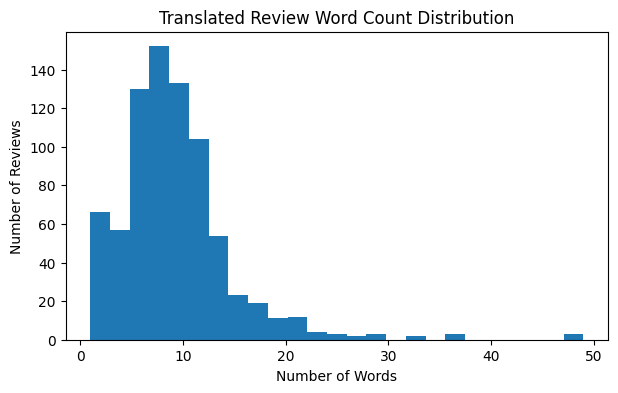

In [40]:
# Step 5.3: Plot translated review length distribution

plt.figure(figsize=(7, 4))
plt.hist(model_df["Translated_Word_Count"], bins=25)
plt.title("Translated Review Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()


### 6.2 Translated Review Length Interpretation

The translated reviews are mostly short.

The median length is **8 words**, the 75th percentile is **11 words**, and the 99th percentile is about **29.6 words**. The maximum translated review length is **49 words**.

This tells me the RNN does not need a very long sequence length. Most reviews are short customer comments, not long essays.

Decision: use this length evidence later when choosing `MAX_LEN`.


## 7. Splitting the Data Fairly

Now I split the dataset into training, validation, and test sets.

Each split has a different job:

- The **training set** teaches the model.
- The **validation set** helps me compare models and make decisions.
- The **test set** is only used at the end, after the model is chosen.

This is one of the most important parts of the workflow. If I use the test set while choosing models, then the final test result is no longer truly fair.

I also use stratification so that the Negative, Neutral, and Positive class proportions stay similar across the splits. This is supported by `train_test_split`, which allows stratified splitting [scikit-learn train_test_split].


In [41]:
# Step 6.1: Check final modelling dataset before splitting

required_columns = [
    "Review_Text",
    "Review_Translated",
    "Score_Numeric",
    "Language_Clean",
    "Sentiment_Label",
    "Sentiment"
]

missing_columns = [col for col in required_columns if col not in model_df.columns]

if len(missing_columns) == 0:
    print("model_df is ready for splitting.")
else:
    print("Missing columns:", missing_columns)

print("model_df shape:", model_df.shape)

display(model_df[required_columns].head())


model_df is ready for splitting.
model_df shape: (781, 12)


,Review_Text,Review_Translated,Score_Numeric,Language_Clean,Sentiment_Label,Sentiment
0,A beautifully bold and flavorful fusion pizza ...,A beautifully bold and flavorful fusion pizza ...,9.86,English,2,Positive
1,"A bold, beautiful marriage of flavors that exc...","A bold, beautiful marriage of flavors that exc...",9.80,English,2,Positive
2,A creative and well-executed pizza. The sambal...,A creative and well-executed pizza. The sambal...,9.40,English,2,Positive
3,A decent pizza that didn’t impress much.,A decent pizza that didn’t impress much.,5.20,English,1,Neutral
4,A delicious fusion pizza that hits all the rig...,A delicious fusion pizza that hits all the rig...,9.90,English,2,Positive


In [42]:
# Step 6.2: Check full dataset class distribution before split

full_class_counts = model_df["Sentiment"].value_counts()
full_class_percent = model_df["Sentiment"].value_counts(normalize=True) * 100

full_class_summary_df = pd.DataFrame({
    "Sentiment": full_class_counts.index,
    "Count": full_class_counts.values,
    "Percentage": full_class_percent.round(2).values
})

display(full_class_summary_df)


,Sentiment,Count,Percentage
0,Positive,338,43.28
1,Negative,260,33.29
2,Neutral,183,23.43


### 7.1 Sentiment Distribution Before Splitting

Before splitting, I check the full sentiment distribution again:

- Positive: **338** (**43.28%**)
- Negative: **260** (**33.29%**)
- Neutral: **183** (**23.43%**)

I do this before the split because I want the train, validation and test sets to preserve this pattern.

If one split accidentally had too few Neutral reviews, the validation or test score would become unfair.


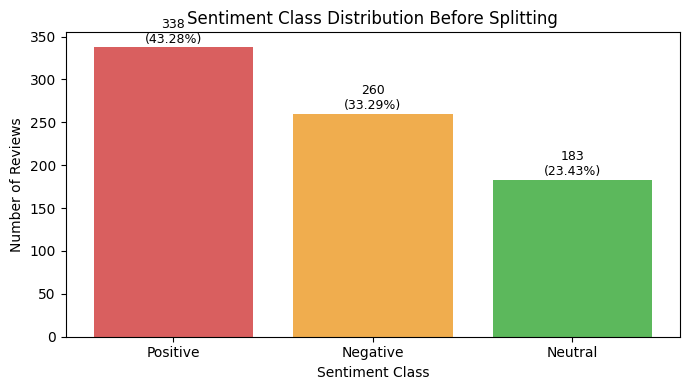

In [43]:
# Step 6.2.1: Plot sentiment class distribution before splitting
plt.figure(figsize=(7, 4))
plt.bar(
    full_class_summary_df["Sentiment"],
    full_class_summary_df["Count"],
    color=["#d95f5f", "#f0ad4e", "#5cb85c"]
)
plt.title("Sentiment Class Distribution Before Splitting")
plt.xlabel("Sentiment Class")
plt.ylabel("Number of Reviews")

for index, row in full_class_summary_df.iterrows():
    plt.text(
        index,
        row["Count"] + 5,
        f"{row['Count']}\n({row['Percentage']:.2f}%)",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()


In [44]:
# Step 6.3: Check original language distribution before split

language_counts = model_df["Language_Clean"].value_counts()
language_percent = model_df["Language_Clean"].value_counts(normalize=True) * 100

language_summary_df = pd.DataFrame({
    "Language": language_counts.index,
    "Count": language_counts.values,
    "Percentage": language_percent.round(2).values
})

display(language_summary_df)


,Language,Count,Percentage
0,English,435,55.7
1,Malay,346,44.3


### 7.2 Class and Language Check Before Splitting

Before creating train, validation and test sets, I check both sentiment and language distribution.

This helps me confirm what the model will need to learn: the dataset is mostly Positive, but still has meaningful Negative and Neutral examples. It also still contains both English and Malay-origin reviews.


In [45]:
# Step 6.4: Train / validation / test split

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    model_df,
    test_size=0.30,
    random_state=SEED,
    stratify=model_df["Sentiment_Label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["Sentiment_Label"]
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))


Train rows: 546
Validation rows: 117
Test rows: 118


In [46]:
# Step 6.5: Check sentiment balance in each split

def split_sentiment_summary(split_name, data):
    counts = data["Sentiment"].value_counts()
    percentages = data["Sentiment"].value_counts(normalize=True) * 100
    
    return {
        "Split": split_name,
        "Total Rows": len(data),
        "Negative Count": counts.get("Negative", 0),
        "Neutral Count": counts.get("Neutral", 0),
        "Positive Count": counts.get("Positive", 0),
        "Negative %": round(percentages.get("Negative", 0), 2),
        "Neutral %": round(percentages.get("Neutral", 0), 2),
        "Positive %": round(percentages.get("Positive", 0), 2)
    }

split_summary_df = pd.DataFrame([
    split_sentiment_summary("Train", train_df),
    split_sentiment_summary("Validation", val_df),
    split_sentiment_summary("Test", test_df)
])

display(split_summary_df)


,Split,Total Rows,Negative Count,Neutral Count,Positive Count,Negative %,Neutral %,Positive %
0,Train,546,182,128,236,33.33,23.44,43.22
1,Validation,117,39,27,51,33.33,23.08,43.59
2,Test,118,39,28,51,33.05,23.73,43.22


### 7.3 Split Size Checkpoint

The split creates **546 training rows**, **117 validation rows**, and **118 test rows**.

This gives enough data for training while keeping separate validation and test sets. The validation set is for model decisions; the test set stays untouched until the final evaluation.


In [47]:
# Step 6.6: Check original language balance in each split

def split_language_summary(split_name, data):
    counts = data["Language_Clean"].value_counts()
    
    return {
        "Split": split_name,
        "Total Rows": len(data),
        "English": counts.get("English", 0),
        "Malay": counts.get("Malay", 0)
    }

language_split_df = pd.DataFrame([
    split_language_summary("Train", train_df),
    split_language_summary("Validation", val_df),
    split_language_summary("Test", test_df)
])

display(language_split_df)


,Split,Total Rows,English,Malay
0,Train,546,302,244
1,Validation,117,57,60
2,Test,118,76,42


### 7.4 Split Balance Output Check

The split tables show that each set still contains all three sentiment classes and both language groups.

This is important because a validation or test set missing a class would make the evaluation misleading.


In [48]:
# Step 6.7: Check duplicate review leakage across splits

train_reviews = set(train_df["Review_Text"].str.lower().str.strip())
val_reviews = set(val_df["Review_Text"].str.lower().str.strip())
test_reviews = set(test_df["Review_Text"].str.lower().str.strip())

train_val_overlap = train_reviews.intersection(val_reviews)
train_test_overlap = train_reviews.intersection(test_reviews)
val_test_overlap = val_reviews.intersection(test_reviews)

print("Train-Val duplicate overlap:", len(train_val_overlap))
print("Train-Test duplicate overlap:", len(train_test_overlap))
print("Val-Test duplicate overlap:", len(val_test_overlap))


Train-Val duplicate overlap: 0
Train-Test duplicate overlap: 0
Val-Test duplicate overlap: 0


### 7.5 Leakage Checkpoint

The duplicate-overlap output is **0** across train-validation, train-test and validation-test.

This is a very important result. It means the model will not train on a review and then later be evaluated on the same review in another split.


In [49]:
# Step 6.8: Store split information for later summary

split_info = {
    "train_rows": len(train_df),
    "validation_rows": len(val_df),
    "test_rows": len(test_df),
    "split_strategy": "70/15/15 stratified by 3-class sentiment label"
}

print(split_info)


{'train_rows': 546, 'validation_rows': 117, 'test_rows': 118, 'split_strategy': '70/15/15 stratified by 3-class sentiment label'}


### 7.6 Split Interpretation

The split is balanced and clean.

The dataset is split into:

- Train: **546 rows**
- Validation: **117 rows**
- Test: **118 rows**

The class percentages stay very similar across the three splits. For example, Positive stays around **43%**, Negative around **33%**, and Neutral around **23%** in each split.

The duplicate leakage check is also clean:

- Train-Val overlap: **0**
- Train-Test overlap: **0**
- Val-Test overlap: **0**

This is important because the model should not see the same review in training and then be tested on it later.

Decision: use the training set for learning, the validation set for model selection, and the test set only at the end.


## 8. Turning Text into Numbers

Now the dataset is clean enough to become model input.

The RNN cannot read words directly, so I need to convert each review into numbers.

This preprocessing step has three jobs:

1. clean the text consistently;
2. fit a tokenizer on training text only;
3. pad every review to the same length.

The training-only rule is very important. If the tokenizer learns vocabulary from validation or test reviews, then the model has already received information from unseen data before evaluation.

So this section is not just technical preparation. It protects the fairness of the experiment.


In [50]:
# Step 7.1: Clean translated text

import re
import html

def clean_review_text(text):
    text = html.unescape(str(text))
    text = text.lower()
    
    # Remove URLs and HTML tags
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"<.*?>", " ", text)
    
    # Keep letters, numbers, spaces, apostrophes, ! and ?
    text = re.sub(r"[^a-zA-Z0-9\s!?']", " ", text)
    
    # Remove repeated spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text

train_df["Text_Clean"] = train_df["Review_Translated"].apply(clean_review_text)
val_df["Text_Clean"] = val_df["Review_Translated"].apply(clean_review_text)
test_df["Text_Clean"] = test_df["Review_Translated"].apply(clean_review_text)

display(train_df[["Review_Translated", "Text_Clean", "Sentiment"]].head())


,Review_Translated,Text_Clean,Sentiment
367,This pizza is strange and not tasty.,this pizza is strange and not tasty,Negative
338,This fusion pizza is ok but nothing interestin...,this fusion pizza is ok but nothing interestin...,Neutral
341,This fusion pizza makes me feel satisfied.,this fusion pizza makes me feel satisfied,Positive
530,Sambal was mild and didn’t pack a punch.,sambal was mild and didn t pack a punch,Neutral
131,Delicious.,delicious,Positive


### 8.1 Choosing the Sequence Length

Before training the RNN, I need to decide how many words from each review the model should read.

This matters because every review must become the same length.

If the length is too short, longer reviews may be cut off and the model may miss important sentiment words. This is especially risky for mixed reviews, where the important part may appear after words like "but" or "however".

If the length is too long, most reviews will contain too much padding, which makes training less efficient.

So I check the word-count distribution using the **training set only**. This keeps the decision fair because validation and test data should not influence preprocessing choices.


In [51]:
# Step 7.3: Choose robust MAX_LEN using training set only

train_df["Clean_Word_Count"] = train_df["Text_Clean"].str.split().apply(len)
val_df["Clean_Word_Count"] = val_df["Text_Clean"].str.split().apply(len)
test_df["Clean_Word_Count"] = test_df["Text_Clean"].str.split().apply(len)

print("Training clean word count summary:")
display(train_df["Clean_Word_Count"].describe())

length_percentiles = pd.DataFrame({
    "Percentile": ["50%", "75%", "90%", "95%", "99%"],
    "Word Count": [
        np.percentile(train_df["Clean_Word_Count"], 50),
        np.percentile(train_df["Clean_Word_Count"], 75),
        np.percentile(train_df["Clean_Word_Count"], 90),
        np.percentile(train_df["Clean_Word_Count"], 95),
        np.percentile(train_df["Clean_Word_Count"], 99)
    ]
})

display(length_percentiles)

MAX_LEN = int(np.ceil(np.percentile(train_df["Clean_Word_Count"], 99)))


Training clean word count summary:


count    546.000000
mean       9.254579
std        6.108741
min        1.000000
25%        6.000000
50%        8.000000
75%       11.000000
max       52.000000
Name: Clean_Word_Count, dtype: float64

,Percentile,Word Count
0,50%,8.00
1,75%,11.00
2,90%,15.00
3,95%,20.00
4,99%,32.55


### 8.2 Turning the Length Check into a Final Input Size

The percentile table gives me the evidence, but I still need to turn that evidence into one fixed input length.

The 99th percentile is about **32.55 words**, so most training reviews are around 33 words or shorter. If I use exactly 33, the model may still cut off a few words from the longest normal reviews. If I go too much higher, the short reviews will get too much padding.

So I use **35 words** as a small safety buffer. It is just above the 99th percentile, which means it keeps almost all normal review content while still staying compact.


In [52]:
# Robust choice for longer mixed reviews
MAX_LEN = max(MAX_LEN, 35)

print("Chosen robust MAX_LEN:", MAX_LEN)


Chosen robust MAX_LEN: 35


### 8.3 Sequence Length Decision

The training word-count analysis shows:

- Median: **8 words**
- 75th percentile: **11 words**
- 90th percentile: **15 words**
- 95th percentile: **20 words**
- 99th percentile: about **32.55 words**

I set `MAX_LEN = 35`.

This is slightly above the 99th percentile, so it keeps almost all normal training reviews. It also gives a small buffer for longer or mixed reviews where important sentiment words may appear near the end.

Decision: use 35 words as the fixed input length.


### 8.4 Choosing the Vocabulary Size

Next, I choose how many words the tokenizer is allowed to keep.

I set `MAX_WORDS = 5000` as an upper limit. This does not mean the dataset has 5000 important words. It simply means the tokenizer can keep up to the top 5000 words if needed.

This is a safe limit because the dataset is small, and I do not want the embedding layer to be too restrictive.


In [53]:
# Step 7.4: Fit tokenizer on training text only

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 5000

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(train_df["Text_Clean"])

print("Tokenizer fitted on training text only.")
print("Vocabulary size found:", len(tokenizer.word_index))


Tokenizer fitted on training text only.
Vocabulary size found: 651


### 8.5 Tokenizer Outcome

The tokenizer found **651 unique words** from the training reviews.

Since `MAX_WORDS = 5000`, the limit is safely above the actual vocabulary size. This means the vocabulary cap is not cutting off useful training words.

The padded sequence shapes are:

- `X_train_pad`: **(546, 35)**
- `X_val_pad`: **(117, 35)**
- `X_test_pad`: **(118, 35)**

This confirms that every review is now represented as a 35-token sequence.

Decision: continue to modelling using these padded sequences.


In [54]:
# Step 7.5: Convert text into padded sequences

X_train_seq = tokenizer.texts_to_sequences(train_df["Text_Clean"])
X_val_seq = tokenizer.texts_to_sequences(val_df["Text_Clean"])
X_test_seq = tokenizer.texts_to_sequences(test_df["Text_Clean"])

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y_train = train_df["Sentiment_Label"].values
y_val = val_df["Sentiment_Label"].values
y_test = test_df["Sentiment_Label"].values

print("X_train_pad shape:", X_train_pad.shape)
print("X_val_pad shape:", X_val_pad.shape)
print("X_test_pad shape:", X_test_pad.shape)

print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)
print("y_test shape:", y_test.shape)


X_train_pad shape: (546, 35)
X_val_pad shape: (117, 35)
X_test_pad shape: (118, 35)
y_train shape: (546,)
y_val shape: (117,)
y_test shape: (118,)


### 8.6 Padded Sequence Output Check

The padded sequence shapes show that all reviews have been converted into fixed-length numeric inputs.

Each review is now represented using **35 token positions**, so the RNN can process every batch consistently.


In [55]:
# Step 7.6: Check one tokenised example

sample_index = 0

print("Original translated review:")
print(train_df["Review_Translated"].iloc[sample_index])

print("\nCleaned review:")
print(train_df["Text_Clean"].iloc[sample_index])

print("\nToken sequence:")
print(X_train_seq[sample_index])

print("\nPadded sequence:")
print(X_train_pad[sample_index])

print("\nSentiment:")
print(y_train[sample_index], "-", train_df["Sentiment"].iloc[sample_index])


Original translated review:
This pizza is strange and not tasty.

Cleaned review:
this pizza is strange and not tasty

Token sequence:
[14, 4, 5, 97, 3, 12, 30]

Padded sequence:
[14  4  5 97  3 12 30  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0]

Sentiment:
0 - Negative


### 8.7 Tokenisation Example Interpretation

The example shows how a review becomes numbers.

The sentence:

> "This pizza is strange and not tasty."

becomes a list of token IDs. After that, zeros are added at the end until the sequence reaches length 35.

Those zeros are padding. They do not mean extra words. They simply help every review have the same shape so the RNN can process them in batches.

This confirms that the preprocessing pipeline is working correctly.


## 9. Creating Hard Review Subsets

Overall accuracy is useful, but it does not tell me whether the model struggles with special types of reviews.

So I create two harder groups:

1. **Long reviews**  
   These may contain more details and more than one opinion.

2. **Contrast reviews**  
   These contain words like "but", "yet", "however", or "although". These words can change the sentiment direction.

For example:

> "The crust looked nice, but the pizza tasted stale."

The first half sounds positive, but the second half is negative. A good model should pay attention to that change.


In [56]:
# Step 8.1: Create long-review and contrast-review flags

contrast_words_pattern = r"\b(but|yet|although|though|however|not|unless|despite|even though)\b"

long_review_cutoff = np.percentile(train_df["Clean_Word_Count"], 75)

val_df["Is_Long_Review"] = val_df["Clean_Word_Count"] >= long_review_cutoff
test_df["Is_Long_Review"] = test_df["Clean_Word_Count"] >= long_review_cutoff

val_df["Has_Contrast_Word"] = val_df["Text_Clean"].str.contains(
    contrast_words_pattern,
    regex=True
)

test_df["Has_Contrast_Word"] = test_df["Text_Clean"].str.contains(
    contrast_words_pattern,
    regex=True
)

print("Long review cutoff:", long_review_cutoff)

print("\nValidation long reviews:", val_df["Is_Long_Review"].sum())
print("Validation contrast reviews:", val_df["Has_Contrast_Word"].sum())

print("\nTest long reviews:", test_df["Is_Long_Review"].sum())
print("Test contrast reviews:", test_df["Has_Contrast_Word"].sum())


Long review cutoff: 11.0

Validation long reviews: 37
Validation contrast reviews: 25

Test long reviews: 46
Test contrast reviews: 31


In [57]:
# Step 8.2: Create validation subset arrays

val_long_indices = val_df["Is_Long_Review"].values
val_contrast_indices = val_df["Has_Contrast_Word"].values

X_val_long = X_val_pad[val_long_indices]
y_val_long = y_val[val_long_indices]

X_val_contrast = X_val_pad[val_contrast_indices]
y_val_contrast = y_val[val_contrast_indices]

print("Long validation shape:", X_val_long.shape)
print("Contrast validation shape:", X_val_contrast.shape)


Long validation shape: (37, 35)
Contrast validation shape: (25, 35)


### 9.1 Hard Subset Size Check

The hard subsets are now separated from the normal validation and test sets.

This lets me ask a sharper question later: does the model only perform well overall, or can it also handle longer and contrast-style reviews?


In [58]:
# Step 8.3: Check sentiment distribution in long and contrast validation subsets

long_val_summary = val_df[val_df["Is_Long_Review"]]["Sentiment"].value_counts()
contrast_val_summary = val_df[val_df["Has_Contrast_Word"]]["Sentiment"].value_counts()

print("Long validation sentiment distribution:")
display(long_val_summary)

print("\nContrast validation sentiment distribution:")
display(contrast_val_summary)


Long validation sentiment distribution:


Sentiment
Positive    26
Neutral      8
Negative     3
Name: count, dtype: int64


Contrast validation sentiment distribution:


Sentiment
Negative    11
Neutral     11
Positive     3
Name: count, dtype: int64

In [59]:
# Step 8.4: View examples from hard validation subsets

print("Long review examples:")
display(
    val_df[val_df["Is_Long_Review"]][
        ["Review_Translated", "Text_Clean", "Clean_Word_Count", "Sentiment"]
    ].head(5)
)

print("\nContrast review examples:")
display(
    val_df[val_df["Has_Contrast_Word"]][
        ["Review_Translated", "Text_Clean", "Clean_Word_Count", "Sentiment"]
    ].head(5)
)


Long review examples:


,Review_Translated,Text_Clean,Clean_Word_Count,Sentiment
642,The texture of the bread and the toppings are ...,the texture of the bread and the toppings are ...,11,Positive
343,"This fusion pizza tastes ok, but not amazing. ...",this fusion pizza tastes ok but not amazing sa...,19,Neutral
211,The combination of sambal and mayo makes this ...,the combination of sambal and mayo makes this ...,11,Positive
576,"Savory, spicy, and utterly unique. The satay c...",savory spicy and utterly unique the satay chic...,13,Positive
247,Love at first bite! The satay chicken was juic...,love at first bite! the satay chicken was juic...,13,Positive



Contrast review examples:


,Review_Translated,Text_Clean,Clean_Word_Count,Sentiment
370,This pizza tastes strange and not good.,this pizza tastes strange and not good,7,Negative
343,"This fusion pizza tastes ok, but not amazing. ...",this fusion pizza tastes ok but not amazing sa...,19,Neutral
292,"Not bad, but the fusion didn’t quite hit the m...",not bad but the fusion didn t quite hit the ma...,13,Neutral
698,The pizza was decent but lacked excitement.,the pizza was decent but lacked excitement,7,Neutral
520,Sambal kick was intense but enjoyable. Mayonna...,sambal kick was intense but enjoyable mayonnai...,17,Neutral


### 9.2 Hard Review Example Check

The examples make the hard subsets feel real instead of just being numbers.

Long reviews contain more details, while contrast reviews often change direction after words like "but" or "not". These are exactly the types of reviews where a sequence model should be tested more carefully.


### 9.3 Hard Subset Interpretation

I define long reviews using the 75th percentile of training word count, which gives a cutoff of **11 words**.

The harder subsets are:

- Validation long reviews: **37**
- Validation contrast reviews: **25**
- Test long reviews: **46**
- Test contrast reviews: **31**

These subsets help me look beyond normal accuracy.

If a model performs well overall but fails on long or contrast reviews, then it may not be reliable for real customer feedback where people often mix praise and complaints.

Decision: track long-review and contrast-review performance during model improvement.


## 10. SimpleRNN Baseline

Now I start modelling.

I begin with SimpleRNN because I need a baseline. A baseline is like the first attempt. It may not be the best model, but it gives me something fair to compare against.

The SimpleRNN reads the review sequence from start to end. Before it reads the sequence, the Embedding layer turns token IDs into trainable word vectors.

My expectation is simple:

The SimpleRNN should learn obvious sentiment words such as "delicious", "bad", "bland", or "amazing". But it may struggle with longer reviews and mixed reviews because SimpleRNNs can forget earlier context more easily than gated models like LSTM or GRU.


In [60]:
# Step 9.1: Import modelling tools

import tensorflow as tf
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

tf.random.set_seed(SEED)

EPOCHS = 15
BATCH_SIZE = 32
NUM_CLASSES = 3
LABEL_NAMES = ["Negative", "Neutral", "Positive"]

print("Modelling tools imported.")
print("EPOCHS:", EPOCHS)
print("BATCH_SIZE:", BATCH_SIZE)
print("NUM_CLASSES:", NUM_CLASSES)


Modelling tools imported.
EPOCHS: 15
BATCH_SIZE: 32
NUM_CLASSES: 3


### 10.1 Why I Chose These Model Hyperparameters

Before building the RNN models, I need a sensible starting point.

The training set has only **546 reviews**, so I do not want to begin with a very large model. A model that is too large may memorise the training reviews instead of learning general sentiment patterns.


### 10.2 Hyperparameter Choices

I use an embedding size of `64`. The training vocabulary has **651 words**, so a very large embedding space is unnecessary.

The first SimpleRNN, LSTM, GRU and BiGRU models start with `32` recurrent units. This is a reasonable size because the reviews are short and the final sequence length is only **35 words**.

For dropout, I use `0.3` for the simpler models and `0.4` for the first BiGRU. BiGRU reads the review in both directions, so it has more capacity and needs slightly stronger regularisation.

I use Adam with learning rate `0.001` because it is a stable default for neural network training.


### 10.3 Hyperparameter Plan

These values are starting choices, not final answers.

I begin with moderate model sizes because the dataset is small and the reviews are short. If the early models show that more sequence context is useful, I will then test a small set of hyperparameter changes instead of running a large random search.

This keeps the workflow fair: first compare the model types, then tune only the most promising direction based on validation evidence.


In [61]:
# Step 9.2: Build SimpleRNN baseline model

def build_simple_rnn_model():
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    
    model = Sequential()
    
    model.add(Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        input_length=MAX_LEN
    ))
    
    model.add(SimpleRNN(32))
    model.add(Dropout(0.3))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(NUM_CLASSES, activation="softmax"))
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

simple_rnn_baseline = build_simple_rnn_model()

simple_rnn_baseline.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 35, 64)            320000    
                                                                 
 simple_rnn (SimpleRNN)      (None, 32)                3104      
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense (Dense)               (None, 16)                528       
                                                                 
 dense_1 (Dense)             (None, 3)                 51        
                                                                 
Total params: 323,683
Trainable params: 323,683
Non-trainable params: 0
_________________________________________________________________


In [62]:
# Step 9.3: Evaluation function for 3-class classification

def evaluate_three_class_model(model, X_data, y_true, dataset_name):
    y_prob = model.predict(X_data, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)
    
    accuracy = accuracy_score(y_true, y_pred)
    
    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        average="macro",
        zero_division=0
    )
    
    weighted_precision, weighted_recall, weighted_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        average="weighted",
        zero_division=0
    )
    
    class_precision, class_recall, class_f1, class_support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        average=None,
        zero_division=0
    )
    
    results = {
        "Dataset": dataset_name,
        "Accuracy": accuracy,
        "Macro Precision": macro_precision,
        "Macro Recall": macro_recall,
        "Macro F1": macro_f1,
        "Weighted Precision": weighted_precision,
        "Weighted Recall": weighted_recall,
        "Weighted F1": weighted_f1,
        "Negative Recall": class_recall[0],
        "Neutral Recall": class_recall[1],
        "Positive Recall": class_recall[2]
    }
    
    return results, y_pred, y_prob

print("Evaluation function created.")


Evaluation function created.


In [63]:
# Step 9.4: Train SimpleRNN baseline using original translated reviews only

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

simple_rnn_baseline_history = simple_rnn_baseline.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

simple_rnn_baseline_training_time = time.time() - start_time

print("SimpleRNN baseline training time:", round(simple_rnn_baseline_training_time, 2), "seconds")
print("Epochs run:", len(simple_rnn_baseline_history.history["loss"]))


Epoch 1/15
18/18 [==============================] - 2s 39ms/step - loss: 1.0765 - accuracy: 0.4377 - val_loss: 1.0510 - val_accuracy: 0.5983
Epoch 2/15
18/18 [==============================] - 0s 28ms/step - loss: 0.9803 - accuracy: 0.5531 - val_loss: 0.9092 - val_accuracy: 0.5897
Epoch 3/15
18/18 [==============================] - 0s 25ms/step - loss: 0.7852 - accuracy: 0.6868 - val_loss: 0.7080 - val_accuracy: 0.7521
Epoch 4/15
18/18 [==============================] - 0s 27ms/step - loss: 0.5957 - accuracy: 0.7894 - val_loss: 0.7343 - val_accuracy: 0.6581
Epoch 5/15
18/18 [==============================] - 0s 27ms/step - loss: 0.4462 - accuracy: 0.8608 - val_loss: 0.6562 - val_accuracy: 0.7179
Epoch 6/15
18/18 [==============================] - 1s 32ms/step - loss: 0.3335 - accuracy: 0.9048 - val_loss: 0.6253 - val_accuracy: 0.7692
Epoch 7/15
18/18 [==============================] - 0s 27ms/step - loss: 0.2515 - accuracy: 0.9341 - val_loss: 0.5747 - val_accuracy: 0.8120
Epoch 8/15
18

In [64]:
# Step 9.5: Evaluate SimpleRNN baseline

simple_rnn_train_results, simple_rnn_train_pred, simple_rnn_train_prob = evaluate_three_class_model(
    simple_rnn_baseline,
    X_train_pad,
    y_train,
    dataset_name="Train"
)

simple_rnn_val_results, simple_rnn_val_pred, simple_rnn_val_prob = evaluate_three_class_model(
    simple_rnn_baseline,
    X_val_pad,
    y_val,
    dataset_name="Validation"
)

simple_rnn_long_val_results, simple_rnn_long_val_pred, simple_rnn_long_val_prob = evaluate_three_class_model(
    simple_rnn_baseline,
    X_val_long,
    y_val_long,
    dataset_name="Long Validation"
)

simple_rnn_contrast_val_results, simple_rnn_contrast_val_pred, simple_rnn_contrast_val_prob = evaluate_three_class_model(
    simple_rnn_baseline,
    X_val_contrast,
    y_val_contrast,
    dataset_name="Contrast Validation"
)

simple_rnn_baseline_results_df = pd.DataFrame([
    simple_rnn_train_results,
    simple_rnn_val_results,
    simple_rnn_long_val_results,
    simple_rnn_contrast_val_results
])

display(simple_rnn_baseline_results_df.round(4))


,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative Recall,Neutral Recall,Positive Recall
0,Train,0.9817,0.9823,0.9787,0.9804,0.9818,0.9817,0.9817,0.9835,0.9609,0.9915
1,Validation,0.8291,0.8201,0.8224,0.8209,0.8303,0.8291,0.8294,0.8462,0.7778,0.8431
2,Long Validation,0.8108,0.6817,0.7254,0.6995,0.8222,0.8108,0.8153,0.6667,0.6250,0.8846
3,Contrast Validation,0.7600,0.6897,0.6566,0.6651,0.7505,0.7600,0.7499,0.9091,0.7273,0.3333


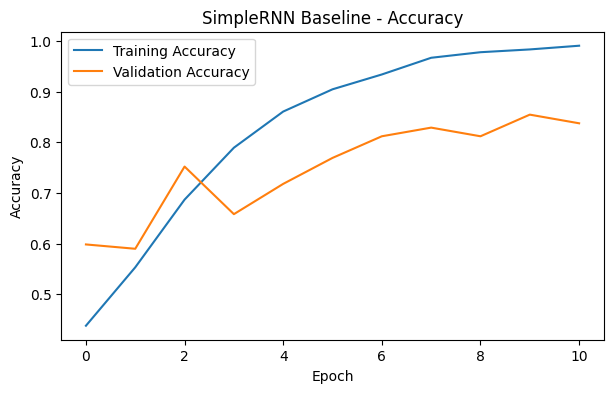

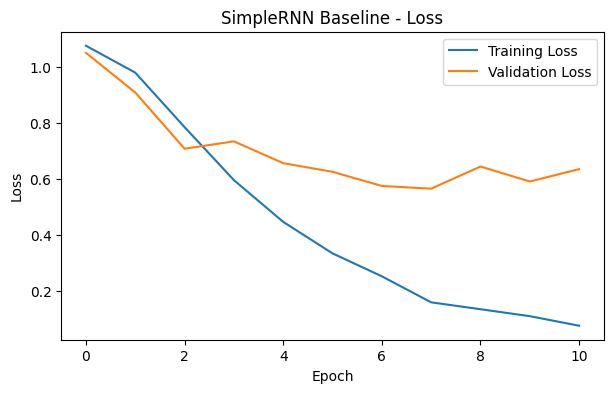

In [65]:
# Step 9.6: Plot SimpleRNN baseline training curves

plt.figure(figsize=(7, 4))
plt.plot(simple_rnn_baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(simple_rnn_baseline_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("SimpleRNN Baseline - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(simple_rnn_baseline_history.history["loss"], label="Training Loss")
plt.plot(simple_rnn_baseline_history.history["val_loss"], label="Validation Loss")
plt.title("SimpleRNN Baseline - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [66]:
# Step 9.7: SimpleRNN baseline validation confusion matrix

simple_rnn_val_cm = confusion_matrix(
    y_val,
    simple_rnn_val_pred,
    labels=[0, 1, 2]
)

simple_rnn_val_cm_df = pd.DataFrame(
    simple_rnn_val_cm,
    index=["Actual Negative", "Actual Neutral", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Neutral", "Predicted Positive"]
)

print("SimpleRNN Baseline Validation Confusion Matrix:")
display(simple_rnn_val_cm_df)

print("SimpleRNN Baseline Validation Classification Report:")
print(
    classification_report(
        y_val,
        simple_rnn_val_pred,
        target_names=LABEL_NAMES,
        zero_division=0
    )
)


SimpleRNN Baseline Validation Confusion Matrix:


,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,33,3,3
Actual Neutral,3,21,3
Actual Positive,5,3,43


SimpleRNN Baseline Validation Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.85      0.83        39
     Neutral       0.78      0.78      0.78        27
    Positive       0.88      0.84      0.86        51

    accuracy                           0.83       117
   macro avg       0.82      0.82      0.82       117
weighted avg       0.83      0.83      0.83       117



### 10.4 SimpleRNN Baseline: Main Result

The SimpleRNN baseline gives me a useful starting point.

On validation data, it gets:

- Accuracy: **82.91%**
- Macro F1: **0.8209**
- Weighted F1: **0.8294**

The training macro F1 is much higher at **0.9804**, so the model has learned the training reviews very strongly. The validation score is lower, which tells me the model is not generalising perfectly yet.


### 10.5 SimpleRNN Baseline: Weakness Found

The harder subsets make the weakness clearer:

- Long validation macro F1: **0.6995**
- Contrast validation macro F1: **0.6651**

So the baseline is decent, but it loses performance when the review is longer or when the sentence has mixed direction.

Decision: test data generation and stronger sequence models next, instead of changing the model randomly.


### 10.6 Moving from Baseline to Improvement

The baseline gives me the first clue.

It can classify many normal reviews, but it struggles with contrast reviews. So the next improvement idea is not random: I want to see whether creating extra training examples from the existing reviews can help the model see more sentence patterns.

The rule is still strict: generated samples are created from the training set only. Validation and test reviews stay untouched.


## 11. Generating More Training Data from Reviews

The assignment asks whether I can engineer the given data to create more training examples.

For text, this can be done by splitting reviews into smaller parts.

But I need to be careful.

If I split this sentence into single words:

> "The pizza was not good"

the word "good" alone looks positive, even though the full sentence is negative. So word splitting can create noisy labels.

That is why I test several methods instead of blindly assuming more data is better:

- word split;
- phrase-window split;
- sentence split;
- prefix split.

All generated samples are created from the training set only, so validation and test data remain fair.


In [67]:
# Step 10.1: Create data-generation split functions

def word_split(text):
    clean_text = clean_review_text(text)
    words = clean_text.split()
    
    return [word for word in words if len(word) > 1]


def phrase_window_split(text, window_size=3):
    clean_text = clean_review_text(text)
    words = clean_text.split()
    
    if len(words) < window_size:
        return []
    
    phrases = []
    
    for i in range(len(words) - window_size + 1):
        phrase = " ".join(words[i:i + window_size])
        phrases.append(phrase)
    
    return phrases


def sentence_split(text):
    text = str(text)
    sentences = re.split(r"[.!?]+", text)
    
    cleaned_sentences = []
    
    for sentence in sentences:
        cleaned_sentence = clean_review_text(sentence)
        
        if len(cleaned_sentence.split()) >= 2:
            cleaned_sentences.append(cleaned_sentence)
    
    return cleaned_sentences


def prefix_split(text, min_words=3):
    clean_text = clean_review_text(text)
    words = clean_text.split()
    
    if len(words) < min_words:
        return []
    
    prefixes = []
    
    for i in range(min_words, len(words) + 1):
        prefix = " ".join(words[:i])
        prefixes.append(prefix)
    
    return prefixes

print("All split functions created.")


All split functions created.


**Small checkpoint:** The split functions are ready, so I can now test which generated text still keeps meaning.


In [68]:
# Step 10.2: Test split methods on one training review

example_text = train_df["Review_Translated"].iloc[0]

print("Original translated review:")
print(example_text)

print("\nWord split:")
print(word_split(example_text)[:10])

print("\nPhrase-window split:")
print(phrase_window_split(example_text)[:10])

print("\nSentence split:")
print(sentence_split(example_text))

print("\nPrefix split:")
print(prefix_split(example_text)[:10])


Original translated review:
This pizza is strange and not tasty.

Word split:
['this', 'pizza', 'is', 'strange', 'and', 'not', 'tasty']

Phrase-window split:
['this pizza is', 'pizza is strange', 'is strange and', 'strange and not', 'and not tasty']

Sentence split:
['this pizza is strange and not tasty']

Prefix split:
['this pizza is', 'this pizza is strange', 'this pizza is strange and', 'this pizza is strange and not', 'this pizza is strange and not tasty']


**What this example shows:** Word splits lose context quickly, while sentence and phrase splits preserve more review meaning.


In [69]:
# Step 10.3: Create generated training data function

def create_generated_training_data(train_data, split_method=None, method_name="Original Only"):
    rows = []
    
    for _, row in train_data.iterrows():
        original_text = row["Text_Clean"]
        raw_text = row["Review_Translated"]
        label = row["Sentiment_Label"]
        sentiment = row["Sentiment"]
        
        # Always keep the original full review
        rows.append({
            "Text": original_text,
            "Sentiment_Label": label,
            "Sentiment": sentiment,
            "Source": "Original",
            "Method": method_name
        })
        
        # Generate extra training samples only from training data
        if split_method is not None:
            generated_texts = split_method(raw_text)
            
            for generated_text in generated_texts:
                generated_text = clean_review_text(generated_text)
                
                if generated_text != "" and generated_text != original_text:
                    rows.append({
                        "Text": generated_text,
                        "Sentiment_Label": label,
                        "Sentiment": sentiment,
                        "Source": "Generated",
                        "Method": method_name
                    })
    
    return pd.DataFrame(rows)

print("Generated training data function created.")


Generated training data function created.


In [70]:
# Step 10.4: Create generated training datasets only
# Original Only baseline was already trained in Step 9, so we do not retrain it here.

train_word = create_generated_training_data(
    train_df,
    split_method=word_split,
    method_name="Original + Word Split"
)

train_phrase = create_generated_training_data(
    train_df,
    split_method=lambda text: phrase_window_split(text, window_size=3),
    method_name="Original + Phrase Window"
)

train_sentence = create_generated_training_data(
    train_df,
    split_method=sentence_split,
    method_name="Original + Sentence Split"
)

train_prefix = create_generated_training_data(
    train_df,
    split_method=prefix_split,
    method_name="Original + Prefix Split"
)

generated_datasets = {
    "Original + Word Split": train_word,
    "Original + Phrase Window": train_phrase,
    "Original + Sentence Split": train_sentence,
    "Original + Prefix Split": train_prefix
}

for name, data in generated_datasets.items():
    print(name, "rows:", len(data))


Original + Word Split rows: 5383
Original + Phrase Window rows: 4509
Original + Sentence Split rows: 822
Original + Prefix Split rows: 4022


In [71]:
# Step 10.5: Summarise generated training datasets

generation_summary = []

for name, data in generated_datasets.items():
    source_counts = data["Source"].value_counts()
    sentiment_counts = data["Sentiment"].value_counts()
    sentiment_percent = data["Sentiment"].value_counts(normalize=True) * 100
    
    generation_summary.append({
        "Training Dataset": name,
        "Total Rows": len(data),
        "Original Rows": source_counts.get("Original", 0),
        "Generated Rows": source_counts.get("Generated", 0),
        "Negative Rows": sentiment_counts.get("Negative", 0),
        "Neutral Rows": sentiment_counts.get("Neutral", 0),
        "Positive Rows": sentiment_counts.get("Positive", 0),
        "Negative %": round(sentiment_percent.get("Negative", 0), 2),
        "Neutral %": round(sentiment_percent.get("Neutral", 0), 2),
        "Positive %": round(sentiment_percent.get("Positive", 0), 2)
    })

generation_summary_df = pd.DataFrame(generation_summary)

display(generation_summary_df)


,Training Dataset,Total Rows,Original Rows,Generated Rows,Negative Rows,Neutral Rows,Positive Rows,Negative %,Neutral %,Positive %
0,Original + Word Split,5383,546,4837,1415,1283,2685,26.29,23.83,49.88
1,Original + Phrase Window,4509,546,3963,1086,1076,2347,24.09,23.86,52.05
2,Original + Sentence Split,822,546,276,227,204,391,27.62,24.82,47.57
3,Original + Prefix Split,4022,546,3476,926,974,2122,23.02,24.22,52.76


**Before training them:** This table shows how much each generation method expands the original training set.


In [72]:
# Step 10.6: Prepare generated datasets for modelling

def prepare_generated_dataset(generated_df):
    X_text = generated_df["Text"].tolist()
    y = generated_df["Sentiment_Label"].astype(int).values
    
    X_seq = tokenizer.texts_to_sequences(X_text)
    
    X_pad = pad_sequences(
        X_seq,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )
    
    return X_pad, y


prepared_generated_data = {}

for name, data in generated_datasets.items():
    X_gen, y_gen = prepare_generated_dataset(data)
    
    prepared_generated_data[name] = {
        "X": X_gen,
        "y": y_gen
    }
    
    print(name)
    print("X shape:", X_gen.shape)
    print("y shape:", y_gen.shape)
    print("-" * 50)


Original + Word Split
X shape: (5383, 35)
y shape: (5383,)
--------------------------------------------------
Original + Phrase Window
X shape: (4509, 35)
y shape: (4509,)
--------------------------------------------------
Original + Sentence Split
X shape: (822, 35)
y shape: (822,)
--------------------------------------------------
Original + Prefix Split
X shape: (4022, 35)
y shape: (4022,)
--------------------------------------------------


**Ready for comparison:** Every generated dataset is now tokenised and padded using the same validation set.


In [73]:
# Step 10.7: Train one SimpleRNN experiment

def train_simple_rnn_experiment(dataset_name, X_train_model, y_train_model):
    print("=" * 70)
    print("Training:", dataset_name)
    print("=" * 70)
    
    model = build_simple_rnn_model()
    
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
    
    start_time = time.time()
    
    history = model.fit(
        X_train_model,
        y_train_model,
        validation_data=(X_val_pad, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )
    
    training_time = time.time() - start_time
    
    val_results, val_pred, val_prob = evaluate_three_class_model(
        model,
        X_val_pad,
        y_val,
        dataset_name="Validation"
    )
    
    long_results, long_pred, long_prob = evaluate_three_class_model(
        model,
        X_val_long,
        y_val_long,
        dataset_name="Long Validation"
    )
    
    contrast_results, contrast_pred, contrast_prob = evaluate_three_class_model(
        model,
        X_val_contrast,
        y_val_contrast,
        dataset_name="Contrast Validation"
    )
    
    result_row = {
        "Training Dataset": dataset_name,
        "Training Rows": len(X_train_model),
        "Epochs Run": len(history.history["loss"]),
        "Training Time (sec)": round(training_time, 2),
        "Validation Accuracy": val_results["Accuracy"],
        "Validation Macro F1": val_results["Macro F1"],
        "Validation Weighted F1": val_results["Weighted F1"],
        "Negative Recall": val_results["Negative Recall"],
        "Neutral Recall": val_results["Neutral Recall"],
        "Positive Recall": val_results["Positive Recall"],
        "Long Review Macro F1": long_results["Macro F1"],
        "Contrast Review Macro F1": contrast_results["Macro F1"]
    }
    
    return model, history, result_row, val_pred, val_prob

print("SimpleRNN experiment function created.")


SimpleRNN experiment function created.


In [74]:
# Step 10.8: Run SimpleRNN on all generated-data methods

simple_rnn_generation_models = {}
simple_rnn_generation_histories = {}
simple_rnn_generation_results = []
simple_rnn_generation_predictions = {}
simple_rnn_generation_probabilities = {}

for dataset_name, data_dict in prepared_generated_data.items():
    model, history, result_row, val_pred, val_prob = train_simple_rnn_experiment(
        dataset_name,
        data_dict["X"],
        data_dict["y"]
    )
    
    simple_rnn_generation_models[dataset_name] = model
    simple_rnn_generation_histories[dataset_name] = history
    simple_rnn_generation_results.append(result_row)
    simple_rnn_generation_predictions[dataset_name] = val_pred
    simple_rnn_generation_probabilities[dataset_name] = val_prob


Training: Original + Word Split
Epoch 1/15
169/169 [==============================] - 5s 24ms/step - loss: 0.9968 - accuracy: 0.5222 - val_loss: 0.9491 - val_accuracy: 0.5214
Epoch 2/15
169/169 [==============================] - 4s 24ms/step - loss: 0.8822 - accuracy: 0.6236 - val_loss: 0.8549 - val_accuracy: 0.6325
Epoch 3/15
169/169 [==============================] - 4s 23ms/step - loss: 0.8200 - accuracy: 0.6571 - val_loss: 0.7924 - val_accuracy: 0.6752
Epoch 4/15
169/169 [==============================] - 4s 26ms/step - loss: 0.7763 - accuracy: 0.6717 - val_loss: 0.7226 - val_accuracy: 0.6581
Epoch 5/15
169/169 [==============================] - 5s 27ms/step - loss: 0.7579 - accuracy: 0.6723 - val_loss: 0.6408 - val_accuracy: 0.7521
Epoch 6/15
169/169 [==============================] - 5s 29ms/step - loss: 0.7335 - accuracy: 0.6834 - val_loss: 0.6736 - val_accuracy: 0.7265
Epoch 7/15
169/169 [==============================] - 4s 24ms/step - loss: 0.7281 - accuracy: 0.6849 - val_los

**After the experiment:** The next table compares whether more generated rows actually improved validation performance.


In [75]:
# Step 10.9: Compare Original Only baseline with generated-data methods

baseline_row = {
    "Training Dataset": "Original Only",
    "Training Rows": len(X_train_pad),
    "Epochs Run": len(simple_rnn_baseline_history.history["loss"]),
    "Training Time (sec)": round(simple_rnn_baseline_training_time, 2),
    "Validation Accuracy": simple_rnn_val_results["Accuracy"],
    "Validation Macro F1": simple_rnn_val_results["Macro F1"],
    "Validation Weighted F1": simple_rnn_val_results["Weighted F1"],
    "Negative Recall": simple_rnn_val_results["Negative Recall"],
    "Neutral Recall": simple_rnn_val_results["Neutral Recall"],
    "Positive Recall": simple_rnn_val_results["Positive Recall"],
    "Long Review Macro F1": simple_rnn_long_val_results["Macro F1"],
    "Contrast Review Macro F1": simple_rnn_contrast_val_results["Macro F1"]
}

generated_results_df = pd.DataFrame(simple_rnn_generation_results)

simple_rnn_generation_results_df = pd.concat(
    [
        pd.DataFrame([baseline_row]),
        generated_results_df
    ],
    ignore_index=True
)

simple_rnn_generation_results_df = simple_rnn_generation_results_df.sort_values(
    by=["Validation Macro F1", "Long Review Macro F1", "Contrast Review Macro F1"],
    ascending=False
)

display(simple_rnn_generation_results_df.round(4))


,Training Dataset,Training Rows,Epochs Run,Training Time (sec),Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1
3,Original + Sentence Split,822,8,6.89,0.8462,0.8371,0.8458,0.7949,0.8148,0.9020,0.7511,0.7754
0,Original Only,546,11,7.12,0.8291,0.8209,0.8294,0.8462,0.7778,0.8431,0.6995,0.6651
4,Original + Prefix Split,4022,5,16.50,0.7607,0.7417,0.7545,0.5641,0.7778,0.9020,0.7583,0.7037
1,Original + Word Split,5383,11,48.07,0.7607,0.7386,0.7568,0.8205,0.5556,0.8235,0.5100,0.7612
2,Original + Phrase Window,4509,9,34.88,0.7179,0.6896,0.7104,0.5385,0.6296,0.9020,0.5741,0.6557


In [76]:
# Step 10.10: Select best data method using validation Macro F1

best_generation_row = simple_rnn_generation_results_df.iloc[0]

best_generated_method = best_generation_row["Training Dataset"]

print("Best data method:", best_generated_method)

display(best_generation_row.to_frame().T.round(4))

if best_generated_method == "Original Only":
    best_simple_rnn_model = simple_rnn_baseline
else:
    best_simple_rnn_model = simple_rnn_generation_models[best_generated_method]


Best data method: Original + Sentence Split


,Training Dataset,Training Rows,Epochs Run,Training Time (sec),Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1
3,Original + Sentence Split,822,8,6.89,0.846154,0.837094,0.845773,0.794872,0.814815,0.901961,0.751111,0.775362


### 11.1 Data Generation Outcome: What the Table Shows

The data-generation experiment shows that generated text can help, but only when the generated text still keeps enough meaning.

The best method is **Original + Sentence Split**:

- Original + Sentence Split macro F1: **0.8371**
- Original Only macro F1: **0.8209**
- Prefix Split macro F1: **0.7417**
- Word Split macro F1: **0.7386**
- Phrase Window macro F1: **0.6896**


### 11.2 Data Generation Outcome: What It Means

The improvement is not huge, but it is useful.

Sentence Split improves overall validation macro F1 from **0.8209** to **0.8371**. It also improves long-review macro F1 from **0.6995** to **0.7511**, and contrast-review macro F1 from **0.6651** to **0.7754**.

This tells me sentence-level examples are more reliable than single words or short phrase windows. A sentence still carries context, while a single word can lose the meaning of the review.


### 11.3 Data Generation Decision

The word, prefix and phrase-window methods create many more rows, but more rows are not automatically better if the generated samples become noisy.

Decision: use **Original + Sentence Split** training data for the next model experiments.


In [77]:
# Step 10.11: Store selected SimpleRNN model and selected training data

selected_training_method = best_generated_method

if selected_training_method == "Original Only":
    X_train_selected = X_train_pad
    y_train_selected = y_train
    selected_training_raw_df = create_generated_training_data(
        train_df,
        split_method=None,
        method_name="Original Only"
    )
else:
    X_train_selected = prepared_generated_data[selected_training_method]["X"]
    y_train_selected = prepared_generated_data[selected_training_method]["y"]
    selected_training_raw_df = generated_datasets[selected_training_method].copy()

selected_simple_rnn_model = best_simple_rnn_model

print("Selected training method:", selected_training_method)
print("Selected X_train shape:", X_train_selected.shape)
print("Selected y_train shape:", y_train_selected.shape)
print("Selected raw training rows:", len(selected_training_raw_df))


Selected training method: Original + Sentence Split
Selected X_train shape: (822, 35)
Selected y_train shape: (822,)
Selected raw training rows: 822


**Carrying forward:** I keep only the best validation-based training method for later architecture experiments.


In [78]:
# Step 10.12: Create selected SimpleRNN summary

selected_simple_rnn_summary_df = pd.DataFrame([
    {
        "Model": "SimpleRNN",
        "Training Method": selected_training_method,
        "Validation Accuracy": best_generation_row["Validation Accuracy"],
        "Validation Macro F1": best_generation_row["Validation Macro F1"],
        "Validation Weighted F1": best_generation_row["Validation Weighted F1"],
        "Negative Recall": best_generation_row["Negative Recall"],
        "Neutral Recall": best_generation_row["Neutral Recall"],
        "Positive Recall": best_generation_row["Positive Recall"],
        "Long Review Macro F1": best_generation_row["Long Review Macro F1"],
        "Contrast Review Macro F1": best_generation_row["Contrast Review Macro F1"],
        "Training Time (sec)": best_generation_row["Training Time (sec)"]
    }
])

display(selected_simple_rnn_summary_df.round(4))


,Model,Training Method,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1,Training Time (sec)
0,SimpleRNN,Original + Sentence Split,0.8462,0.8371,0.8458,0.7949,0.8148,0.902,0.7511,0.7754,6.89


## 12. Testing LSTM

Now I test LSTM.

The reason is that LSTM is designed to remember sequence information better than SimpleRNN. It uses gates to decide what to keep and what to forget, which can help when reviews are longer or contain mixed sentiment.

At this point, I do not know whether LSTM will actually improve this dataset. The test is useful because it checks whether a memory-based recurrent layer gives better validation Macro F1 and class recall than the simpler baseline.

I will not keep LSTM just because it sounds more advanced. It must prove itself using validation evidence.


In [79]:
# Step 11.1: Build LSTM model

from tensorflow.keras.layers import LSTM

def build_lstm_model():
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    
    model = Sequential()
    
    model.add(Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        input_length=MAX_LEN
    ))
    
    model.add(LSTM(32))
    model.add(Dropout(0.3))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(NUM_CLASSES, activation="softmax"))
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

lstm_model = build_lstm_model()
lstm_model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 35, 64)            320000    
                                                                 
 lstm (LSTM)                 (None, 32)                12416     
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense (Dense)               (None, 16)                528       
                                                                 
 dense_1 (Dense)             (None, 3)                 51        
                                                                 
Total params: 332,995
Trainable params: 332,995
Non-trainable params: 0
_________________________________________________________________


**Why test LSTM now:** LSTM may remember longer context better, so it is a fair next architecture.


In [80]:
# Step 11.2: Train LSTM using selected training data

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

lstm_history = lstm_model.fit(
    X_train_selected,
    y_train_selected,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

lstm_training_time = time.time() - start_time

print("LSTM training time:", round(lstm_training_time, 2), "seconds")
print("Epochs run:", len(lstm_history.history["loss"]))


Epoch 1/15
26/26 [==============================] - 3s 21ms/step - loss: 1.0797 - accuracy: 0.4623 - val_loss: 1.0745 - val_accuracy: 0.4359
Epoch 2/15
26/26 [==============================] - 0s 8ms/step - loss: 1.0581 - accuracy: 0.4757 - val_loss: 1.0800 - val_accuracy: 0.4359
Epoch 3/15
26/26 [==============================] - 0s 7ms/step - loss: 1.0457 - accuracy: 0.4757 - val_loss: 0.9886 - val_accuracy: 0.4359
Epoch 4/15
26/26 [==============================] - 0s 7ms/step - loss: 0.7395 - accuracy: 0.5900 - val_loss: 0.9945 - val_accuracy: 0.6496
Epoch 5/15
26/26 [==============================] - 0s 8ms/step - loss: 0.6079 - accuracy: 0.7214 - val_loss: 0.7889 - val_accuracy: 0.6752
Epoch 6/15
26/26 [==============================] - 0s 9ms/step - loss: 0.5109 - accuracy: 0.7117 - val_loss: 0.6435 - val_accuracy: 0.7009
Epoch 7/15
26/26 [==============================] - 0s 8ms/step - loss: 0.4628 - accuracy: 0.7384 - val_loss: 0.7599 - val_accuracy: 0.6838
Epoch 8/15
26/26 [=

**After training LSTM:** I check the curves first, then confirm performance using class-level validation metrics.


### 12.1 LSTM Training Curve Check

After training the LSTM, I plot its training and validation curves before judging the model.

This matters because a single score only tells me the ending point. The curves show whether the model was learning steadily, whether the validation loss stopped improving, and whether the model started memorising the training reviews.

After the curves, I check the class-level metrics. That is where the real issue appears: the LSTM has trouble with the Neutral class, so I do not accept it just because LSTM is a more advanced layer.


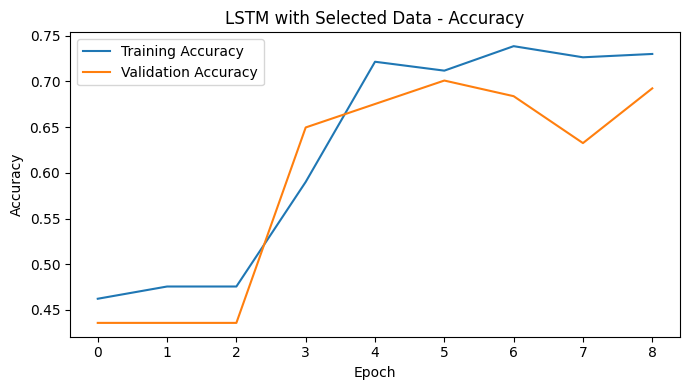

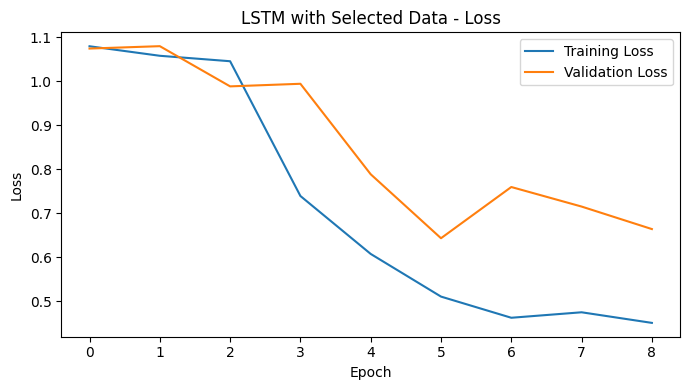

In [81]:
# Step 11.2.1: Plot LSTM training curves
plt.figure(figsize=(7, 4))
plt.plot(lstm_history.history["accuracy"], label="Training Accuracy")
plt.plot(lstm_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM with Selected Data - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(lstm_history.history["loss"], label="Training Loss")
plt.plot(lstm_history.history["val_loss"], label="Validation Loss")
plt.title("LSTM with Selected Data - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


In [82]:
# Step 11.3: Evaluate LSTM

lstm_train_results, lstm_train_pred, lstm_train_prob = evaluate_three_class_model(
    lstm_model,
    X_train_selected,
    y_train_selected,
    dataset_name="Train"
)

lstm_val_results, lstm_val_pred, lstm_val_prob = evaluate_three_class_model(
    lstm_model,
    X_val_pad,
    y_val,
    dataset_name="Validation"
)

lstm_long_val_results, lstm_long_val_pred, lstm_long_val_prob = evaluate_three_class_model(
    lstm_model,
    X_val_long,
    y_val_long,
    dataset_name="Long Validation"
)

lstm_contrast_val_results, lstm_contrast_val_pred, lstm_contrast_val_prob = evaluate_three_class_model(
    lstm_model,
    X_val_contrast,
    y_val_contrast,
    dataset_name="Contrast Validation"
)

lstm_results_df = pd.DataFrame([
    lstm_train_results,
    lstm_val_results,
    lstm_long_val_results,
    lstm_contrast_val_results
])

display(lstm_results_df.round(4))


,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative Recall,Neutral Recall,Positive Recall
0,Train,0.7409,0.7232,0.6587,0.5609,0.7759,0.7409,0.6596,0.9868,0.0098,0.9795
1,Validation,0.7009,0.4858,0.6083,0.5300,0.5801,0.7009,0.6235,0.9231,0.0000,0.9020
2,Long Validation,0.7297,0.4103,0.6410,0.4450,0.7214,0.7297,0.7050,1.0000,0.0000,0.9231
3,Contrast Validation,0.4400,0.3116,0.4141,0.3294,0.2513,0.4400,0.3068,0.9091,0.0000,0.3333


**Now I inspect classes:** Macro F1 and recall show whether LSTM handles all sentiments fairly.


In [83]:
# Step 11.4: Compare SimpleRNN and LSTM using selected training data

architecture_comparison_df = pd.DataFrame([
    {
        "Model": "SimpleRNN",
        "Training Method": selected_training_method,
        "Validation Accuracy": best_generation_row["Validation Accuracy"],
        "Validation Macro F1": best_generation_row["Validation Macro F1"],
        "Validation Weighted F1": best_generation_row["Validation Weighted F1"],
        "Negative Recall": best_generation_row["Negative Recall"],
        "Neutral Recall": best_generation_row["Neutral Recall"],
        "Positive Recall": best_generation_row["Positive Recall"],
        "Long Review Macro F1": best_generation_row["Long Review Macro F1"],
        "Contrast Review Macro F1": best_generation_row["Contrast Review Macro F1"],
        "Training Time (sec)": best_generation_row["Training Time (sec)"]
    },
    {
        "Model": "LSTM",
        "Training Method": selected_training_method,
        "Validation Accuracy": lstm_val_results["Accuracy"],
        "Validation Macro F1": lstm_val_results["Macro F1"],
        "Validation Weighted F1": lstm_val_results["Weighted F1"],
        "Negative Recall": lstm_val_results["Negative Recall"],
        "Neutral Recall": lstm_val_results["Neutral Recall"],
        "Positive Recall": lstm_val_results["Positive Recall"],
        "Long Review Macro F1": lstm_long_val_results["Macro F1"],
        "Contrast Review Macro F1": lstm_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(lstm_training_time, 2)
    }
])

display(architecture_comparison_df.round(4))


,Model,Training Method,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1,Training Time (sec)
0,SimpleRNN,Original + Sentence Split,0.8462,0.8371,0.8458,0.7949,0.8148,0.902,0.7511,0.7754,6.89
1,LSTM,Original + Sentence Split,0.7009,0.5300,0.6235,0.9231,0.0000,0.902,0.4450,0.3294,4.27


### 12.2 LSTM Outcome: Result

The LSTM does not improve the model in this run.

Its validation macro F1 is **0.5300**, which is much lower than the SimpleRNN with Sentence Split at **0.8371**.

The biggest warning sign is Neutral recall: **0.0000**. This means the LSTM did not correctly identify any Neutral reviews in the validation set.


### 12.3 LSTM Outcome: Decision

The LSTM can still recognise many Negative and Positive reviews, but missing the whole Neutral class makes it unreliable for a 3-class sentiment task.

So even though LSTM is theoretically stronger than SimpleRNN, it is not better here. The validation results matter more than the model name.

Decision: reject LSTM because it has much lower macro F1 and completely misses Neutral reviews.


## 13. Testing GRU

Next, I test GRU.

GRU is another gated recurrent model. It is usually simpler than LSTM but can still remember useful sequence patterns.

Here, I am checking whether GRU gives a better balance between sequence learning and model simplicity. Since the reviews are short, a lighter gated model may or may not be enough.

Again, I will judge it using validation Macro F1 and class recall, not by the model name.


In [84]:
# Step 12.1: Build GRU model

from tensorflow.keras.layers import GRU

def build_gru_model():
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    
    model = Sequential()
    
    model.add(Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        input_length=MAX_LEN
    ))
    
    model.add(GRU(32))
    model.add(Dropout(0.3))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(NUM_CLASSES, activation="softmax"))
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

gru_model = build_gru_model()
gru_model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 35, 64)            320000    
                                                                 
 gru (GRU)                   (None, 32)                9408      
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense (Dense)               (None, 16)                528       
                                                                 
 dense_1 (Dense)             (None, 3)                 51        
                                                                 
Total params: 329,987
Trainable params: 329,987
Non-trainable params: 0
_________________________________________________________________


**Why test GRU:** GRU is a lighter gated model, so it may work better on short reviews.


In [85]:
# Step 12.2: Train GRU using selected training data

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

gru_history = gru_model.fit(
    X_train_selected,
    y_train_selected,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

gru_training_time = time.time() - start_time

print("GRU training time:", round(gru_training_time, 2), "seconds")
print("Epochs run:", len(gru_history.history["loss"]))


Epoch 1/15
26/26 [==============================] - 1s 18ms/step - loss: 1.0757 - accuracy: 0.4538 - val_loss: 1.0743 - val_accuracy: 0.4359
Epoch 2/15
26/26 [==============================] - 0s 9ms/step - loss: 1.0586 - accuracy: 0.4757 - val_loss: 1.0766 - val_accuracy: 0.4359
Epoch 3/15
26/26 [==============================] - 0s 7ms/step - loss: 1.0555 - accuracy: 0.4757 - val_loss: 1.0753 - val_accuracy: 0.4359
Epoch 4/15
26/26 [==============================] - 0s 8ms/step - loss: 1.0565 - accuracy: 0.4757 - val_loss: 1.0779 - val_accuracy: 0.4359
GRU training time: 1.94 seconds
Epochs run: 4


**After training GRU:** The curve shape helps show whether it learns or collapses into one class.


### 13.1 GRU Training Curve Check

I also plot the GRU training curves before making the decision.

GRU is a simpler gated model than LSTM, so the purpose of testing it is reasonable: it might capture sequence patterns without being as heavy as LSTM. But I still need the output metrics to decide whether it actually helps.

After the graph, the class-level metrics show the real problem. The GRU collapses into predicting mostly Positive, so the curves become supporting evidence rather than the main reason for rejection.


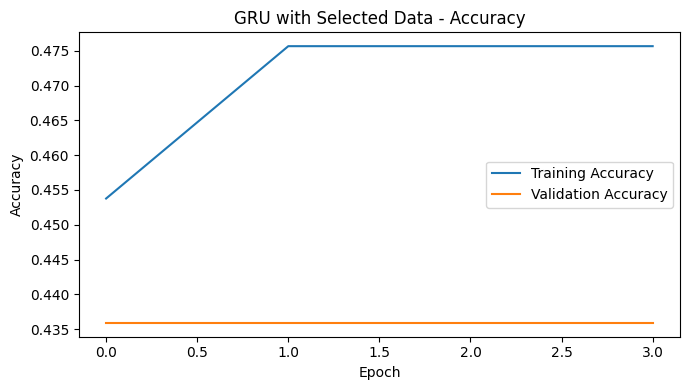

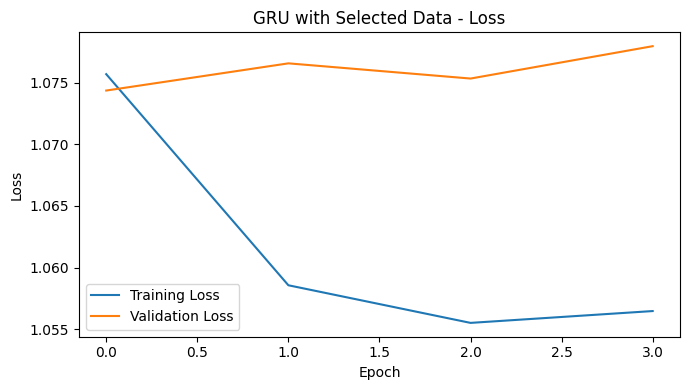

In [86]:
# Step 12.2.1: Plot GRU training curves
plt.figure(figsize=(7, 4))
plt.plot(gru_history.history["accuracy"], label="Training Accuracy")
plt.plot(gru_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("GRU with Selected Data - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(gru_history.history["loss"], label="Training Loss")
plt.plot(gru_history.history["val_loss"], label="Validation Loss")
plt.title("GRU with Selected Data - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


In [87]:
# Step 12.3: Evaluate GRU

gru_train_results, gru_train_pred, gru_train_prob = evaluate_three_class_model(
    gru_model,
    X_train_selected,
    y_train_selected,
    dataset_name="Train"
)

gru_val_results, gru_val_pred, gru_val_prob = evaluate_three_class_model(
    gru_model,
    X_val_pad,
    y_val,
    dataset_name="Validation"
)

gru_long_val_results, gru_long_val_pred, gru_long_val_prob = evaluate_three_class_model(
    gru_model,
    X_val_long,
    y_val_long,
    dataset_name="Long Validation"
)

gru_contrast_val_results, gru_contrast_val_pred, gru_contrast_val_prob = evaluate_three_class_model(
    gru_model,
    X_val_contrast,
    y_val_contrast,
    dataset_name="Contrast Validation"
)

gru_results_df = pd.DataFrame([
    gru_train_results,
    gru_val_results,
    gru_long_val_results,
    gru_contrast_val_results
])

display(gru_results_df.round(4))


,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative Recall,Neutral Recall,Positive Recall
0,Train,0.4757,0.1586,0.3333,0.2149,0.2263,0.4757,0.3067,0.0,0.0,1.0
1,Validation,0.4359,0.1453,0.3333,0.2024,0.1900,0.4359,0.2647,0.0,0.0,1.0
2,Long Validation,0.7027,0.2342,0.3333,0.2751,0.4938,0.7027,0.5800,0.0,0.0,1.0
3,Contrast Validation,0.1200,0.0400,0.3333,0.0714,0.0144,0.1200,0.0257,0.0,0.0,1.0


**Class recall matters here:** A high overall score would not help if two classes are ignored.


In [88]:
# Step 12.4: Compare SimpleRNN, LSTM, and GRU using selected training data

architecture_comparison_df = pd.DataFrame([
    {
        "Model": "SimpleRNN",
        "Training Method": selected_training_method,
        "Validation Accuracy": best_generation_row["Validation Accuracy"],
        "Validation Macro F1": best_generation_row["Validation Macro F1"],
        "Validation Weighted F1": best_generation_row["Validation Weighted F1"],
        "Negative Recall": best_generation_row["Negative Recall"],
        "Neutral Recall": best_generation_row["Neutral Recall"],
        "Positive Recall": best_generation_row["Positive Recall"],
        "Long Review Macro F1": best_generation_row["Long Review Macro F1"],
        "Contrast Review Macro F1": best_generation_row["Contrast Review Macro F1"],
        "Training Time (sec)": best_generation_row["Training Time (sec)"]
    },
    {
        "Model": "LSTM",
        "Training Method": selected_training_method,
        "Validation Accuracy": lstm_val_results["Accuracy"],
        "Validation Macro F1": lstm_val_results["Macro F1"],
        "Validation Weighted F1": lstm_val_results["Weighted F1"],
        "Negative Recall": lstm_val_results["Negative Recall"],
        "Neutral Recall": lstm_val_results["Neutral Recall"],
        "Positive Recall": lstm_val_results["Positive Recall"],
        "Long Review Macro F1": lstm_long_val_results["Macro F1"],
        "Contrast Review Macro F1": lstm_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(lstm_training_time, 2)
    },
    {
        "Model": "GRU",
        "Training Method": selected_training_method,
        "Validation Accuracy": gru_val_results["Accuracy"],
        "Validation Macro F1": gru_val_results["Macro F1"],
        "Validation Weighted F1": gru_val_results["Weighted F1"],
        "Negative Recall": gru_val_results["Negative Recall"],
        "Neutral Recall": gru_val_results["Neutral Recall"],
        "Positive Recall": gru_val_results["Positive Recall"],
        "Long Review Macro F1": gru_long_val_results["Macro F1"],
        "Contrast Review Macro F1": gru_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(gru_training_time, 2)
    }
])

architecture_comparison_df = architecture_comparison_df.sort_values(
    by=["Validation Macro F1", "Long Review Macro F1", "Contrast Review Macro F1"],
    ascending=False
)

display(architecture_comparison_df.round(4))


,Model,Training Method,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1,Training Time (sec)
0,SimpleRNN,Original + Sentence Split,0.8462,0.8371,0.8458,0.7949,0.8148,0.902,0.7511,0.7754,6.89
1,LSTM,Original + Sentence Split,0.7009,0.5300,0.6235,0.9231,0.0000,0.902,0.4450,0.3294,4.27
2,GRU,Original + Sentence Split,0.4359,0.2024,0.2647,0.0000,0.0000,1.000,0.2751,0.0714,1.94


### 13.2 GRU Outcome

The GRU performs badly in this experiment.

Its validation macro F1 is **0.2024**, and both Negative recall and Neutral recall are **0.0000**. This means the model is mostly predicting Positive.

This is a serious problem because the dataset has three sentiment classes. A model that ignores two classes is not useful, even if Positive is the largest class.

Decision: reject GRU because it collapses toward Positive predictions and does not handle the full classification task.


## 14. Testing Bidirectional GRU

Now I test Bidirectional GRU.

A normal RNN reads the review from left to right. A Bidirectional RNN reads it in both directions.

This is worth testing because sometimes the meaning of a word depends on what comes after it.

For example:

> "The pizza looked good but tasted stale."

The word "good" appears early, but the later phrase "tasted stale" changes the final sentiment.

So my question here is whether reading the review in both directions helps the model handle longer or contrast-style reviews better than the earlier models.


In [89]:
# Step 13.1: Build Bidirectional GRU model

from tensorflow.keras.layers import Bidirectional, GRU

def build_bigru_model():
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    
    model = Sequential()
    
    model.add(Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        input_length=MAX_LEN
    ))
    
    model.add(Bidirectional(GRU(32)))
    model.add(Dropout(0.4))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(NUM_CLASSES, activation="softmax"))
    
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    
    return model

bigru_model = build_bigru_model()
bigru_model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 35, 64)            320000    
                                                                 
 bidirectional (Bidirectiona  (None, 64)               18816     
 l)                                                              
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 16)                1040      
                                                                 
 dense_1 (Dense)             (None, 3)                 51        
                                                                 
Total params: 339,907
Trainable params: 339,907
Non-trainable params: 0
__________________________________________________

**Why BiGRU:** Reading both directions may help when important sentiment appears after contrast words.


In [90]:
# Step 13.2: Train BiGRU using selected training data

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

bigru_history = bigru_model.fit(
    X_train_selected,
    y_train_selected,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

bigru_training_time = time.time() - start_time

print("BiGRU training time:", round(bigru_training_time, 2), "seconds")
print("Epochs run:", len(bigru_history.history["loss"]))


Epoch 1/15
26/26 [==============================] - 2s 29ms/step - loss: 1.0652 - accuracy: 0.4586 - val_loss: 1.0607 - val_accuracy: 0.4359
Epoch 2/15
26/26 [==============================] - 0s 8ms/step - loss: 1.0098 - accuracy: 0.4781 - val_loss: 0.9666 - val_accuracy: 0.4872
Epoch 3/15
26/26 [==============================] - 0s 8ms/step - loss: 0.7922 - accuracy: 0.6509 - val_loss: 0.6390 - val_accuracy: 0.7179
Epoch 4/15
26/26 [==============================] - 0s 9ms/step - loss: 0.5443 - accuracy: 0.7397 - val_loss: 0.5499 - val_accuracy: 0.7265
Epoch 5/15
26/26 [==============================] - 0s 9ms/step - loss: 0.4388 - accuracy: 0.8005 - val_loss: 0.4904 - val_accuracy: 0.8120
Epoch 6/15
26/26 [==============================] - 0s 10ms/step - loss: 0.3839 - accuracy: 0.8455 - val_loss: 0.4376 - val_accuracy: 0.8462
Epoch 7/15
26/26 [==============================] - 0s 10ms/step - loss: 0.3001 - accuracy: 0.8917 - val_loss: 0.3939 - val_accuracy: 0.8462
Epoch 8/15
26/26 

**After training BiGRU:** I evaluate whether the stronger sequence model improves the earlier hard-review weaknesses.


In [91]:
# Step 13.3: Evaluate BiGRU

bigru_train_results, bigru_train_pred, bigru_train_prob = evaluate_three_class_model(
    bigru_model,
    X_train_selected,
    y_train_selected,
    dataset_name="Train"
)

bigru_val_results, bigru_val_pred, bigru_val_prob = evaluate_three_class_model(
    bigru_model,
    X_val_pad,
    y_val,
    dataset_name="Validation"
)

bigru_long_val_results, bigru_long_val_pred, bigru_long_val_prob = evaluate_three_class_model(
    bigru_model,
    X_val_long,
    y_val_long,
    dataset_name="Long Validation"
)

bigru_contrast_val_results, bigru_contrast_val_pred, bigru_contrast_val_prob = evaluate_three_class_model(
    bigru_model,
    X_val_contrast,
    y_val_contrast,
    dataset_name="Contrast Validation"
)

bigru_results_df = pd.DataFrame([
    bigru_train_results,
    bigru_val_results,
    bigru_long_val_results,
    bigru_contrast_val_results
])

display(bigru_results_df.round(4))


,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative Recall,Neutral Recall,Positive Recall
0,Train,0.9550,0.9473,0.9454,0.9458,0.9558,0.9550,0.9550,0.9075,0.9363,0.9923
1,Validation,0.8632,0.8566,0.8483,0.8497,0.8658,0.8632,0.8616,0.7692,0.8148,0.9608
2,Long Validation,0.8919,0.8166,0.7927,0.8034,0.8900,0.8919,0.8900,0.6667,0.7500,0.9615
3,Contrast Validation,0.8400,0.8838,0.7980,0.8292,0.8467,0.8400,0.8386,0.9091,0.8182,0.6667


**BiGRU checkpoint:** The evaluation now tells me whether bidirectional context is worth the extra complexity.


### 14.1 Small BiGRU Hyperparameter Check

After testing a bidirectional recurrent model, I run a small tuning check to see whether its main settings are reasonable.

I keep this tuning small on purpose. The dataset is not huge, so testing too many combinations could make me accidentally chase the validation set instead of learning a reliable pattern.

Here I only change two simple things: the number of GRU units and the dropout rate.

My expectation is that a slightly larger BiGRU may learn more detail, but too much capacity or too much dropout may hurt because the reviews are short.


In [92]:
# Step 13.5.1: Small BiGRU hyperparameter check

def build_bigru_model_with_settings(units=32, dropout_rate=0.4, learning_rate=0.001):
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)

    model = Sequential()
    model.add(Embedding(input_dim=MAX_WORDS, output_dim=64, input_length=MAX_LEN))
    model.add(Bidirectional(GRU(units)))
    model.add(Dropout(dropout_rate))
    model.add(Dense(16, activation="relu"))
    model.add(Dense(NUM_CLASSES, activation="softmax"))

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

bigru_tuning_settings = [
    {"Setting": "BiGRU A", "Units": 32, "Dropout": 0.4, "Learning Rate": 0.001},
    {"Setting": "BiGRU B", "Units": 64, "Dropout": 0.4, "Learning Rate": 0.001},
    {"Setting": "BiGRU C", "Units": 64, "Dropout": 0.5, "Learning Rate": 0.001}
]

bigru_tuning_models = {}
bigru_tuning_histories = {}
bigru_tuning_results = []

for setting in bigru_tuning_settings:
    print("Training", setting["Setting"])

    tuning_model = build_bigru_model_with_settings(
        units=setting["Units"],
        dropout_rate=setting["Dropout"],
        learning_rate=setting["Learning Rate"]
    )

    early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    start_time = time.time()

    tuning_history = tuning_model.fit(
        X_train_selected,
        y_train_selected,
        validation_data=(X_val_pad, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )

    tuning_time = time.time() - start_time

    tuning_val_results, _, _ = evaluate_three_class_model(
        tuning_model, X_val_pad, y_val, dataset_name="Validation"
    )
    tuning_long_results, _, _ = evaluate_three_class_model(
        tuning_model, X_val_long, y_val_long, dataset_name="Long Validation"
    )
    tuning_contrast_results, _, _ = evaluate_three_class_model(
        tuning_model, X_val_contrast, y_val_contrast, dataset_name="Contrast Validation"
    )

    bigru_tuning_models[setting["Setting"]] = tuning_model
    bigru_tuning_histories[setting["Setting"]] = tuning_history

    bigru_tuning_results.append({
        "Setting": setting["Setting"],
        "Units": setting["Units"],
        "Dropout": setting["Dropout"],
        "Learning Rate": setting["Learning Rate"],
        "Epochs Run": len(tuning_history.history["loss"]),
        "Training Time (sec)": round(tuning_time, 2),
        "Validation Accuracy": tuning_val_results["Accuracy"],
        "Validation Macro F1": tuning_val_results["Macro F1"],
        "Validation Weighted F1": tuning_val_results["Weighted F1"],
        "Negative Recall": tuning_val_results["Negative Recall"],
        "Neutral Recall": tuning_val_results["Neutral Recall"],
        "Positive Recall": tuning_val_results["Positive Recall"],
        "Long Review Macro F1": tuning_long_results["Macro F1"],
        "Contrast Review Macro F1": tuning_contrast_results["Macro F1"]
    })

bigru_tuning_df = pd.DataFrame(bigru_tuning_results).sort_values(
    by=["Validation Macro F1", "Validation Accuracy", "Long Review Macro F1"],
    ascending=False
)

display(bigru_tuning_df.round(4))


Training BiGRU A
Epoch 1/15
26/26 [==============================] - 2s 29ms/step - loss: 1.0640 - accuracy: 0.4732 - val_loss: 1.0631 - val_accuracy: 0.4359
Epoch 2/15
26/26 [==============================] - 0s 10ms/step - loss: 1.0033 - accuracy: 0.4781 - val_loss: 0.9592 - val_accuracy: 0.5128
Epoch 3/15
26/26 [==============================] - 0s 10ms/step - loss: 0.7760 - accuracy: 0.6423 - val_loss: 0.6177 - val_accuracy: 0.7094
Epoch 4/15
26/26 [==============================] - 0s 9ms/step - loss: 0.5539 - accuracy: 0.7445 - val_loss: 0.5394 - val_accuracy: 0.7692
Epoch 5/15
26/26 [==============================] - 0s 9ms/step - loss: 0.4335 - accuracy: 0.8175 - val_loss: 0.4726 - val_accuracy: 0.8205
Epoch 6/15
26/26 [==============================] - 0s 9ms/step - loss: 0.3699 - accuracy: 0.8613 - val_loss: 0.4165 - val_accuracy: 0.8376
Epoch 7/15
26/26 [==============================] - 0s 9ms/step - loss: 0.2769 - accuracy: 0.9063 - val_loss: 0.3752 - val_accuracy: 0.8462


,Setting,Units,Dropout,Learning Rate,Epochs Run,Training Time (sec),Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1
2,BiGRU C,64,0.5,0.001,15,5.97,0.8803,0.8674,0.8784,0.8718,0.7407,0.9608,0.8988,0.9046
0,BiGRU A,32,0.4,0.001,15,5.81,0.8718,0.8618,0.8711,0.8205,0.8148,0.9412,0.8489,0.8283
1,BiGRU B,64,0.4,0.001,12,4.91,0.8462,0.8368,0.8443,0.7692,0.7778,0.9412,0.9173,0.7698


**Tuning carefully:** I only test a few settings to avoid overfitting the validation set through excessive searching.


In [93]:
# Step 13.5.2: Decide whether tuning changes the selected BiGRU

best_tuning_row = bigru_tuning_df.iloc[0]
best_tuning_name = best_tuning_row["Setting"]

print("Best tuned setting:", best_tuning_name)
print("Best tuned validation Macro F1:", round(best_tuning_row["Validation Macro F1"], 4))
print("Original BiGRU validation Macro F1:", round(bigru_val_results["Macro F1"], 4))

if best_tuning_row["Validation Macro F1"] > bigru_val_results["Macro F1"]:
    print("The tuned BiGRU improved validation Macro F1, so I will use it as the BiGRU candidate.")

    bigru_model = bigru_tuning_models[best_tuning_name]
    bigru_history = bigru_tuning_histories[best_tuning_name]
    bigru_training_time = best_tuning_row["Training Time (sec)"]

    bigru_train_results, bigru_train_pred, bigru_train_prob = evaluate_three_class_model(
        bigru_model, X_train_selected, y_train_selected, dataset_name="Train"
    )
    bigru_val_results, bigru_val_pred, bigru_val_prob = evaluate_three_class_model(
        bigru_model, X_val_pad, y_val, dataset_name="Validation"
    )
    bigru_long_val_results, bigru_long_val_pred, bigru_long_val_prob = evaluate_three_class_model(
        bigru_model, X_val_long, y_val_long, dataset_name="Long Validation"
    )
    bigru_contrast_val_results, bigru_contrast_val_pred, bigru_contrast_val_prob = evaluate_three_class_model(
        bigru_model, X_val_contrast, y_val_contrast, dataset_name="Contrast Validation"
    )

    bigru_selected_setting = best_tuning_name
else:
    print("The original BiGRU setting remains the selected BiGRU candidate.")
    bigru_selected_setting = "Original BiGRU"

print("BiGRU setting used after tuning:", bigru_selected_setting)


Best tuned setting: BiGRU C
Best tuned validation Macro F1: 0.8674
Original BiGRU validation Macro F1: 0.8497
The tuned BiGRU improved validation Macro F1, so I will use it as the BiGRU candidate.
BiGRU setting used after tuning: BiGRU C


**Tuning decision point:** I will compare the tuned BiGRU settings using validation Macro F1, validation loss and hard-subset performance before deciding which version should continue.


### 14.2 BiGRU Tuning Outcome

The BiGRU tuning check gives a useful improvement.

The best setting is **BiGRU C**, which uses:

- `64` GRU units
- `0.5` dropout
- learning rate `0.001`

It achieves validation macro F1 **0.8674**, improving over the earlier BiGRU result of **0.8497**.

This tells me that the BiGRU needed slightly more capacity than the first setting, but also stronger dropout to reduce overfitting. The model is now larger than BiGRU A, but the validation macro F1 supports the change.

Decision: use **BiGRU C** as the selected BiGRU candidate for the next comparison.


In [94]:
# Step 13.4: Compare all architecture experiments

architecture_comparison_df = pd.DataFrame([
    {
        "Model": "SimpleRNN",
        "Training Method": selected_training_method,
        "Validation Accuracy": best_generation_row["Validation Accuracy"],
        "Validation Macro F1": best_generation_row["Validation Macro F1"],
        "Validation Weighted F1": best_generation_row["Validation Weighted F1"],
        "Negative Recall": best_generation_row["Negative Recall"],
        "Neutral Recall": best_generation_row["Neutral Recall"],
        "Positive Recall": best_generation_row["Positive Recall"],
        "Long Review Macro F1": best_generation_row["Long Review Macro F1"],
        "Contrast Review Macro F1": best_generation_row["Contrast Review Macro F1"],
        "Training Time (sec)": best_generation_row["Training Time (sec)"]
    },
    {
        "Model": "LSTM",
        "Training Method": selected_training_method,
        "Validation Accuracy": lstm_val_results["Accuracy"],
        "Validation Macro F1": lstm_val_results["Macro F1"],
        "Validation Weighted F1": lstm_val_results["Weighted F1"],
        "Negative Recall": lstm_val_results["Negative Recall"],
        "Neutral Recall": lstm_val_results["Neutral Recall"],
        "Positive Recall": lstm_val_results["Positive Recall"],
        "Long Review Macro F1": lstm_long_val_results["Macro F1"],
        "Contrast Review Macro F1": lstm_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(lstm_training_time, 2)
    },
    {
        "Model": "GRU",
        "Training Method": selected_training_method,
        "Validation Accuracy": gru_val_results["Accuracy"],
        "Validation Macro F1": gru_val_results["Macro F1"],
        "Validation Weighted F1": gru_val_results["Weighted F1"],
        "Negative Recall": gru_val_results["Negative Recall"],
        "Neutral Recall": gru_val_results["Neutral Recall"],
        "Positive Recall": gru_val_results["Positive Recall"],
        "Long Review Macro F1": gru_long_val_results["Macro F1"],
        "Contrast Review Macro F1": gru_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(gru_training_time, 2)
    },
    {
        "Model": "BiGRU",
        "Training Method": selected_training_method,
        "Validation Accuracy": bigru_val_results["Accuracy"],
        "Validation Macro F1": bigru_val_results["Macro F1"],
        "Validation Weighted F1": bigru_val_results["Weighted F1"],
        "Negative Recall": bigru_val_results["Negative Recall"],
        "Neutral Recall": bigru_val_results["Neutral Recall"],
        "Positive Recall": bigru_val_results["Positive Recall"],
        "Long Review Macro F1": bigru_long_val_results["Macro F1"],
        "Contrast Review Macro F1": bigru_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(bigru_training_time, 2)
    }
])

architecture_comparison_df = architecture_comparison_df.sort_values(
    by=["Validation Macro F1", "Long Review Macro F1", "Contrast Review Macro F1"],
    ascending=False
)

display(architecture_comparison_df.round(4))


,Model,Training Method,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1,Training Time (sec)
3,BiGRU,Original + Sentence Split,0.8803,0.8674,0.8784,0.8718,0.7407,0.9608,0.8988,0.9046,5.97
0,SimpleRNN,Original + Sentence Split,0.8462,0.8371,0.8458,0.7949,0.8148,0.9020,0.7511,0.7754,6.89
1,LSTM,Original + Sentence Split,0.7009,0.5300,0.6235,0.9231,0.0000,0.9020,0.4450,0.3294,4.27
2,GRU,Original + Sentence Split,0.4359,0.2024,0.2647,0.0000,0.0000,1.0000,0.2751,0.0714,1.94


**Architecture checkpoint:** Now I compare SimpleRNN, LSTM, GRU and BiGRU using the same validation evidence.


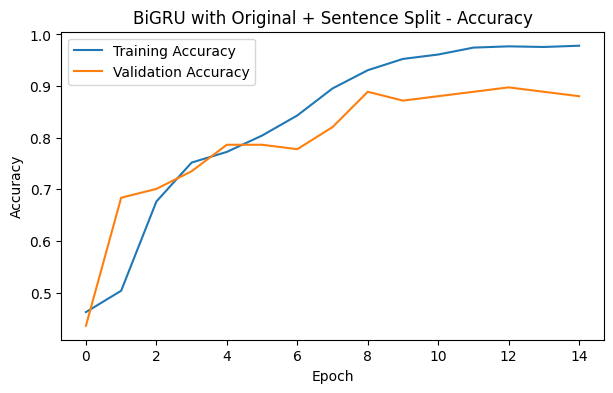

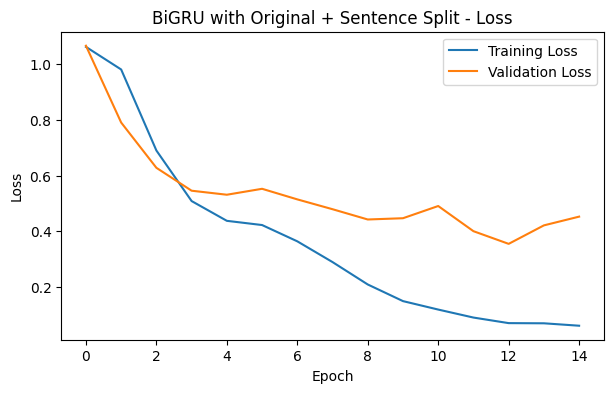

In [95]:
# Plot final selected BiGRU training curves

plt.figure(figsize=(7, 4))
plt.plot(bigru_history.history["accuracy"], label="Training Accuracy")
plt.plot(bigru_history.history["val_accuracy"], label="Validation Accuracy")
plt.title(f"BiGRU with {selected_training_method} - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(bigru_history.history["loss"], label="Training Loss")
plt.plot(bigru_history.history["val_loss"], label="Validation Loss")
plt.title(f"BiGRU with {selected_training_method} - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


**Curve checkpoint:** The plots show whether the selected BiGRU learned steadily or overfit too quickly.


In [96]:
# Train-validation gap check for architecture models

selected_simple_rnn_train_results, _, _ = evaluate_three_class_model(
    selected_simple_rnn_model,
    X_train_selected,
    y_train_selected,
    dataset_name="Train"
)

overfitting_check_df = pd.DataFrame([
    {
        "Model": "SimpleRNN",
        "Train Accuracy": selected_simple_rnn_train_results["Accuracy"],
        "Validation Accuracy": best_generation_row["Validation Accuracy"],
        "Accuracy Gap": selected_simple_rnn_train_results["Accuracy"] - best_generation_row["Validation Accuracy"],
        "Train Macro F1": selected_simple_rnn_train_results["Macro F1"],
        "Validation Macro F1": best_generation_row["Validation Macro F1"],
        "Macro F1 Gap": selected_simple_rnn_train_results["Macro F1"] - best_generation_row["Validation Macro F1"]
    },
    {
        "Model": "LSTM",
        "Train Accuracy": lstm_train_results["Accuracy"],
        "Validation Accuracy": lstm_val_results["Accuracy"],
        "Accuracy Gap": lstm_train_results["Accuracy"] - lstm_val_results["Accuracy"],
        "Train Macro F1": lstm_train_results["Macro F1"],
        "Validation Macro F1": lstm_val_results["Macro F1"],
        "Macro F1 Gap": lstm_train_results["Macro F1"] - lstm_val_results["Macro F1"]
    },
    {
        "Model": "GRU",
        "Train Accuracy": gru_train_results["Accuracy"],
        "Validation Accuracy": gru_val_results["Accuracy"],
        "Accuracy Gap": gru_train_results["Accuracy"] - gru_val_results["Accuracy"],
        "Train Macro F1": gru_train_results["Macro F1"],
        "Validation Macro F1": gru_val_results["Macro F1"],
        "Macro F1 Gap": gru_train_results["Macro F1"] - gru_val_results["Macro F1"]
    },
    {
        "Model": "BiGRU",
        "Train Accuracy": bigru_train_results["Accuracy"],
        "Validation Accuracy": bigru_val_results["Accuracy"],
        "Accuracy Gap": bigru_train_results["Accuracy"] - bigru_val_results["Accuracy"],
        "Train Macro F1": bigru_train_results["Macro F1"],
        "Validation Macro F1": bigru_val_results["Macro F1"],
        "Macro F1 Gap": bigru_train_results["Macro F1"] - bigru_val_results["Macro F1"]
    }
])

display(overfitting_check_df.round(4))


,Model,Train Accuracy,Validation Accuracy,Accuracy Gap,Train Macro F1,Validation Macro F1,Macro F1 Gap
0,SimpleRNN,0.9319,0.8462,0.0857,0.9223,0.8371,0.0853
1,LSTM,0.7409,0.7009,0.0400,0.5609,0.5300,0.0309
2,GRU,0.4757,0.4359,0.0398,0.2149,0.2024,0.0125
3,BiGRU,0.9878,0.8803,0.1075,0.9856,0.8674,0.1183


### 14.3 Architecture Comparison: Main Result

Now the architecture comparison gives a clearer direction.

The SimpleRNN with Sentence Split has validation macro F1 **0.8371**.

The tuned BiGRU with Sentence Split improves this to **0.8674**.


### 14.4 Architecture Comparison: Why BiGRU Becomes the Candidate

The BiGRU is also stronger on the hard subsets:

- BiGRU long-review macro F1: **0.8988**
- BiGRU contrast-review macro F1: **0.9046**

This matters because the baseline weakness was long and contrast reviews. The BiGRU can read context from both directions, so it becomes the strongest improvement candidate.

Decision: keep BiGRU and test whether targeted contrast-clause data can improve the validation result further.


## 15. Fair Language Handling Experiment: English Only vs English + Translated Malay

Earlier, I translated Malay reviews instead of deleting them.

That sounds reasonable, but I need to test it with evidence. If I only explain the idea without testing it, the decision is weaker.


### 15.1 How I Make the Language Test Fair

Both language experiments use:

- **Original Only** training reviews;
- the same tuned BiGRU settings;
- the same validation set;
- the same evaluation metrics.

The main difference is whether Malay-origin translated reviews are included in training. This makes the language decision easier to trust.


### 15.2 Language Experiment Limitation

One technical limitation remains: both experiments still use the tokenizer fitted earlier on the full training text.

This means the English-only experiment is not a completely isolated tokenizer experiment. I keep the shared tokenizer so the input representation stays consistent across the comparison.

A stricter future test could refit a separate English-only tokenizer, but this experiment is still useful for checking whether translated Malay training reviews help under the final preprocessing pipeline.


In [97]:
# Step 13.6.1: Fair language experiment using Original Only data

from IPython.display import Markdown, display as display_markdown

language_units = int(best_tuning_row["Units"]) if "best_tuning_row" in globals() else 64
language_dropout = float(best_tuning_row["Dropout"]) if "best_tuning_row" in globals() else 0.5
language_learning_rate = float(best_tuning_row["Learning Rate"]) if "best_tuning_row" in globals() else 0.001

def prepare_original_only_language_data(dataframe):
    X_text = dataframe["Text_Clean"].tolist()
    y_values = dataframe["Sentiment_Label"].astype(int).values
    
    X_seq = tokenizer.texts_to_sequences(X_text)
    X_pad = pad_sequences(
        X_seq,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )
    
    return X_pad, y_values

def train_language_bigru_experiment(experiment_name, language_train_df):
    print("=" * 70)
    print("Training language experiment:", experiment_name)
    print("=" * 70)
    
    X_language_train, y_language_train = prepare_original_only_language_data(language_train_df)
    
    model = build_bigru_model_with_settings(
        units=language_units,
        dropout_rate=language_dropout,
        learning_rate=language_learning_rate
    )
    
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )
    
    start_time = time.time()
    
    history = model.fit(
        X_language_train,
        y_language_train,
        validation_data=(X_val_pad, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[early_stop],
        verbose=1
    )
    
    training_time = time.time() - start_time
    
    val_results, val_pred, val_prob = evaluate_three_class_model(
        model,
        X_val_pad,
        y_val,
        dataset_name="Validation"
    )
    
    result_row = {
        "Training Data": experiment_name,
        "Training Rows": len(X_language_train),
        "Units": language_units,
        "Dropout": language_dropout,
        "Validation Accuracy": val_results["Accuracy"],
        "Validation Macro F1": val_results["Macro F1"],
        "Validation Weighted F1": val_results["Weighted F1"],
        "Negative Recall": val_results["Negative Recall"],
        "Neutral Recall": val_results["Neutral Recall"],
        "Positive Recall": val_results["Positive Recall"],
        "Training Time (sec)": round(training_time, 2)
    }
    
    return model, history, result_row

english_only_train_df = train_df[train_df["Language_Clean"] == "English"].copy()
english_malay_train_df = train_df.copy()

english_only_language_model, english_only_language_history, english_only_language_results = train_language_bigru_experiment(
    "English Only + Original Only",
    english_only_train_df
)

english_malay_language_model, english_malay_language_history, english_malay_language_results = train_language_bigru_experiment(
    "English + Translated Malay + Original Only",
    english_malay_train_df
)

language_experiment_df = pd.DataFrame([
    english_only_language_results,
    english_malay_language_results
])

display(language_experiment_df.round(4))

english_only_macro_f1 = english_only_language_results["Validation Macro F1"]
english_malay_macro_f1 = english_malay_language_results["Validation Macro F1"]

if english_malay_macro_f1 >= english_only_macro_f1:
    language_decision = (
        f"The fair comparison supports keeping translated Malay reviews. "
        f"English + translated Malay reaches validation Macro F1 **{english_malay_macro_f1:.4f}**, "
        f"compared with **{english_only_macro_f1:.4f}** for English-only training."
    )
else:
    language_decision = (
        f"The fair comparison suggests English-only training is cleaner for this run. "
        f"English-only reaches validation Macro F1 **{english_only_macro_f1:.4f}**, "
        f"compared with **{english_malay_macro_f1:.4f}** for English + translated Malay."
    )

display_markdown(Markdown("**Language decision:** " + language_decision))


Training language experiment: English Only + Original Only
Epoch 1/15
10/10 [==============================] - 2s 57ms/step - loss: 1.0962 - accuracy: 0.3510 - val_loss: 1.0811 - val_accuracy: 0.4359
Epoch 2/15
10/10 [==============================] - 0s 15ms/step - loss: 1.0788 - accuracy: 0.3642 - val_loss: 1.0651 - val_accuracy: 0.4359
Epoch 3/15
10/10 [==============================] - 0s 14ms/step - loss: 1.0468 - accuracy: 0.3874 - val_loss: 1.0224 - val_accuracy: 0.4872
Epoch 4/15
10/10 [==============================] - 0s 14ms/step - loss: 0.9528 - accuracy: 0.5464 - val_loss: 0.9300 - val_accuracy: 0.5128
Epoch 5/15
10/10 [==============================] - 0s 14ms/step - loss: 0.8113 - accuracy: 0.6093 - val_loss: 0.9032 - val_accuracy: 0.5556
Epoch 6/15
10/10 [==============================] - 0s 14ms/step - loss: 0.7090 - accuracy: 0.6656 - val_loss: 0.8376 - val_accuracy: 0.5812
Epoch 7/15
10/10 [==============================] - 0s 14ms/step - loss: 0.6112 - accuracy: 0.7

,Training Data,Training Rows,Units,Dropout,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Training Time (sec)
0,English Only + Original Only,302,64,0.5,0.7350,0.7144,0.7304,0.7692,0.5185,0.8235,3.49
1,English + Translated Malay + Original Only,546,64,0.5,0.8718,0.8608,0.8718,0.7949,0.8519,0.9412,3.92


**Language decision:** The fair comparison supports keeping translated Malay reviews. English + translated Malay reaches validation Macro F1 **0.8608**, compared with **0.7144** for English-only training.

**Language evidence point:** This experiment checks whether translated Malay reviews help, without changing the training method.


### 15.3 Language Handling Outcome: Result

The language experiment supports keeping translated Malay reviews.

Using English-only original reviews gives validation macro F1 **0.7144**.

Using English + translated Malay original reviews gives validation macro F1 **0.8608**.

This is a large improvement, so removing Malay reviews would throw away useful training information.


### 15.4 Language Handling Outcome: Decision

Translation may introduce some noise, but the validation evidence shows that the extra translated Malay data helps more than it hurts.

Importantly, this does not mean I added outside review data. The translation tool was used only to convert the existing provided Malay reviews into English. It did not add external training examples or external review data.

Decision: keep translated Malay reviews in the modelling dataset.


In [98]:
# Step 14.1: Store current best validation model before stress testing

current_best_model = bigru_model
current_best_model_name = "BiGRU + " + selected_training_method

print("Current best validation model:", current_best_model_name)
print("Validation Macro F1:", round(bigru_val_results["Macro F1"], 4))
print("Long Review Macro F1:", round(bigru_long_val_results["Macro F1"], 4))
print("Contrast Review Macro F1:", round(bigru_contrast_val_results["Macro F1"], 4))


Current best validation model: BiGRU + Original + Sentence Split
Validation Macro F1: 0.8674
Long Review Macro F1: 0.8988
Contrast Review Macro F1: 0.9046


## 16. Teacher-Style Stress Test

The validation score is strong, but I also want to see how the model behaves on very tricky examples.

So I create a small teacher-style stress test with mixed reviews.

This is not used for final model selection. It is more like asking:

> If my teacher gives the model tricky sentence examples, what will happen?

These examples often contain both positive and negative parts. They are difficult because the model must decide which part carries the stronger sentiment.


In [99]:
# Step 14.2: Create teacher-style mixed review stress test set

teacher_negative_reviews = [
    "The crust looked beautiful, but the pizza tasted stale, greasy, and strangely bitter.",
    "I wanted to like it because the staff were friendly, but every slice was cold and bland.",
    "The pizza was not terrible, but I would not order it again unless there were no other options.",
    "The cheese was rich and the toppings were fresh, yet the soggy base ruined the whole meal.",
    "It smelled amazing when it arrived, but the taste was disappointing and the aftertaste was unpleasant."
]

teacher_positive_reviews = [
    "The pizza looked slightly burnt at first, but the crust was crisp, the cheese was rich, and the flavour was excellent.",
    "I expected an average meal, but every slice was warm, fresh, and surprisingly satisfying.",
    "The service was slow, but the pizza itself was delicious enough for me to order again.",
    "The toppings looked simple, yet the balance of sauce, cheese, and crust was excellent.",
    "It did not smell strong when it arrived, but the taste was fresh, savoury, and memorable."
]

teacher_test_df = pd.DataFrame({
    "Review": teacher_negative_reviews + teacher_positive_reviews,
    "Expected_Sentiment": ["Negative"] * len(teacher_negative_reviews) + ["Positive"] * len(teacher_positive_reviews)
})

display(teacher_test_df)


,Review,Expected_Sentiment
0,"The crust looked beautiful, but the pizza tast...",Negative
1,I wanted to like it because the staff were fri...,Negative
2,"The pizza was not terrible, but I would not or...",Negative
3,The cheese was rich and the toppings were fres...,Negative
4,"It smelled amazing when it arrived, but the ta...",Negative
5,"The pizza looked slightly burnt at first, but ...",Positive
6,"I expected an average meal, but every slice wa...",Positive
7,"The service was slow, but the pizza itself was...",Positive
8,"The toppings looked simple, yet the balance of...",Positive
9,"It did not smell strong when it arrived, but t...",Positive


In [100]:
# Step 14.3: Predict teacher-style reviews using current best BiGRU model

teacher_test_df["Cleaned_Review"] = teacher_test_df["Review"].apply(clean_review_text)
teacher_test_df["Word_Count"] = teacher_test_df["Cleaned_Review"].str.split().apply(len)

teacher_sequences = tokenizer.texts_to_sequences(teacher_test_df["Cleaned_Review"])

teacher_padded = pad_sequences(
    teacher_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

teacher_probabilities = current_best_model.predict(teacher_padded, verbose=0)

teacher_predicted_labels = np.argmax(teacher_probabilities, axis=1)

teacher_test_df["Predicted_Label"] = teacher_predicted_labels
teacher_test_df["Predicted_Sentiment"] = teacher_test_df["Predicted_Label"].map({
    0: "Negative",
    1: "Neutral",
    2: "Positive"
})

teacher_test_df["Negative_Probability"] = teacher_probabilities[:, 0]
teacher_test_df["Neutral_Probability"] = teacher_probabilities[:, 1]
teacher_test_df["Positive_Probability"] = teacher_probabilities[:, 2]
teacher_test_df["Prediction_Confidence"] = np.max(teacher_probabilities, axis=1)

teacher_test_df["Strict_Correct"] = (
    teacher_test_df["Expected_Sentiment"] == teacher_test_df["Predicted_Sentiment"]
)

display(
    teacher_test_df[
        [
            "Review",
            "Word_Count",
            "Expected_Sentiment",
            "Predicted_Sentiment",
            "Prediction_Confidence",
            "Negative_Probability",
            "Neutral_Probability",
            "Positive_Probability",
            "Strict_Correct"
        ]
    ].round(4)
)


,Review,Word_Count,Expected_Sentiment,Predicted_Sentiment,Prediction_Confidence,Negative_Probability,Neutral_Probability,Positive_Probability,Strict_Correct
0,"The crust looked beautiful, but the pizza tast...",13,Negative,Negative,0.9853,0.9853,0.0140,0.0007,True
1,I wanted to like it because the staff were fri...,17,Negative,Positive,0.9945,0.0040,0.0015,0.9945,False
2,"The pizza was not terrible, but I would not or...",18,Negative,Negative,0.8798,0.8798,0.1196,0.0006,True
3,The cheese was rich and the toppings were fres...,17,Negative,Positive,0.9377,0.0471,0.0152,0.9377,False
4,"It smelled amazing when it arrived, but the ta...",16,Negative,Negative,0.5817,0.5817,0.0199,0.3984,True
5,"The pizza looked slightly burnt at first, but ...",21,Positive,Negative,0.9905,0.9905,0.0092,0.0003,False
6,"I expected an average meal, but every slice wa...",14,Positive,Neutral,0.9999,0.0001,0.9999,0.0000,False
7,"The service was slow, but the pizza itself was...",16,Positive,Positive,0.6067,0.0940,0.2993,0.6067,True
8,"The toppings looked simple, yet the balance of...",14,Positive,Neutral,0.9423,0.0576,0.9423,0.0001,False
9,"It did not smell strong when it arrived, but t...",16,Positive,Negative,0.9237,0.9237,0.0182,0.0581,False


**Stress test begins:** These tricky reviews are not for training; they expose weaknesses in mixed sentiment.


In [101]:
# Step 14.4: Summarise strict teacher-style accuracy

teacher_strict_summary_df = (
    teacher_test_df
    .groupby("Expected_Sentiment")
    .agg(
        Total_Reviews=("Strict_Correct", "size"),
        Correct_Predictions=("Strict_Correct", "sum"),
        Accuracy=("Strict_Correct", "mean")
    )
    .reset_index()
)

display(teacher_strict_summary_df.round(4))

print("Overall strict teacher-style accuracy:", round(teacher_test_df["Strict_Correct"].mean(), 4))


,Expected_Sentiment,Total_Reviews,Correct_Predictions,Accuracy
0,Negative,5,3,0.6
1,Positive,5,1,0.2


Overall strict teacher-style accuracy: 0.4


In [102]:
# Step 14.5: Check predicted class distribution

teacher_prediction_distribution_df = (
    teacher_test_df["Predicted_Sentiment"]
    .value_counts()
    .reset_index()
)

teacher_prediction_distribution_df.columns = ["Predicted_Sentiment", "Count"]

display(teacher_prediction_distribution_df)


,Predicted_Sentiment,Count
0,Negative,5
1,Positive,3
2,Neutral,2


In [103]:
# Step 14.6: Soft mixed-review accuracy

def soft_mixed_review_correct(row):
    expected = row["Expected_Sentiment"]
    predicted = row["Predicted_Sentiment"]
    
    if expected == "Negative":
        return predicted in ["Negative", "Neutral"]
    
    if expected == "Positive":
        return predicted in ["Positive", "Neutral"]
    
    return False

teacher_test_df["Soft_Correct"] = teacher_test_df.apply(soft_mixed_review_correct, axis=1)

display(
    teacher_test_df[
        [
            "Review",
            "Expected_Sentiment",
            "Predicted_Sentiment",
            "Strict_Correct",
            "Soft_Correct"
        ]
    ]
)

print("Strict accuracy:", round(teacher_test_df["Strict_Correct"].mean(), 4))
print("Soft mixed-review accuracy:", round(teacher_test_df["Soft_Correct"].mean(), 4))


,Review,Expected_Sentiment,Predicted_Sentiment,Strict_Correct,Soft_Correct
0,"The crust looked beautiful, but the pizza tast...",Negative,Negative,True,True
1,I wanted to like it because the staff were fri...,Negative,Positive,False,False
2,"The pizza was not terrible, but I would not or...",Negative,Negative,True,True
3,The cheese was rich and the toppings were fres...,Negative,Positive,False,False
4,"It smelled amazing when it arrived, but the ta...",Negative,Negative,True,True
5,"The pizza looked slightly burnt at first, but ...",Positive,Negative,False,False
6,"I expected an average meal, but every slice wa...",Positive,Neutral,False,True
7,"The service was slow, but the pizza itself was...",Positive,Positive,True,True
8,"The toppings looked simple, yet the balance of...",Positive,Neutral,False,True
9,"It did not smell strong when it arrived, but t...",Positive,Negative,False,False


Strict accuracy: 0.4
Soft mixed-review accuracy: 0.6


**Stress-test takeaway:** Strict accuracy is harsh, so soft accuracy checks whether the model is at least close.


### 16.1 Stress Test Outcome

The teacher-style stress test is difficult on purpose.

The strict accuracy is **0.40**, while the softer mixed-review accuracy is **0.60**.

This means the model can still struggle when a review contains both positive and negative clues. The result is better than random guessing, but it is not strong enough to claim that mixed reviews are solved.

The model is not failing the whole project here. Instead, this test reveals a specific weakness: mixed-sentiment reasoning.

Decision: test contrast-clause augmentation next, because it directly targets this weakness.


In [104]:
# Step 14.7: Store teacher-style stress test results

teacher_stress_test_result = {
    "Model": current_best_model_name,
    "Strict Accuracy": teacher_test_df["Strict_Correct"].mean(),
    "Soft Mixed Review Accuracy": teacher_test_df["Soft_Correct"].mean(),
    "Predicted Class Distribution": teacher_test_df["Predicted_Sentiment"].value_counts().to_dict()
}

print(teacher_stress_test_result)


{'Model': 'BiGRU + Original + Sentence Split', 'Strict Accuracy': 0.4, 'Soft Mixed Review Accuracy': 0.6, 'Predicted Class Distribution': {'Negative': 5, 'Positive': 3, 'Neutral': 2}}


## 17. Fair Contrast-Clause Data Generation

The stress test showed that mixed reviews are difficult, especially reviews that change direction after words like "but" or "however".

So I still want to test contrast-clause data. But this time the comparison must be fair.

My selected training method is already chosen earlier. So instead of switching to a different data-generation method, I keep the selected training data and only add contrast-clause examples.

That means the comparison is clean:

- selected training data;
- selected training data plus contrast clauses.

Now if the score changes, I know the change is mainly caused by the contrast-clause examples.


In [105]:
# Step 15.1: Create contrast-clause extraction function

def extract_contrast_clauses(text):
    clean_text = clean_review_text(text)
    words = clean_text.split()

    contrast_words = ["but", "yet", "however", "though"]
    clauses = []

    for contrast_word in contrast_words:
        if contrast_word in words:
            index = words.index(contrast_word)
            clause_words = words[index + 1:]
            clause = " ".join(clause_words).strip()

            if len(clause.split()) >= 3:
                clauses.append(clause)

    if clean_text.startswith("although") and "," in str(text):
        after_comma = str(text).split(",", 1)[1]
        after_comma = clean_review_text(after_comma)
        if len(after_comma.split()) >= 3:
            clauses.append(after_comma)

    if clean_text.startswith("despite") and "," in str(text):
        after_comma = str(text).split(",", 1)[1]
        after_comma = clean_review_text(after_comma)
        if len(after_comma.split()) >= 3:
            clauses.append(after_comma)

    unique_clauses = []
    for clause in clauses:
        if clause not in unique_clauses:
            unique_clauses.append(clause)

    return unique_clauses

print("Contrast-clause extraction function created.")


Contrast-clause extraction function created.


In [106]:
# Step 15.2: Test contrast-clause extraction

test_contrast_reviews = [
    "The crust looked beautiful, but the pizza tasted stale and bitter.",
    "The service was slow, but the pizza itself was delicious enough for me to order again.",
    "Although the topping looked simple, the balance of sauce and cheese was excellent.",
    "Despite the nice smell, the taste was disappointing."
]

for review in test_contrast_reviews:
    print("Original review:")
    print(review)
    print("Extracted contrast clauses:")
    print(extract_contrast_clauses(review))
    print("-" * 80)


Original review:
The crust looked beautiful, but the pizza tasted stale and bitter.
Extracted contrast clauses:
['the pizza tasted stale and bitter']
--------------------------------------------------------------------------------
Original review:
The service was slow, but the pizza itself was delicious enough for me to order again.
Extracted contrast clauses:
['the pizza itself was delicious enough for me to order again']
--------------------------------------------------------------------------------
Original review:
Although the topping looked simple, the balance of sauce and cheese was excellent.
Extracted contrast clauses:
['the balance of sauce and cheese was excellent']
--------------------------------------------------------------------------------
Original review:
Despite the nice smell, the taste was disappointing.
Extracted contrast clauses:
['the taste was disappointing']
--------------------------------------------------------------------------------


**Extraction check:** Before training, I verify that the contrast clauses look meaningful and not random.


In [107]:
# Step 15.3: Add contrast clauses to the selected training data only

def create_selected_contrast_training_data(train_data, selected_data):
    selected_rows = selected_data.copy()
    selected_rows["Method"] = selected_training_method + " + Contrast Clause"

    contrast_rows = []

    for _, row in train_data.iterrows():
        raw_text = row["Review_Translated"]
        label = row["Sentiment_Label"]
        sentiment = row["Sentiment"]

        contrast_clauses = extract_contrast_clauses(raw_text)

        for contrast_clause in contrast_clauses:
            contrast_clause = clean_review_text(contrast_clause)

            if contrast_clause != "" and len(contrast_clause.split()) >= 3:
                contrast_rows.append({
                    "Text": contrast_clause,
                    "Sentiment_Label": label,
                    "Sentiment": sentiment,
                    "Source": "Contrast Clause",
                    "Method": selected_training_method + " + Contrast Clause"
                })

    contrast_df = pd.DataFrame(contrast_rows)

    if len(contrast_df) > 0:
        contrast_df = contrast_df.drop_duplicates(
            subset=["Text", "Sentiment_Label", "Source"]
        ).reset_index(drop=True)

    final_df = pd.concat([selected_rows, contrast_df], ignore_index=True)
    return final_df

train_selected_contrast = create_selected_contrast_training_data(
    train_df,
    selected_training_raw_df
)

print("Selected training method:", selected_training_method)
print("Selected training rows:", len(selected_training_raw_df))
print("Selected + contrast rows:", len(train_selected_contrast))
print("Extra contrast rows added:", len(train_selected_contrast) - len(selected_training_raw_df))

display(train_selected_contrast.head(10))


Selected training method: Original + Sentence Split
Selected training rows: 822
Selected + contrast rows: 869
Extra contrast rows added: 47


,Text,Sentiment_Label,Sentiment,Source,Method
0,this pizza is strange and not tasty,0,Negative,Original,Original + Sentence Split + Contrast Clause
1,this fusion pizza is ok but nothing interestin...,1,Neutral,Original,Original + Sentence Split + Contrast Clause
2,this fusion pizza is ok but nothing interesting,1,Neutral,Generated,Original + Sentence Split + Contrast Clause
3,the taste of sambal and mayo is simple,1,Neutral,Generated,Original + Sentence Split + Contrast Clause
4,the bread is a bit hard,1,Neutral,Generated,Original + Sentence Split + Contrast Clause
5,this fusion pizza makes me feel satisfied,2,Positive,Original,Original + Sentence Split + Contrast Clause
6,sambal was mild and didn t pack a punch,1,Neutral,Original,Original + Sentence Split + Contrast Clause
7,delicious,2,Positive,Original,Original + Sentence Split + Contrast Clause
8,the creamy mayo cooled the spicy sambal in an ...,2,Positive,Original,Original + Sentence Split + Contrast Clause
9,bread is hard and tastes bad,0,Negative,Original,Original + Sentence Split + Contrast Clause


In [108]:
# Step 15.4: Check source breakdown and class balance

source_breakdown_df = train_selected_contrast["Source"].value_counts().reset_index()
source_breakdown_df.columns = ["Source", "Count"]
display(source_breakdown_df)

contrast_counts = train_selected_contrast["Sentiment"].value_counts()
contrast_percent = train_selected_contrast["Sentiment"].value_counts(normalize=True) * 100

contrast_summary_df = pd.DataFrame({
    "Sentiment": contrast_counts.index,
    "Count": contrast_counts.values,
    "Percentage": contrast_percent.round(2).values
})

display(contrast_summary_df)


,Source,Count
0,Original,546
1,Generated,276
2,Contrast Clause,47


,Sentiment,Count,Percentage
0,Positive,395,45.45
1,Neutral,242,27.85
2,Negative,232,26.70


**Generated-data check:** I inspect the new source counts so contrast clauses do not quietly dominate training.


In [109]:
# Step 15.5: View generated contrast-clause samples

contrast_clause_examples_df = train_selected_contrast[
    train_selected_contrast["Source"] == "Contrast Clause"
].copy()

display(
    contrast_clause_examples_df[
        ["Text", "Sentiment_Label", "Sentiment", "Source"]
    ].head(15)
)

print("Number of contrast-clause samples:", len(contrast_clause_examples_df))


,Text,Sentiment_Label,Sentiment,Source
822,nothing interesting the taste of sambal and ma...,1,Neutral,Contrast Clause
823,not too strong the mayo adds a nice softness,2,Positive,Contrast Clause
824,didn t stand out,1,Neutral,Contrast Clause
825,the execution was average,1,Neutral,Contrast Clause
826,i wouldn t mind having it again,1,Neutral,Contrast Clause
827,somehow the flavors danced together,0,Negative,Contrast Clause
828,not fully realized,1,Neutral,Contrast Clause
829,not for everyone,1,Neutral,Contrast Clause
830,nothing that reminds me of it this fusion pizz...,1,Neutral,Contrast Clause
831,nothing that made me want to order again,1,Neutral,Contrast Clause


Number of contrast-clause samples: 47


**Sample check:** Seeing examples helps confirm whether the generated clauses still sound like real sentiment evidence.


In [110]:
# Step 15.6: Convert selected + contrast-clause data into padded sequences

X_selected_contrast_seq = tokenizer.texts_to_sequences(train_selected_contrast["Text"])

X_selected_contrast_pad = pad_sequences(
    X_selected_contrast_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

y_selected_contrast = train_selected_contrast["Sentiment_Label"].astype(int).values

print("X_selected_contrast_pad shape:", X_selected_contrast_pad.shape)
print("y_selected_contrast shape:", y_selected_contrast.shape)


X_selected_contrast_pad shape: (869, 35)
y_selected_contrast shape: (869,)


In [111]:
# Step 16.1: Build improved BiGRU model

improved_bigru_model = build_bigru_model_with_settings(
    units=32,
    dropout_rate=0.4,
    learning_rate=0.001
)

improved_bigru_model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 35, 64)            320000    
                                                                 
 bidirectional (Bidirectiona  (None, 64)               18816     
 l)                                                              
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 16)                1040      
                                                                 
 dense_1 (Dense)             (None, 3)                 51        
                                                                 
Total params: 339,907
Trainable params: 339,907
Non-trainable params: 0
__________________________________________________

In [112]:
# Step 16.2: Train improved BiGRU with selected data + contrast clauses

early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
start_time = time.time()

improved_bigru_history = improved_bigru_model.fit(
    X_selected_contrast_pad,
    y_selected_contrast,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

improved_bigru_training_time = time.time() - start_time

print("Improved BiGRU training time:", round(improved_bigru_training_time, 2), "seconds")
print("Epochs run:", len(improved_bigru_history.history["loss"]))


Epoch 1/15
28/28 [==============================] - 2s 26ms/step - loss: 1.0729 - accuracy: 0.4545 - val_loss: 1.0700 - val_accuracy: 0.4359
Epoch 2/15
28/28 [==============================] - 0s 10ms/step - loss: 1.0173 - accuracy: 0.4603 - val_loss: 0.9681 - val_accuracy: 0.4872
Epoch 3/15
28/28 [==============================] - 0s 9ms/step - loss: 0.7749 - accuracy: 0.6870 - val_loss: 0.6292 - val_accuracy: 0.6496
Epoch 4/15
28/28 [==============================] - 0s 8ms/step - loss: 0.5433 - accuracy: 0.7560 - val_loss: 0.5543 - val_accuracy: 0.7863
Epoch 5/15
28/28 [==============================] - 0s 9ms/step - loss: 0.4083 - accuracy: 0.8654 - val_loss: 0.5079 - val_accuracy: 0.8034
Epoch 6/15
28/28 [==============================] - 0s 9ms/step - loss: 0.2966 - accuracy: 0.8872 - val_loss: 0.4316 - val_accuracy: 0.8547
Epoch 7/15
28/28 [==============================] - 0s 9ms/step - loss: 0.2152 - accuracy: 0.9287 - val_loss: 0.4028 - val_accuracy: 0.8889
Epoch 8/15
28/28 [

**After contrast training:** The next outputs show whether targeted mixed-review data improves validation evidence.


In [113]:
# Step 16.3: Evaluate improved BiGRU

improved_bigru_train_results, improved_bigru_train_pred, improved_bigru_train_prob = evaluate_three_class_model(
    improved_bigru_model, X_selected_contrast_pad, y_selected_contrast, dataset_name="Train"
)
improved_bigru_val_results, improved_bigru_val_pred, improved_bigru_val_prob = evaluate_three_class_model(
    improved_bigru_model, X_val_pad, y_val, dataset_name="Validation"
)
improved_bigru_long_val_results, improved_bigru_long_val_pred, improved_bigru_long_val_prob = evaluate_three_class_model(
    improved_bigru_model, X_val_long, y_val_long, dataset_name="Long Validation"
)
improved_bigru_contrast_val_results, improved_bigru_contrast_val_pred, improved_bigru_contrast_val_prob = evaluate_three_class_model(
    improved_bigru_model, X_val_contrast, y_val_contrast, dataset_name="Contrast Validation"
)

improved_bigru_results_df = pd.DataFrame([
    improved_bigru_train_results,
    improved_bigru_val_results,
    improved_bigru_long_val_results,
    improved_bigru_contrast_val_results
])

display(improved_bigru_results_df.round(4))


,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative Recall,Neutral Recall,Positive Recall
0,Train,0.9712,0.9670,0.9662,0.9665,0.9712,0.9712,0.9712,0.9655,0.9380,0.9949
1,Validation,0.8889,0.8798,0.8759,0.8775,0.8891,0.8889,0.8886,0.8718,0.8148,0.9412
2,Long Validation,0.9459,0.9038,0.9455,0.9173,0.9527,0.9459,0.9470,1.0000,0.8750,0.9615
3,Contrast Validation,0.9200,0.8611,0.8586,0.8585,0.9233,0.9200,0.9199,1.0000,0.9091,0.6667


**Improvement checkpoint:** I evaluate overall validation performance and hard subsets before accepting this model.


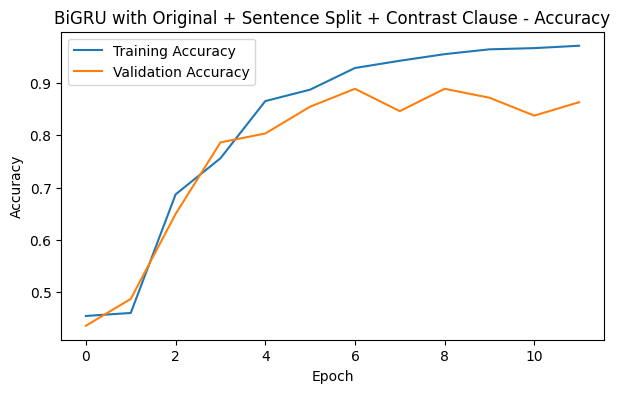

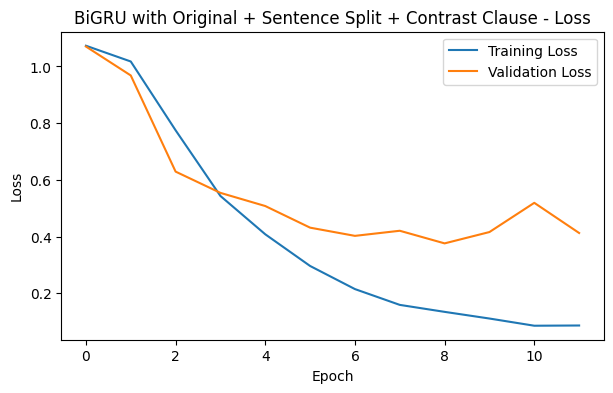

In [114]:
# Step 16.4: Plot improved BiGRU accuracy and loss curves

plt.figure(figsize=(7, 4))
plt.plot(improved_bigru_history.history["accuracy"], label="Training Accuracy")
plt.plot(improved_bigru_history.history["val_accuracy"], label="Validation Accuracy")
plt.title(f"BiGRU with {selected_training_method} + Contrast Clause - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(improved_bigru_history.history["loss"], label="Training Loss")
plt.plot(improved_bigru_history.history["val_loss"], label="Validation Loss")
plt.title(f"BiGRU with {selected_training_method} + Contrast Clause - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [115]:
# Step 16.5: Compare selected BiGRU vs selected BiGRU + contrast clauses

bigru_improvement_comparison_df = pd.DataFrame([
    {
        "Model": "BiGRU + " + selected_training_method,
        "Training Rows": len(X_train_selected),
        "Validation Accuracy": bigru_val_results["Accuracy"],
        "Validation Macro F1": bigru_val_results["Macro F1"],
        "Validation Weighted F1": bigru_val_results["Weighted F1"],
        "Negative Recall": bigru_val_results["Negative Recall"],
        "Neutral Recall": bigru_val_results["Neutral Recall"],
        "Positive Recall": bigru_val_results["Positive Recall"],
        "Long Review Macro F1": bigru_long_val_results["Macro F1"],
        "Contrast Review Macro F1": bigru_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(bigru_training_time, 2)
    },
    {
        "Model": "BiGRU + " + selected_training_method + " + Contrast Clause",
        "Training Rows": len(X_selected_contrast_pad),
        "Validation Accuracy": improved_bigru_val_results["Accuracy"],
        "Validation Macro F1": improved_bigru_val_results["Macro F1"],
        "Validation Weighted F1": improved_bigru_val_results["Weighted F1"],
        "Negative Recall": improved_bigru_val_results["Negative Recall"],
        "Neutral Recall": improved_bigru_val_results["Neutral Recall"],
        "Positive Recall": improved_bigru_val_results["Positive Recall"],
        "Long Review Macro F1": improved_bigru_long_val_results["Macro F1"],
        "Contrast Review Macro F1": improved_bigru_contrast_val_results["Macro F1"],
        "Training Time (sec)": round(improved_bigru_training_time, 2)
    }
])

display(bigru_improvement_comparison_df.round(4))


,Model,Training Rows,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1,Training Time (sec)
0,BiGRU + Original + Sentence Split,822,0.8803,0.8674,0.8784,0.8718,0.7407,0.9608,0.8988,0.9046,5.97
1,BiGRU + Original + Sentence Split + Contrast C...,869,0.8889,0.8775,0.8886,0.8718,0.8148,0.9412,0.9173,0.8585,5.29


**Comparison checkpoint:** This table decides whether contrast clauses improve the selected BiGRU enough to keep.


### 17.1 Contrast-Clause Outcome: Overall Result

The contrast-clause experiment improves the overall validation result.

Before contrast clauses, the BiGRU with Sentence Split gets validation macro F1 **0.8674**.

After adding contrast clauses, validation macro F1 improves to **0.8775**.

This supports keeping the contrast-clause version as a final candidate.


### 17.2 Contrast-Clause Outcome: Trade-Off

The improvement is not perfect.

Long-review macro F1 improves from **0.8988** to **0.9173**, and Neutral recall improves from **0.7407** to **0.8148**.

However, contrast-review macro F1 drops from **0.9046** to **0.8585**, and Positive recall drops from **0.9608** to **0.9412**.

So the added contrast clauses help the overall validation task, but they do not fully solve contrast-review reasoning.


### 17.3 Contrast-Clause Decision

Since my main model-selection metric is overall validation Macro F1, selecting the contrast-clause BiGRU is defensible.

However, I should not overclaim it. The model improves overall class balance, especially Neutral recall, but mixed-review reasoning remains a limitation.

Decision: keep the contrast-clause BiGRU as the final candidate.


In [116]:
# Step 17.1: Final improvement decision table

improvement_decision_df = bigru_improvement_comparison_df.copy()

if improved_bigru_val_results["Macro F1"] > bigru_val_results["Macro F1"]:
    improvement_decision_df["Decision"] = [
        "Rejected: contrast-clause version achieved higher validation Macro F1",
        "Selected: validation Macro F1 improved after adding contrast clauses"
    ]
else:
    improvement_decision_df["Decision"] = [
        "Selected final model",
        "Rejected: contrast clauses did not improve validation Macro F1 overall"
    ]

display(improvement_decision_df.round(4))


,Model,Training Rows,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1,Training Time (sec),Decision
0,BiGRU + Original + Sentence Split,822,0.8803,0.8674,0.8784,0.8718,0.7407,0.9608,0.8988,0.9046,5.97,Rejected: contrast-clause version achieved hig...
1,BiGRU + Original + Sentence Split + Contrast C...,869,0.8889,0.8775,0.8886,0.8718,0.8148,0.9412,0.9173,0.8585,5.29,Selected: validation Macro F1 improved after a...


## 18. Regression Comparison

Although I selected classification as the main task, I still test regression because the original target is a numeric score.

This is a useful check. If regression performs reasonably, then I should not claim that regression is impossible or wrong.


### 18.1 Regression Test Setup

The regression model predicts a continuous score using a single output value.

I compare it against a simple mean-score baseline using:

- **MAE**, which shows the average absolute score error;
- **RMSE**, which penalises larger score errors more strongly.

My expectation is not that regression will fail. My expectation is that regression may be less directly useful for sentiment analysis because a numeric prediction still needs interpretation before it becomes an action.


In [117]:
# Step 17.1: Compare regression model against a mean-score baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import Markdown, display as display_markdown

y_train_score = train_df["Score_Numeric"].astype(float).values
y_val_score = val_df["Score_Numeric"].astype(float).values

mean_score = np.mean(y_train_score)
mean_baseline_pred = np.full_like(y_val_score, fill_value=mean_score, dtype=float)

mean_baseline_mae = mean_absolute_error(y_val_score, mean_baseline_pred)
mean_baseline_rmse = np.sqrt(mean_squared_error(y_val_score, mean_baseline_pred))

regression_model = Sequential()
regression_model.add(Embedding(input_dim=MAX_WORDS, output_dim=64, input_length=MAX_LEN))
regression_model.add(Bidirectional(GRU(32)))
regression_model.add(Dropout(0.4))
regression_model.add(Dense(16, activation="relu"))
regression_model.add(Dense(1, activation="linear"))

regression_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

regression_history = regression_model.fit(
    X_train_pad,
    y_train_score,
    validation_data=(X_val_pad, y_val_score),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=1
)

val_score_pred = regression_model.predict(X_val_pad, verbose=0).ravel()

regression_model_mae = mean_absolute_error(y_val_score, val_score_pred)
regression_model_rmse = np.sqrt(mean_squared_error(y_val_score, val_score_pred))

regression_comparison_df = pd.DataFrame([
    {
        "Model": "Mean Score Baseline",
        "Validation MAE": mean_baseline_mae,
        "Validation RMSE": mean_baseline_rmse
    },
    {
        "Model": "RNN Regression Model",
        "Validation MAE": regression_model_mae,
        "Validation RMSE": regression_model_rmse
    }
])

display(regression_comparison_df.round(4))

if regression_model_mae < mean_baseline_mae:
    regression_message = (
        f"The RNN regression model improves over the mean-score baseline "
        f"({regression_model_mae:.4f} MAE vs {mean_baseline_mae:.4f} MAE). "
        f"However, classification is still easier to interpret for the final review-analysis task."
    )
else:
    regression_message = (
        f"The RNN regression model does not clearly beat the mean-score baseline "
        f"({regression_model_mae:.4f} MAE vs {mean_baseline_mae:.4f} MAE). "
        f"This supports using classification as the main task."
    )

display_markdown(Markdown("**Regression decision:** " + regression_message))


Epoch 1/15
18/18 [==============================] - 2s 35ms/step - loss: 42.5943 - mae: 5.4802 - val_loss: 32.8004 - val_mae: 4.8423
Epoch 2/15
18/18 [==============================] - 0s 11ms/step - loss: 20.6345 - mae: 3.8356 - val_loss: 14.6322 - val_mae: 3.1240
Epoch 3/15
18/18 [==============================] - 0s 11ms/step - loss: 13.2481 - mae: 3.0806 - val_loss: 10.5678 - val_mae: 2.8516
Epoch 4/15
18/18 [==============================] - 0s 10ms/step - loss: 8.6998 - mae: 2.5406 - val_loss: 7.7724 - val_mae: 2.2597
Epoch 5/15
18/18 [==============================] - 0s 10ms/step - loss: 6.2913 - mae: 2.0071 - val_loss: 6.3958 - val_mae: 2.0670
Epoch 6/15
18/18 [==============================] - 0s 9ms/step - loss: 5.0802 - mae: 1.7664 - val_loss: 5.0824 - val_mae: 1.7610
Epoch 7/15
18/18 [==============================] - 0s 10ms/step - loss: 4.1814 - mae: 1.5991 - val_loss: 4.3059 - val_mae: 1.6184
Epoch 8/15
18/18 [==============================] - 0s 10ms/step - loss: 3.427

,Model,Validation MAE,Validation RMSE
0,Mean Score Baseline,3.1098,3.5721
1,RNN Regression Model,1.3830,1.8010


**Regression decision:** The RNN regression model improves over the mean-score baseline (1.3830 MAE vs 3.1098 MAE). However, classification is still easier to interpret for the final review-analysis task.

**Regression check:** This result shows whether score prediction is possible, even if classification remains clearer.


### 18.2 Regression Comparison Outcome: Result

The regression model performs much better than the simple mean-score baseline.

The mean-score baseline has:

- MAE: **3.1098**
- RMSE: **3.5721**

The RNN regression model has:

- MAE: **1.3830**
- RMSE: **1.8010**

This means regression is a valid modelling option. It learns useful signal from the review text and is clearly better than guessing the average score.


### 18.3 Regression Outcome: Why Classification Still Stays

Even though regression works, I still keep classification as the main task because the final project objective is sentiment analysis, not exact score forecasting.

The classification model gives probabilities for Negative, Neutral and Positive through Softmax. That makes the output easier to interpret and easier to evaluate with Macro F1, class recall and confusion matrices.


### 18.4 Regression Outcome: Final Decision

A predicted score such as **6.4** still needs to be converted into a category before the pizza store can decide whether the review is a complaint, a mixed review, or a positive review.

Decision: regression is useful supporting evidence, but 3-class classification remains the final modelling approach.


In [118]:
# Step 17.2: Store final selected model

if improved_bigru_val_results["Macro F1"] > bigru_val_results["Macro F1"]:
    final_model = improved_bigru_model
    final_model_name = "BiGRU + " + selected_training_method + " + Contrast Clause"
    final_val_results = improved_bigru_val_results
    final_val_pred = improved_bigru_val_pred
    final_val_prob = improved_bigru_val_prob
    final_long_val_results = improved_bigru_long_val_results
    final_contrast_val_results = improved_bigru_contrast_val_results
else:
    final_model = bigru_model
    final_model_name = "BiGRU + " + selected_training_method
    final_val_results = bigru_val_results
    final_val_pred = bigru_val_pred
    final_val_prob = bigru_val_prob
    final_long_val_results = bigru_long_val_results
    final_contrast_val_results = bigru_contrast_val_results

print("Final selected model:", final_model_name)
print("Selected training method:", selected_training_method)
print("Final validation Macro F1:", round(final_val_results["Macro F1"], 4))
print("Final validation accuracy:", round(final_val_results["Accuracy"], 4))
print("Long Review Macro F1:", round(final_long_val_results["Macro F1"], 4))
print("Contrast Review Macro F1:", round(final_contrast_val_results["Macro F1"], 4))


Final selected model: BiGRU + Original + Sentence Split + Contrast Clause
Selected training method: Original + Sentence Split
Final validation Macro F1: 0.8775
Final validation accuracy: 0.8889
Long Review Macro F1: 0.9173
Contrast Review Macro F1: 0.8585


## 19. Final Model Selection

Now I choose the final model.

This decision must be made using validation evidence only. The test set is still untouched at this point.

The next table compares the candidate models using validation metrics, class recall, hard-subset performance and training time. This is the evidence I use before moving to the final test.


In [119]:
# Step 18.1: Final model selection table

final_model_selection_df = architecture_comparison_df.copy()

contrast_candidate_row = {
    "Model": "BiGRU + Contrast Clause",
    "Training Method": selected_training_method + " + Contrast Clause",
    "Validation Accuracy": improved_bigru_val_results["Accuracy"],
    "Validation Macro F1": improved_bigru_val_results["Macro F1"],
    "Validation Weighted F1": improved_bigru_val_results["Weighted F1"],
    "Negative Recall": improved_bigru_val_results["Negative Recall"],
    "Neutral Recall": improved_bigru_val_results["Neutral Recall"],
    "Positive Recall": improved_bigru_val_results["Positive Recall"],
    "Long Review Macro F1": improved_bigru_long_val_results["Macro F1"],
    "Contrast Review Macro F1": improved_bigru_contrast_val_results["Macro F1"],
    "Training Time (sec)": round(improved_bigru_training_time, 2)
}

final_model_selection_df = pd.concat(
    [final_model_selection_df, pd.DataFrame([contrast_candidate_row])],
    ignore_index=True
)

final_model_selection_df = final_model_selection_df.sort_values(
    by=["Validation Macro F1", "Long Review Macro F1", "Contrast Review Macro F1"],
    ascending=False
)

def model_decision(row):
    model_label = str(row["Model"])
    training_label = str(row["Training Method"])
    contrast_selected = final_model_name.endswith("+ Contrast Clause")

    if contrast_selected and model_label == "BiGRU + Contrast Clause":
        return "Selected final model"

    if (not contrast_selected) and model_label == "BiGRU" and training_label == selected_training_method:
        return "Selected final model"

    if model_label == "SimpleRNN":
        return "Rejected: lower validation Macro F1 than final BiGRU"
    elif model_label == "LSTM":
        return "Rejected: weaker validation performance"
    elif model_label == "GRU":
        return "Rejected: weak class balance"
    elif "Contrast" in model_label:
        return "Rejected: did not beat selected BiGRU on validation Macro F1"
    else:
        return "Rejected"

final_model_selection_df["Decision"] = final_model_selection_df.apply(model_decision, axis=1)

display(final_model_selection_df.round(4))


,Model,Training Method,Validation Accuracy,Validation Macro F1,Validation Weighted F1,Negative Recall,Neutral Recall,Positive Recall,Long Review Macro F1,Contrast Review Macro F1,Training Time (sec),Decision
4,BiGRU + Contrast Clause,Original + Sentence Split + Contrast Clause,0.8889,0.8775,0.8886,0.8718,0.8148,0.9412,0.9173,0.8585,5.29,Selected final model
0,BiGRU,Original + Sentence Split,0.8803,0.8674,0.8784,0.8718,0.7407,0.9608,0.8988,0.9046,5.97,Rejected
1,SimpleRNN,Original + Sentence Split,0.8462,0.8371,0.8458,0.7949,0.8148,0.9020,0.7511,0.7754,6.89,Rejected: lower validation Macro F1 than final...
2,LSTM,Original + Sentence Split,0.7009,0.5300,0.6235,0.9231,0.0000,0.9020,0.4450,0.3294,4.27,Rejected: weaker validation performance
3,GRU,Original + Sentence Split,0.4359,0.2024,0.2647,0.0000,0.0000,1.0000,0.2751,0.0714,1.94,Rejected: weak class balance


**Selection table:** This is the validation-only evidence used before touching the final test set.


In [120]:
# Step 18.2: Store final selected model

if improved_bigru_val_results["Macro F1"] > bigru_val_results["Macro F1"]:
    final_model = improved_bigru_model
    final_model_name = "BiGRU + " + selected_training_method + " + Contrast Clause"
    final_val_results = improved_bigru_val_results
    final_val_pred = improved_bigru_val_pred
    final_val_prob = improved_bigru_val_prob
    final_long_val_results = improved_bigru_long_val_results
    final_contrast_val_results = improved_bigru_contrast_val_results
else:
    final_model = bigru_model
    final_model_name = "BiGRU + " + selected_training_method
    final_val_results = bigru_val_results
    final_val_pred = bigru_val_pred
    final_val_prob = bigru_val_prob
    final_long_val_results = bigru_long_val_results
    final_contrast_val_results = bigru_contrast_val_results

print("Final selected model:", final_model_name)
print("Selected training method:", selected_training_method)
print("Final validation Macro F1:", round(final_val_results["Macro F1"], 4))
print("Final validation accuracy:", round(final_val_results["Accuracy"], 4))
print("Long Review Macro F1:", round(final_long_val_results["Macro F1"], 4))
print("Contrast Review Macro F1:", round(final_contrast_val_results["Macro F1"], 4))


Final selected model: BiGRU + Original + Sentence Split + Contrast Clause
Selected training method: Original + Sentence Split
Final validation Macro F1: 0.8775
Final validation accuracy: 0.8889
Long Review Macro F1: 0.9173
Contrast Review Macro F1: 0.8585


### 19.1 Final Model Decision: Validation Winner

After checking the validation comparison table, the selected model is **BiGRU + Original + Sentence Split + Contrast Clause**.

It has the best validation macro F1:

- Final selected model macro F1: **0.8775**
- BiGRU with Sentence Split macro F1: **0.8674**
- SimpleRNN with Sentence Split macro F1: **0.8371**
- LSTM macro F1: **0.5300**
- GRU macro F1: **0.2024**


### 19.2 Final Model Decision: Honest Trade-Off

The choice is not perfect.

The contrast-clause model improves overall validation Macro F1, validation accuracy, weighted F1, Neutral recall and long-review macro F1.

But contrast-review macro F1 drops from **0.9046** to **0.8585**.

So I choose it because it is the best overall validation model, while still admitting that mixed-review reasoning remains a limitation.


## 20. Final Test Evaluation

The model has already been selected, so now I use the test set.

This is the first time the test set is used for final reporting.

The test set answers:

> How well does my selected model perform on unseen reviews?

I report accuracy, macro F1, weighted F1, class recall, confusion matrix, and classification report. This is better than reporting only accuracy because the classes are not perfectly balanced.


In [121]:
# Step 19.1: Evaluate final BiGRU model on test set

final_test_results, final_test_pred, final_test_prob = evaluate_three_class_model(
    final_model,
    X_test_pad,
    y_test,
    dataset_name="Final Test"
)

final_test_results_df = pd.DataFrame([final_test_results])

display(final_test_results_df.round(4))


,Dataset,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1,Negative Recall,Neutral Recall,Positive Recall
0,Final Test,0.9153,0.9027,0.9031,0.9026,0.9157,0.9153,0.9152,0.8718,0.8571,0.9804


In [122]:
# Step 19.2: Final test confusion matrix

final_test_cm = confusion_matrix(
    y_test,
    final_test_pred,
    labels=[0, 1, 2]
)

final_test_cm_df = pd.DataFrame(
    final_test_cm,
    index=["Actual Negative", "Actual Neutral", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Neutral", "Predicted Positive"]
)

print("Final Test Confusion Matrix:")
display(final_test_cm_df)


Final Test Confusion Matrix:


,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,34,5,0
Actual Neutral,2,24,2
Actual Positive,1,0,50


**Confusion matrix checkpoint:** Now I can see which sentiment pairs the final model still confuses.


In [123]:
# Step 19.3: Normalised final test confusion matrix

final_test_cm_normalised = final_test_cm.astype("float") / final_test_cm.sum(axis=1)[:, np.newaxis]

final_test_cm_normalised_df = pd.DataFrame(
    final_test_cm_normalised,
    index=["Actual Negative", "Actual Neutral", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Neutral", "Predicted Positive"]
)

print("Final Test Normalised Confusion Matrix:")
display(final_test_cm_normalised_df.round(4))


Final Test Normalised Confusion Matrix:


,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,0.8718,0.1282,0.0000
Actual Neutral,0.0714,0.8571,0.0714
Actual Positive,0.0196,0.0000,0.9804


**Normalised view:** This makes class errors easier to compare even when class counts are different.


In [124]:
# Step 19.4: Final test classification report

print("Final Test Classification Report:")
print(
    classification_report(
        y_test,
        final_test_pred,
        target_names=LABEL_NAMES,
        zero_division=0
    )
)


Final Test Classification Report:
              precision    recall  f1-score   support

    Negative       0.92      0.87      0.89        39
     Neutral       0.83      0.86      0.84        28
    Positive       0.96      0.98      0.97        51

    accuracy                           0.92       118
   macro avg       0.90      0.90      0.90       118
weighted avg       0.92      0.92      0.92       118



**Report checkpoint:** Precision, recall and F1 give a fuller view than accuracy alone.


In [125]:
# Step 19.5: Compare validation and final test performance

validation_test_comparison_df = pd.DataFrame([
    {
        "Dataset": "Validation",
        "Accuracy": final_val_results["Accuracy"],
        "Macro F1": final_val_results["Macro F1"],
        "Weighted F1": final_val_results["Weighted F1"],
        "Negative Recall": final_val_results["Negative Recall"],
        "Neutral Recall": final_val_results["Neutral Recall"],
        "Positive Recall": final_val_results["Positive Recall"]
    },
    {
        "Dataset": "Final Test",
        "Accuracy": final_test_results["Accuracy"],
        "Macro F1": final_test_results["Macro F1"],
        "Weighted F1": final_test_results["Weighted F1"],
        "Negative Recall": final_test_results["Negative Recall"],
        "Neutral Recall": final_test_results["Neutral Recall"],
        "Positive Recall": final_test_results["Positive Recall"]
    }
])

display(validation_test_comparison_df.round(4))


,Dataset,Accuracy,Macro F1,Weighted F1,Negative Recall,Neutral Recall,Positive Recall
0,Validation,0.8889,0.8775,0.8886,0.8718,0.8148,0.9412
1,Final Test,0.9153,0.9026,0.9152,0.8718,0.8571,0.9804


### 20.1 Final Test Interpretation: Main Result

The final test result is strong:

- Test accuracy: **91.53%**
- Test macro F1: **0.9026**
- Test weighted F1: **0.9152**

The test macro F1 is higher than the validation macro F1 of **0.8775**. This suggests that the selected model generalises well to unseen reviews in this split.


### 20.2 Final Test Interpretation: Class-Level View

The class recalls are:

- Negative recall: **0.8718**
- Neutral recall: **0.8571**
- Positive recall: **0.9804**

Positive reviews are still the easiest class. Negative and Neutral reviews remain harder, but their recall values are still acceptable.


## 21. Error Analysis

Now I inspect the mistakes.

Metrics tell me how many predictions are wrong. Error examples tell me why they may be wrong.

This is important because text sentiment can be messy. Some reviews are short, some are translated, and some contain mixed wording. A model may also be confused when the score and wording do not perfectly match.

So I look at the actual wrong predictions instead of hiding them.


In [126]:
# Step 20.1: Create final test prediction dataframe

test_analysis_df = test_df.copy()

test_analysis_df["Actual_Label"] = y_test
test_analysis_df["Predicted_Label"] = final_test_pred

test_analysis_df["Actual_Sentiment"] = test_analysis_df["Actual_Label"].map({
    0: "Negative",
    1: "Neutral",
    2: "Positive"
})

test_analysis_df["Predicted_Sentiment"] = test_analysis_df["Predicted_Label"].map({
    0: "Negative",
    1: "Neutral",
    2: "Positive"
})

test_analysis_df["Negative_Probability"] = final_test_prob[:, 0]
test_analysis_df["Neutral_Probability"] = final_test_prob[:, 1]
test_analysis_df["Positive_Probability"] = final_test_prob[:, 2]

test_analysis_df["Prediction_Confidence"] = np.max(final_test_prob, axis=1)

test_analysis_df["Correct_Prediction"] = (
    test_analysis_df["Actual_Label"] == test_analysis_df["Predicted_Label"]
)

display(
    test_analysis_df[
        [
            "Review_Text",
            "Review_Translated",
            "Score_Numeric",
            "Language_Clean",
            "Actual_Sentiment",
            "Predicted_Sentiment",
            "Prediction_Confidence",
            "Correct_Prediction"
        ]
    ].head(10)
)


,Review_Text,Review_Translated,Score_Numeric,Language_Clean,Actual_Sentiment,Predicted_Sentiment,Prediction_Confidence,Correct_Prediction
417,Rasa mayo dan sambal yang unik buat pizza ni s...,The unique taste of mayo and sambal makes this...,9.9950,Malay,Positive,Positive,0.999854,True
176,Fusion pizza ni buat saya kecewa.,This fusion pizza made me disappointed.,0.1100,Malay,Negative,Negative,0.745433,True
673,The fusion flavors were mild and forgettable.,The fusion flavors were mild and forgettable.,5.6500,English,Neutral,Neutral,0.962058,True
373,Pizza ni sangat enak dan tak pernah mengecewakan.,This pizza is very tasty and never disappoints.,9.9650,Malay,Positive,Positive,0.913659,True
160,Fusion flavors were mild and didn’t stand out.,Fusion flavors were mild and didn’t stand out.,5.2000,English,Neutral,Neutral,0.993514,True
765,Unpleasant aftertaste.,Unpleasant aftertaste.,0.4200,English,Negative,Negative,0.954473,True
258,Mayo made the pizza creamy but didn’t add bold...,Mayo made the pizza creamy but didn’t add bold...,5.5000,English,Neutral,Neutral,0.986716,True
713,The sambal sauce gave just the right amount of...,The sambal sauce gave just the right amount of...,9.4000,English,Positive,Positive,0.999369,True
204,Fusion pizza yang sangat unik dan lazat.,Very unique and delicious fusion pizza.,9.5700,Malay,Positive,Positive,0.999979,True
492,Roti keras dan topping tidak cukup segar.,The bread is hard and the toppings are not fre...,3.6125,Malay,Negative,Negative,0.872925,True


In [127]:
# Step 20.2: Count correct and wrong predictions

correct_count = test_analysis_df["Correct_Prediction"].sum()
wrong_count = len(test_analysis_df) - correct_count

print("Total test rows:", len(test_analysis_df))
print("Correct predictions:", correct_count)
print("Wrong predictions:", wrong_count)
print("Error rate:", round(wrong_count / len(test_analysis_df), 4))


Total test rows: 118
Correct predictions: 108
Wrong predictions: 10
Error rate: 0.0847


**Error count checkpoint:** Now I know the size of the mistake pool before inspecting examples.


In [128]:
# Step 20.3: Show wrong prediction examples

wrong_predictions_df = test_analysis_df[
    test_analysis_df["Correct_Prediction"] == False
].copy()

wrong_predictions_df = wrong_predictions_df.sort_values(
    by="Prediction_Confidence",
    ascending=False
)

display(
    wrong_predictions_df[
        [
            "Review_Text",
            "Review_Translated",
            "Score_Numeric",
            "Language_Clean",
            "Actual_Sentiment",
            "Predicted_Sentiment",
            "Prediction_Confidence",
            "Negative_Probability",
            "Neutral_Probability",
            "Positive_Probability"
        ]
    ]
)


,Review_Text,Review_Translated,Score_Numeric,Language_Clean,Actual_Sentiment,Predicted_Sentiment,Prediction_Confidence,Negative_Probability,Neutral_Probability,Positive_Probability
51,"Biasa-biasa saja, pizza fusion ni. Rasa sambal...","Ordinary, this fusion pizza. The taste of samb...",4.900,Malay,Negative,Neutral,0.995151,0.003776,0.995151,0.001074
623,Tak mengecewakan.,Not disappointing.,5.350,Malay,Neutral,Negative,0.985100,0.985100,0.013320,0.001580
549,Satay chicken had this soft smokiness that fel...,Satay chicken had this soft smokiness that fel...,0.770,English,Negative,Neutral,0.982274,0.006558,0.982274,0.011167
171,Fusion pizza lacked flavor.,Fusion pizza lacked flavor.,0.610,English,Negative,Neutral,0.946921,0.030582,0.946921,0.022496
568,Satay was a nice idea but too subtle.,Satay was a nice idea but too subtle.,5.150,English,Neutral,Positive,0.926974,0.006044,0.066983,0.926974
246,Like nasi lemak crashed into an Italian kitche...,Like nasi lemak crashed into an Italian kitche...,6.575,English,Neutral,Negative,0.870972,0.870972,0.040077,0.088951
440,"Rasa pizza kurang menarik, boleh diperbaiki.","The taste of the pizza is not interesting, can...",4.015,Malay,Negative,Neutral,0.766277,0.221812,0.766277,0.011911
499,Roti kurang lembut dan topping tidak cukup.,The bread is not soft and the toppings are not...,4.525,Malay,Negative,Neutral,0.677882,0.289589,0.677882,0.032529
666,"The crust was good, but the fusion toppings co...","The crust was good, but the fusion toppings co...",5.150,English,Neutral,Positive,0.641916,0.113097,0.244987,0.641916
159,"Fusion done right — spicy, sweet, and savory a...","Fusion done right — spicy, sweet, and savory a...",9.750,English,Positive,Negative,0.529301,0.529301,0.035458,0.435241


**Example checkpoint:** The wrong reviews show what the metrics cannot explain by themselves.


In [129]:
# Step 20.4: Summarise mistake patterns

mistake_pattern_df = (
    wrong_predictions_df
    .groupby(["Actual_Sentiment", "Predicted_Sentiment"])
    .size()
    .reset_index(name="Mistake_Count")
    .sort_values(by="Mistake_Count", ascending=False)
)

display(mistake_pattern_df)


,Actual_Sentiment,Predicted_Sentiment,Mistake_Count
0,Negative,Neutral,5
1,Neutral,Negative,2
2,Neutral,Positive,2
3,Positive,Negative,1


In [130]:
# Step 20.5: Error rate by actual sentiment class

class_error_summary_df = (
    test_analysis_df
    .groupby("Actual_Sentiment")
    .agg(
        Total_Reviews=("Correct_Prediction", "size"),
        Wrong_Predictions=("Correct_Prediction", lambda x: (~x).sum())
    )
    .reset_index()
)

class_error_summary_df["Error_Rate"] = (
    class_error_summary_df["Wrong_Predictions"] / class_error_summary_df["Total_Reviews"]
)

display(class_error_summary_df.round(4))


,Actual_Sentiment,Total_Reviews,Wrong_Predictions,Error_Rate
0,Negative,39,5,0.1282
1,Neutral,28,4,0.1429
2,Positive,51,1,0.0196


**Class error checkpoint:** This tells me which true sentiment is hardest for the model.


In [131]:
# Step 20.6: Error rate by original language

language_error_summary_df = (
    test_analysis_df
    .groupby("Language_Clean")
    .agg(
        Total_Reviews=("Correct_Prediction", "size"),
        Wrong_Predictions=("Correct_Prediction", lambda x: (~x).sum())
    )
    .reset_index()
)

language_error_summary_df["Error_Rate"] = (
    language_error_summary_df["Wrong_Predictions"] / language_error_summary_df["Total_Reviews"]
)

display(language_error_summary_df.round(4))


,Language_Clean,Total_Reviews,Wrong_Predictions,Error_Rate
0,English,76,6,0.0789
1,Malay,42,4,0.0952


**Language error checkpoint:** This checks whether translated Malay-origin reviews remain slightly harder.


### 21.1 Error Analysis Interpretation: What Went Wrong

The final test set has **118 reviews**.

The model gets **108 correct** and **10 wrong**, giving an error rate of about **8.47%**.

The most common mistake is **Negative predicted as Neutral**, which happens **5 times**. This means the model sometimes softens negative reviews instead of recognising them as clearly negative.


### 21.2 Error Analysis Interpretation: Remaining Weak Areas

By class, the error rates are:

- Negative: **12.82%**
- Neutral: **14.29%**
- Positive: **1.96%**

This means Positive reviews are much easier for the model than Negative or Neutral reviews.

By language, English reviews have an error rate of **7.89%**, while Malay-origin reviews have an error rate of **9.52%**.

Decision: discuss Negative/Neutral confusion and Malay-origin errors as remaining limitations.


## 22. Confidence Analysis

Finally, I check model confidence.

Confidence tells me how sure the model is when it predicts a class.

This matters because there are two very different types of mistakes:

1. The model is unsure and wrong.
2. The model is confident and wrong.

The second type is more dangerous because the model sounds certain even when it made a mistake.

So I compare confidence for correct and wrong predictions, and I also check confidence by sentiment class.


In [132]:
# Step 21.1: Compare prediction confidence for correct and wrong predictions

confidence_summary_df = (
    test_analysis_df
    .groupby("Correct_Prediction")
    .agg(
        Count=("Prediction_Confidence", "size"),
        Mean_Confidence=("Prediction_Confidence", "mean"),
        Min_Confidence=("Prediction_Confidence", "min"),
        Max_Confidence=("Prediction_Confidence", "max")
    )
    .reset_index()
)

confidence_summary_df["Prediction_Result"] = confidence_summary_df["Correct_Prediction"].map({
    True: "Correct",
    False: "Wrong"
})

confidence_summary_df = confidence_summary_df[
    ["Prediction_Result", "Count", "Mean_Confidence", "Min_Confidence", "Max_Confidence"]
]

display(confidence_summary_df.round(4))


,Prediction_Result,Count,Mean_Confidence,Min_Confidence,Max_Confidence
0,Wrong,10,0.8323,0.5293,0.9952
1,Correct,108,0.9466,0.4701,1.0000


**Confidence checkpoint:** I compare correct and wrong confidence to see whether mistakes are uncertain or overconfident.


In [133]:
# Step 21.2: Confidence by actual sentiment class

class_confidence_df = (
    test_analysis_df
    .groupby("Actual_Sentiment")
    .agg(
        Total_Reviews=("Prediction_Confidence", "size"),
        Accuracy=("Correct_Prediction", "mean"),
        Mean_Confidence=("Prediction_Confidence", "mean")
    )
    .reset_index()
)

display(class_confidence_df.round(4))


,Actual_Sentiment,Total_Reviews,Accuracy,Mean_Confidence
0,Negative,39,0.8718,0.9052
1,Neutral,28,0.8571,0.9281
2,Positive,51,0.9804,0.9659


In [134]:
# Step 21.3: Most confident wrong predictions

most_confident_wrong_df = wrong_predictions_df.sort_values(
    by="Prediction_Confidence",
    ascending=False
)

display(
    most_confident_wrong_df[
        [
            "Review_Text",
            "Review_Translated",
            "Score_Numeric",
            "Language_Clean",
            "Actual_Sentiment",
            "Predicted_Sentiment",
            "Prediction_Confidence",
            "Negative_Probability",
            "Neutral_Probability",
            "Positive_Probability"
        ]
    ].head(10).round(4)
)


,Review_Text,Review_Translated,Score_Numeric,Language_Clean,Actual_Sentiment,Predicted_Sentiment,Prediction_Confidence,Negative_Probability,Neutral_Probability,Positive_Probability
51,"Biasa-biasa saja, pizza fusion ni. Rasa sambal...","Ordinary, this fusion pizza. The taste of samb...",4.900,Malay,Negative,Neutral,0.9952,0.0038,0.9952,0.0011
623,Tak mengecewakan.,Not disappointing.,5.350,Malay,Neutral,Negative,0.9851,0.9851,0.0133,0.0016
549,Satay chicken had this soft smokiness that fel...,Satay chicken had this soft smokiness that fel...,0.770,English,Negative,Neutral,0.9823,0.0066,0.9823,0.0112
171,Fusion pizza lacked flavor.,Fusion pizza lacked flavor.,0.610,English,Negative,Neutral,0.9469,0.0306,0.9469,0.0225
568,Satay was a nice idea but too subtle.,Satay was a nice idea but too subtle.,5.150,English,Neutral,Positive,0.9270,0.0060,0.0670,0.9270
246,Like nasi lemak crashed into an Italian kitche...,Like nasi lemak crashed into an Italian kitche...,6.575,English,Neutral,Negative,0.8710,0.8710,0.0401,0.0890
440,"Rasa pizza kurang menarik, boleh diperbaiki.","The taste of the pizza is not interesting, can...",4.015,Malay,Negative,Neutral,0.7663,0.2218,0.7663,0.0119
499,Roti kurang lembut dan topping tidak cukup.,The bread is not soft and the toppings are not...,4.525,Malay,Negative,Neutral,0.6779,0.2896,0.6779,0.0325
666,"The crust was good, but the fusion toppings co...","The crust was good, but the fusion toppings co...",5.150,English,Neutral,Positive,0.6419,0.1131,0.2450,0.6419
159,"Fusion done right — spicy, sweet, and savory a...","Fusion done right — spicy, sweet, and savory a...",9.750,English,Positive,Negative,0.5293,0.5293,0.0355,0.4352


**Risk checkpoint:** High-confidence mistakes matter because the model sounds certain while still being wrong.


In [135]:
# Step 21.4: Lowest confidence predictions

lowest_confidence_df = test_analysis_df.sort_values(
    by="Prediction_Confidence",
    ascending=True
)

display(
    lowest_confidence_df[
        [
            "Review_Text",
            "Review_Translated",
            "Score_Numeric",
            "Language_Clean",
            "Actual_Sentiment",
            "Predicted_Sentiment",
            "Prediction_Confidence",
            "Negative_Probability",
            "Neutral_Probability",
            "Positive_Probability",
            "Correct_Prediction"
        ]
    ].head(10).round(4)
)


,Review_Text,Review_Translated,Score_Numeric,Language_Clean,Actual_Sentiment,Predicted_Sentiment,Prediction_Confidence,Negative_Probability,Neutral_Probability,Positive_Probability,Correct_Prediction
726,The satay topping was unexpectedly wonderful —...,The satay topping was unexpectedly wonderful —...,9.700,English,Positive,Positive,0.4701,0.0621,0.4678,0.4701,True
159,"Fusion done right — spicy, sweet, and savory a...","Fusion done right — spicy, sweet, and savory a...",9.750,English,Positive,Negative,0.5293,0.5293,0.0355,0.4352,False
615,Tak ada rasa langsung.,There is no direct taste.,0.200,Malay,Negative,Negative,0.5315,0.5315,0.4617,0.0068,True
666,"The crust was good, but the fusion toppings co...","The crust was good, but the fusion toppings co...",5.150,English,Neutral,Positive,0.6419,0.1131,0.2450,0.6419,False
753,Too spicy.,Too spicy.,3.750,English,Negative,Negative,0.6574,0.6574,0.0562,0.2863,True
499,Roti kurang lembut dan topping tidak cukup.,The bread is not soft and the toppings are not...,4.525,Malay,Negative,Neutral,0.6779,0.2896,0.6779,0.0325,False
26,Agak okay.,Pretty okay.,5.800,Malay,Neutral,Neutral,0.7199,0.2246,0.7199,0.0555,True
176,Fusion pizza ni buat saya kecewa.,This fusion pizza made me disappointed.,0.110,Malay,Negative,Negative,0.7454,0.7454,0.2259,0.0287,True
686,The mayo was too plain for my taste.,The mayo was too plain for my taste.,5.050,English,Neutral,Neutral,0.7579,0.2354,0.7579,0.0067,True
440,"Rasa pizza kurang menarik, boleh diperbaiki.","The taste of the pizza is not interesting, can...",4.015,Malay,Negative,Neutral,0.7663,0.2218,0.7663,0.0119,False


In [136]:
# Step 21.5: Confidence bucket analysis

def confidence_bucket(confidence):
    if confidence < 0.50:
        return "Below 0.50"
    elif confidence < 0.70:
        return "0.50 to 0.69"
    elif confidence < 0.90:
        return "0.70 to 0.89"
    else:
        return "0.90 and above"

test_analysis_df["Confidence_Bucket"] = test_analysis_df["Prediction_Confidence"].apply(confidence_bucket)

bucket_summary_df = (
    test_analysis_df
    .groupby("Confidence_Bucket")
    .agg(
        Total_Reviews=("Correct_Prediction", "size"),
        Correct_Reviews=("Correct_Prediction", "sum")
    )
    .reset_index()
)

bucket_summary_df["Accuracy"] = (
    bucket_summary_df["Correct_Reviews"] / bucket_summary_df["Total_Reviews"]
)

bucket_order = ["Below 0.50", "0.50 to 0.69", "0.70 to 0.89", "0.90 and above"]

bucket_summary_df["Confidence_Bucket"] = pd.Categorical(
    bucket_summary_df["Confidence_Bucket"],
    categories=bucket_order,
    ordered=True
)

bucket_summary_df = bucket_summary_df.sort_values("Confidence_Bucket")

display(bucket_summary_df.round(4))


,Confidence_Bucket,Total_Reviews,Correct_Reviews,Accuracy
3,Below 0.50,1,1,1.0000
0,0.50 to 0.69,5,2,0.4000
1,0.70 to 0.89,14,12,0.8571
2,0.90 and above,98,93,0.9490


**Confidence bucket checkpoint:** Grouping confidence scores shows when predictions are more trustworthy or need review.


### 22.1 Confidence Analysis Interpretation: Confidence Pattern

Correct predictions have higher average confidence (**0.9466**) than wrong predictions (**0.8323**).

This is a good sign because the model is usually more confident when it is correct.

However, wrong predictions can still be very confident. The maximum confidence among wrong predictions is **0.9952**, which means the model can sometimes be very sure and still be wrong.


### 22.2 Confidence Analysis Interpretation: How I Would Use This

The confidence bucket analysis shows:

- Confidence above **0.90** has **94.90%** accuracy.
- Confidence between **0.70 and 0.89** has **85.71%** accuracy.
- Confidence between **0.50 and 0.69** has **40.00%** accuracy.
- The single prediction below **0.50** is correct, but one example is too small to draw a strong conclusion.

So confidence is useful, but not perfect. In a real review system, low-confidence predictions and high-confidence edge-case mistakes should be reviewed more carefully.


## 23. Final Discussion

This notebook shows that the final result did not come from simply training one model and reporting accuracy.

I first cleaned the dataset because the raw scores, language labels and repeated reviews were messy. Then I framed the task as **3-class classification** because the aim is sentiment analysis, not exact score forecasting.


### 23.1 What Worked Best

The SimpleRNN baseline was decent with validation macro F1 **0.8209**, but it struggled more on long and contrast reviews.

Data generation helped in this rerun. **Original + Sentence Split** improved validation macro F1 to **0.8371**, so I used it for the next modelling stage.

The tuned BiGRU was the strongest architecture. It handled the review sequence better than LSTM and GRU in this dataset.


### 23.2 What I Rejected and Why

LSTM and GRU did not work well in this run.

LSTM missed the Neutral class completely, and GRU collapsed toward Positive predictions. These failures are useful because they show that a more advanced model name does not automatically mean better performance.

The language experiment showed that keeping translated Malay reviews was useful. English + translated Malay achieved validation macro F1 **0.8608**, while English-only achieved **0.7144**.


### 23.3 Final Model and Limitation

The final improvement was contrast-clause augmentation. It improved validation macro F1 from **0.8674** to **0.8775**, so I selected **BiGRU + Original + Sentence Split + Contrast Clause** as the final model.

This final choice has a trade-off. The contrast-clause model improves the overall validation task, Neutral recall and long-review performance, but it performs worse on the contrast-review subset.

On the final unseen test set, the model achieved **91.53% accuracy** and **0.9026 macro F1**.

Overall, the workflow is evidence-based: every major decision was checked, interpreted and either kept or rejected based on results.


## 24. Practical Value for a Pizza Store

Beyond the model scores, this project shows how sentiment analysis can help a pizza store turn customer feedback into clearer action.

The model can organise reviews into **Negative**, **Neutral**, and **Positive** sentiment groups. This helps the store identify unhappy reviews earlier, especially when customers mention late delivery, cold food, wrong orders, poor taste, or weak service.


### 24.1 How the Store Could Use My Model

The predictions can help the store understand repeated patterns.

If many Negative or Neutral reviews mention similar problems, the store can see whether customers are mainly complaining about delivery speed, food quality, price, portion size, or staff service.

This turns separate customer comments into evidence for deciding what should be improved.


### 24.2 Practical Limitation

My model should be used as a decision-support tool, not as a full replacement for human judgement.

The error analysis shows that Negative and Neutral reviews are harder to classify, and mixed reviews can still confuse the model. Therefore, uncertain reviews, high-confidence mistakes, and important complaints should still be checked by a person.

Used carefully, the model can help a pizza store respond faster and make improvements based on evidence rather than guesswork.


## 25. Final Weights Saving

After selecting the final Part B model using validation results and confirming it on the test set, I save the final neural network weights as an `.h5` file.

This file is included for submission so the trained model weights can be restored without retraining the whole notebook.

In [137]:
from pathlib import Path

save_folder = Path(r"C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA1")
weights_path = save_folder / "Part_B_Final_BiGRU_Weights.weights.h5"

final_model.save_weights(weights_path)

print("Part B final model weights saved successfully:")
print(weights_path)
print("Selected model:", final_model_name)

Part B final model weights saved successfully:
C:\Users\USER\OneDrive - Singapore Polytechnic\DELE\CA1\Part_B_Final_BiGRU_Weights.weights.h5
Selected model: BiGRU + Original + Sentence Split + Contrast Clause
